# Segmentasi Pelanggan Zahir
Notebook ini mengikuti data dari pemeriksaan Excel sampai pembentukan RFM eksploratif. Jalankan seluruh sel dari root proyek dengan `venv_segmentasi_zahir`; identitas asli tetap tersimpan untuk penelusuran, tetapi output hanya agregat atau contoh ber-ID samaran.

| Satuan | Cara membacanya |
|---|---|
| Baris item | Satu baris sumber; beberapa baris dapat berasal dari satu faktur |
| Kelompok nomor faktur | Baris dengan nomor asli yang sama, dikumpulkan untuk pemeriksaan; belum pasti satu faktur bisnis |
| Label pelanggan sementara | Nama klien setelah kapital/spasinya diseragamkan; bukan ID pelanggan tervalidasi |

# Tahap 1 — Eksplorasi Data Awal
## Membaca struktur Excel
Sel ini memastikan file `data/raw/Data Zahir 20k Data.xlsx`, sheet `faktur_penjualan_zahir (2)`, dan 12 kolom wajib tersedia. `df_raw` menyimpan isi asli, sedangkan salinannya dipakai untuk diagnosis. `Shape` pada output menunjukkan jumlah baris dan kolom yang berhasil dimuat.

In [1]:
from pathlib import Path
from datetime import datetime, date
import re
import io
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML

ROOT = Path.cwd().resolve()
SOURCE = ROOT / 'data' / 'raw' / 'Data Zahir 20k Data.xlsx'
SHEET = 'faktur_penjualan_zahir (2)'
REQUIRED = ['no_faktur', 'tanggal', 'nama_klien', 'contact_person', 'no_telepon',
            'nama_produk', 'qty', 'unit', 'harga_satuan', 'diskon_pct',
            'subtotal_produk', 'grand_total_faktur']
if not SOURCE.is_file():
    raise FileNotFoundError(f'Workbook tidak ditemukan: {SOURCE}. Jalankan notebook dari root repo.')
workbook_raw = pd.ExcelFile(SOURCE, engine='openpyxl')
if SHEET not in workbook_raw.sheet_names:
    raise ValueError(f'Sheet wajib {SHEET!r} tidak ditemukan. Periksa workbook sumber.')
df_raw = pd.read_excel(workbook_raw, sheet_name=SHEET)
missing_columns = sorted(set(REQUIRED) - set(df_raw.columns))
if missing_columns:
    raise ValueError(f'Kolom wajib tidak tersedia: {missing_columns}')
raw_snapshot = df_raw.copy(deep=True)
d = df_raw.copy(deep=True)
print('Interpreter:', sys.executable)
print('Sumber relatif:', SOURCE.relative_to(ROOT), '| Sheet:', SHEET)
print('Shape:', df_raw.shape)

def desimal_id(v):
    return f'{float(v):,.2f}'.replace(',', '_').replace('.', ',').replace('_', '.')

Interpreter: D:\FILE KULIAH\semester 5\magang\zahir_customer_segmentation\zahir-customer-segmentation\venv_segmentasi_zahir\Scripts\python.exe
Sumber relatif: data\raw\Data Zahir 20k Data.xlsx | Sheet: faktur_penjualan_zahir (2)
Shape: (22086, 12)


Workbook terbaca sebagai **22.086 baris item dan 12 kolom**. Jumlah item ini menjadi pembagi pada grafik kelengkapan; jumlah transaksi dan label pelanggan perlu dihitung dengan satuan tersendiri setelah pemeriksaan.

## Mengenali kolom dan ukuran nominal
Daftar kolom memperlihatkan tipe penyimpanan dan nilai terisi. `object` dapat memuat campuran teks dan angka, sehingga tanggal atau kuantitas belum tentu siap dihitung.

Pada statistik nominal, satu kolom mewakili satu jenis nilai: `count` adalah nilai terisi, `50%` adalah median, dan `max` adalah nilai terbesar. Tabel identik membedakan semua anggota kelompok baris yang sama dari baris tambahan setelah kemunculan pertama. Pemeriksaan mencakup seluruh kolom asli; belum ada penghapusan item.

In [2]:
SAFE = ['nama_produk', 'qty', 'unit', 'harga_satuan', 'diskon_pct', 'subtotal_produk', 'grand_total_faktur']

buf = io.StringIO()
df_raw.info(buf=buf)
print(buf.getvalue())
display(HTML(df_raw[['harga_satuan', 'subtotal_produk', 'grand_total_faktur']].describe().to_html(float_format=desimal_id)))
def blank(s):
    return s.isna() | s.map(lambda x: isinstance(x, str) and not x.strip())
profile = pd.DataFrame({
    'tipe': df_raw.dtypes.astype(str),
    'unik_terisi_asli': df_raw.nunique(dropna=True),
    'missing_pandas': df_raw.isna().sum(),
    'missing_persen': df_raw.isna().mean().mul(100),
    'kosong_termasuk_spasi': df_raw.apply(lambda s: blank(s).sum())
})

IDENTITY = ['nama_klien', 'contact_person', 'no_telepon', 'no_faktur']

identical_members = int(df_raw.duplicated(keep=False).sum())
identical_extra = int(df_raw.duplicated(keep='first').sum())
display(pd.DataFrame({'ukuran': ['Anggota kelompok baris identik', 'Baris identik tambahan'],
                      'jumlah': [identical_members, identical_extra]}))

<class 'pandas.DataFrame'>
RangeIndex: 22086 entries, 0 to 22085
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   no_faktur           22086 non-null  object 
 1   tanggal             20117 non-null  object 
 2   nama_klien          22086 non-null  str    
 3   contact_person      20714 non-null  object 
 4   no_telepon          15280 non-null  object 
 5   nama_produk         21994 non-null  str    
 6   qty                 21994 non-null  object 
 7   unit                21846 non-null  str    
 8   harga_satuan        21994 non-null  float64
 9   diskon_pct          21994 non-null  object 
 10  subtotal_produk     21994 non-null  float64
 11  grand_total_faktur  21994 non-null  float64
dtypes: float64(3), object(6), str(3)
memory usage: 2.0+ MB



,harga_satuan,subtotal_produk,grand_total_faktur
count,"21.994,00","21.994,00","21.994,00"
mean,"41.529.649.564.828,96","1.665.903,57","8.865.642,38"
std,"1.275.135.759.332.215,25","3.697.291,81","12.746.323,82"
min,"-3.000.000,00","-22.500.000,00","0,00"
25%,"350.000,00","250.000,00","2.294.100,00"
50%,"600.000,00","525.000,00","5.460.000,00"
75%,"1.500.000,00","1.260.000,00","10.250.000,00"
max,"65.333.333.333.333.296,00","109.009.009,01","412.000.000,00"


,ukuran,jumlah
0,Anggota kelompok baris identik,3936
1,Baris identik tambahan,2253


Ditemukan **3.936 anggota kelompok baris identik**, termasuk **2.253 baris tambahan** setelah kemunculan pertama. Ini belum membuktikan baris yang boleh dihapus karena item yang sama bisa sah. Nilai harga terbesar juga jauh dari bagian tengah data; Tahap 2 akan menyimpan penandanya tanpa membuang otomatis.

## Dasar diagnosis faktur dan tanggal
Nomor faktur dikelompokkan menurut nilai asli yang terisi; spasi pada nomor tidak dibersihkan. Nomor kosong dikeluarkan dari pengelompokan dan dihitung sendiri. Jumlah nomor unik bukan jumlah faktur valid.

Tanggal native Excel dipertahankan. Teks ISO dibaca tahun-bulan-hari; teks numerik hari/bulan/tahun dibaca dengan asumsi **day-first**. Teks yang hari dan bulannya sama-sama 1–12 ditandai ambigu meskipun berhasil diparsing. Angka nonkosong tidak otomatis dianggap serial Excel. Format lain yang tidak didukung ditandai gagal untuk ditinjau. Tidak ada nilai tanggal asli yang ditampilkan.

Sel ini menyiapkan `rows_per_invoice` untuk ukuran kelompok nomor dan kolom tanggal diagnostik pada salinan `d`. Hasilnya belum berupa grafik; sel berikutnya memakai kelompok ini untuk membandingkan atribut antarbaris.

In [3]:
invoice_blank = blank(d['no_faktur'])
g = d.loc[~invoice_blank].groupby('no_faktur', sort=False, dropna=False)
rows_per_invoice = g.size()

row_distribution = rows_per_invoice.value_counts().sort_index().rename_axis('baris_per_nomor').to_frame('jumlah_nomor')



def parse_diagnostic(v):
    if pd.isna(v) or (isinstance(v, str) and not v.strip()):
        return pd.NaT, 'kosong', False
    if isinstance(v, (datetime, date, pd.Timestamp)):
        return pd.Timestamp(v), 'native_datetime', False
    if isinstance(v, str):
        s = v.strip()
        if re.fullmatch(r'\d{4}-\d{1,2}-\d{1,2}(?:[ T].*)?', s):
            return pd.to_datetime(s, errors='coerce'), 'teks_ISO', False
        match = re.fullmatch(r'(\d{1,2})[/.-](\d{1,2})[/.-](\d{4})', s)
        if match:
            a, b, y = map(int, match.groups())
            parsed = pd.to_datetime(f'{y:04d}-{b:02d}-{a:02d}', errors='coerce')
            return parsed, 'teks_dayfirst', 1 <= a <= 12 and 1 <= b <= 12
    return pd.NaT, 'format_tidak_didukung', False
parsed = d['tanggal'].map(parse_diagnostic)
d['_tanggal'] = parsed.map(lambda x: x[0])
d['_format_tanggal'] = parsed.map(lambda x: x[1])
d['_ambigu'] = parsed.map(lambda x: x[2])
date_blank = blank(d['tanggal'])
date_failed = ~date_blank & d['_tanggal'].isna()


# Bentuk teks mengungkap format tanpa menampilkan nilai tanggal asli.
text_dates = d.loc[d['tanggal'].map(lambda x: isinstance(x, str)), 'tanggal']

Persiapan menghasilkan **6.665 kelompok nomor terisi**, tanpa nomor kosong. `date_blank` menandai **1.969 item** bertanggal kosong dan `date_failed` menandai **78 item** terisi yang gagal dibaca. Variabel ini akan membedakan kehilangan tanggal dari masalah format pada grafik, lalu dipakai lagi pada cleaning; sel ini memang belum menampilkan grafik.

### Membandingkan atribut dalam kelompok yang sama
Setelah baris dikumpulkan menurut nomor, klien, tanggal terbaca, dan grand total antarbaris dibandingkan. Lebih dari satu nilai terisi pada atribut yang sama disebut konflik; tanggal yang kosong atau gagal dibaca tetap dicatat terpisah.

`conflict_table` dan hitungan pengulangan total akan dipakai pada grafik. Sel ini juga menyiapkan subtotal numerik serta nama produk dengan kapital/spasi yang diseragamkan untuk diagnosis. Belum ada faktur atau produk yang digabungkan.

In [4]:
# Konflik hanya membandingkan nilai terisi. Kosong dan gagal parsing dicatat terpisah.
conflicts = []
for label, source_col, value_col in [('klien', 'nama_klien', 'nama_klien'),
                                      ('tanggal', 'tanggal', '_tanggal'),
                                      ('grand_total', 'grand_total_faktur', 'grand_total_faktur')]:
    values = d[value_col].mask(blank(d[source_col]))
    temp = pd.DataFrame({'nomor': d['no_faktur'], 'nilai': values,
                         'kosong': blank(d[source_col]),
                         'gagal': date_failed if label == 'tanggal' else False}).loc[~invoice_blank]
    grouped = temp.groupby('nomor', sort=False)
    n = grouped['nilai'].nunique()
    has_blank = grouped['kosong'].any()
    has_filled = grouped['nilai'].count().gt(0)
    conflicts.append({'atribut': label, 'konflik_nilai_terisi': int(n.gt(1).sum()),
                      'nomor_dengan_kosong': int(has_blank.sum()),
                      'nomor_kosong_dan_terisi': int((has_blank & has_filled).sum()),
                      'nomor_dengan_gagal_parsing': int(grouped['gagal'].any().sum())})
conflict_table = pd.DataFrame(conflicts).set_index('atribut')

# Pengulangan nilai total pada item: tidak menjumlahkan grand_total_faktur.
total_stats = g['grand_total_faktur'].agg(['count', 'nunique'])
repeated_total_numbers = int((total_stats['count'].gt(total_stats['nunique'])).sum())
same_total_multiline = int((rows_per_invoice.gt(1) & total_stats['nunique'].eq(1) & total_stats['count'].eq(rows_per_invoice)).sum())

subtotal = pd.to_numeric(d['subtotal_produk'], errors='coerce')


product_blank = blank(d['nama_produk'])
products = d.loc[~product_blank, 'nama_produk'].astype(str)
product_norm = products.str.strip().str.replace(r'\s+', ' ', regex=True).str.casefold()
product_pairs = pd.DataFrame({'asli': products, 'normal': product_norm}).drop_duplicates()
variants = product_pairs.groupby('normal')['asli'].nunique()
variant_groups = int(variants.gt(1).sum())
variant_rows = int(product_norm.isin(variants[variants.gt(1)].index).sum())

Konflik klien ditemukan pada **349 kelompok**, tanggal pada **221**, dan grand total pada **301**. Total terisi juga berulang pada **3.618 kelompok**. Karena itu, Tahap 2 perlu memastikan satu total konsisten sebelum dipakai sekali per kelompok; menjumlahkan grand total semua item dapat menggandakan belanja. Nama produk yang diseragamkan di sini baru bahan diagnosis ejaan.

## 1. Kolom apa yang paling banyak kosong?
Persentase memakai seluruh baris item sebagai penyebut. Pola menunjukkan kombinasi kolom kosong pada baris yang sama; kategori tanpa kekosongan ikut dihitung.
Batang diurutkan agar kolom paling kosong mudah ditemukan. Hijau dipakai untuk data lengkap/lolos, jingga untuk kekosongan atau penanda, dan merah untuk konflik/penahanan. Sel ini sekaligus menyiapkan fungsi gambar yang dipakai lagi pada tahap berikutnya.

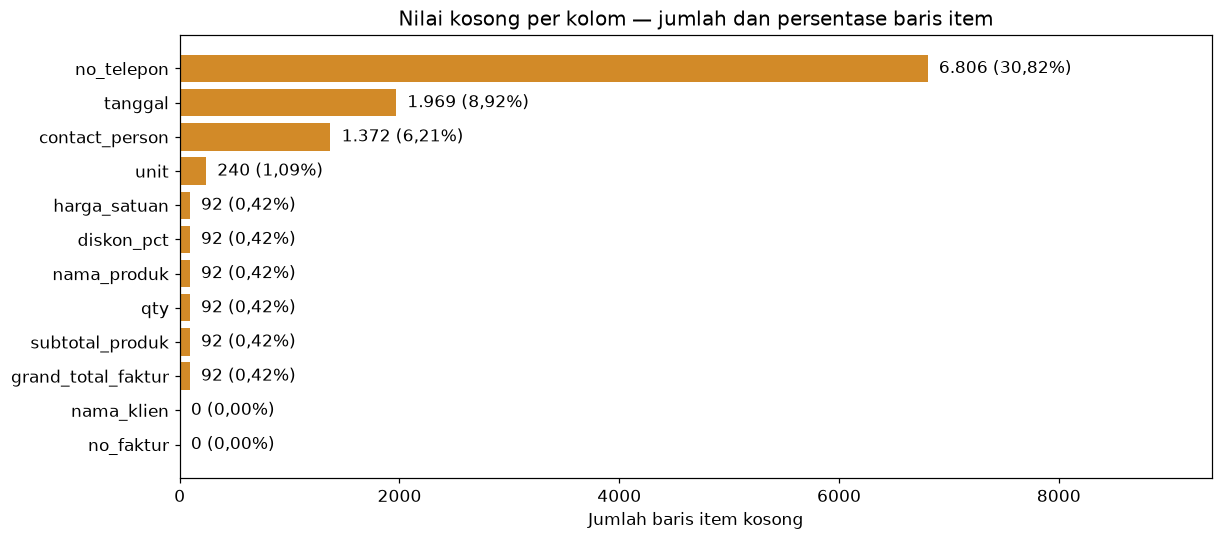

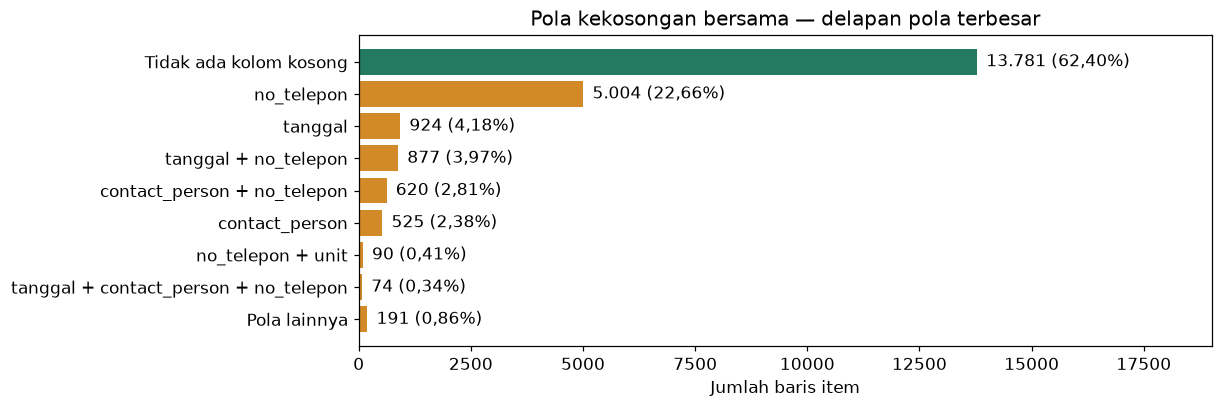

In [5]:
from IPython.display import Markdown
from matplotlib.ticker import FuncFormatter
plt.rcParams.update({'font.size': 11, 'figure.dpi': 110})
GOOD, EMPTY, CONFLICT = '#247a60', '#d28a28', '#bb4545'
N, NI = len(d), len(rows_per_invoice)
def angka(x): return f'{int(x):,}'.replace(',', '.')
def pct(x, den=N): return f'{100*x/den:.2f}%'.replace('.', ',') if den else '0,00%'
def note(s): display(Markdown(s))
def finish(fig):
    display(fig)
    plt.close(fig)
def bars(series, title, xlabel, den=None, color=EMPTY):
    fig, ax = plt.subplots(figsize=(11, max(3.4, len(series)*.40)), layout='constrained')
    ax.barh(range(len(series)), series.values, color=color)
    ax.set_yticks(range(len(series)), series.index.astype(str))
    ax.invert_yaxis()
    ax.set(title=title, xlabel=xlabel)
    limit=max(float(series.max()),1)
    ax.set_xlim(0,limit*1.38)
    for i,v in enumerate(series):
        ax.text(v+limit*.015,i,angka(v)+(f' ({pct(v,den)})' if den is not None else ''),va='center')
    finish(fig)
missing_counts = profile['kosong_termasuk_spasi'].sort_values(ascending=False)
bars(missing_counts, 'Nilai kosong per kolom — jumlah dan persentase baris item', 'Jumlah baris item kosong', N)
missing_mask = d[REQUIRED].apply(blank)
patterns = missing_mask.apply(lambda row: ' + '.join(row.index[row]) or 'Tidak ada kolom kosong', axis=1).value_counts()
# All patterns are retained in an aggregate table; show the largest for legibility.
pattern_plot=patterns.head(8).copy()
if len(patterns)>8: pattern_plot.loc['Pola lainnya']=patterns.iloc[8:].sum()
bars(pattern_plot, 'Pola kekosongan bersama — delapan pola terbesar', 'Jumlah baris item', N, [GOOD if name=='Tidak ada kolom kosong' else EMPTY for name in pattern_plot.index])
worst=missing_counts.index[0]

Kolom paling kosong adalah `no_telepon`: **6.806 dari 22.086 item (30,82%)**. Sebanyak **13.781 item (62,40%)** tidak memiliki kekosongan pada kolom yang diperiksa. Pola kosong bersama membantu melihat informasi apa yang sering hilang bersamaan; isian penting perlu ditelusuri ke sumber sebelum diisi.

## 2. Seberapa sering satu nomor faktur muncul di beberapa baris?
Semua persentase pada kelompok grafik ini memakai nomor faktur unik terisi sebagai penyebut. Konflik menghitung nomor yang memiliki lebih dari satu nilai terisi; kategori konflik bisa tumpang tindih.
Grafik pertama membandingkan banyaknya item per nomor, grafik kedua konflik atribut, dan grafik ketiga pengulangan total. Kategori 6–10 berarti satu nomor memiliki enam sampai sepuluh baris; pengulangan nomor saja belum membuktikan transaksi ganda.

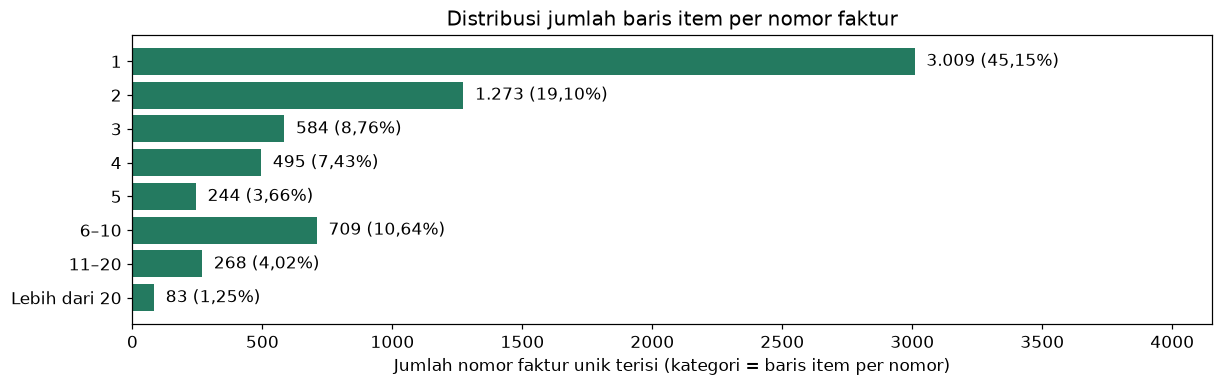

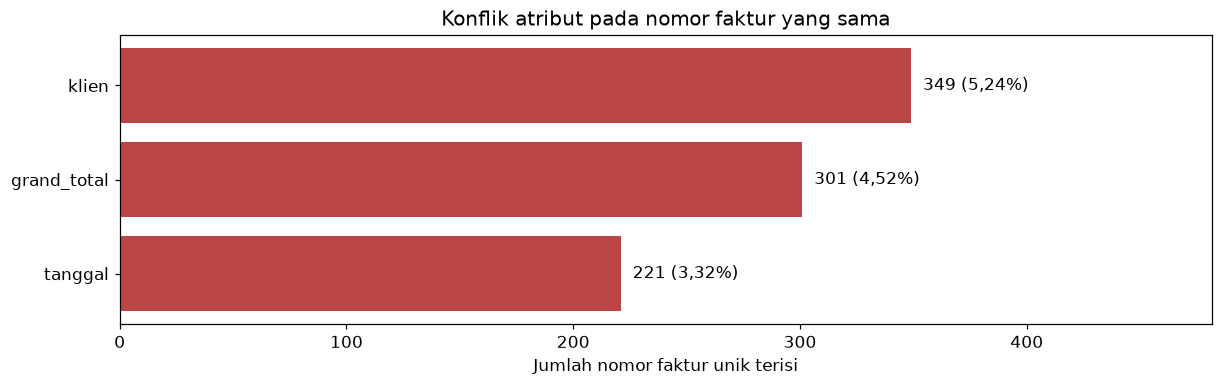

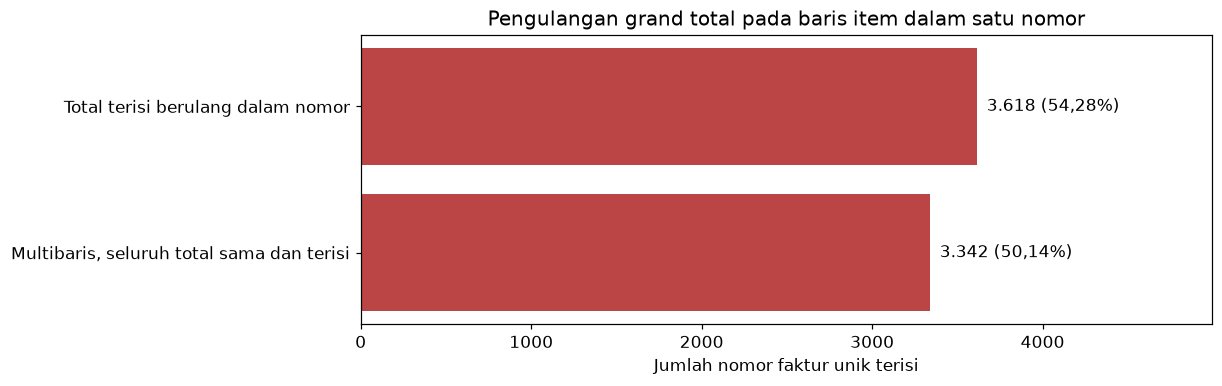

In [6]:
invoice_bins=pd.cut(rows_per_invoice,bins=[0,1,2,3,4,5,10,20,np.inf],labels=['1','2','3','4','5','6–10','11–20','Lebih dari 20']).value_counts(sort=False)
assert invoice_bins.sum()==NI
bars(invoice_bins, 'Distribusi jumlah baris item per nomor faktur', 'Jumlah nomor faktur unik terisi (kategori = baris item per nomor)', NI, GOOD)
bars(conflict_table['konflik_nilai_terisi'].sort_values(ascending=False), 'Konflik atribut pada nomor faktur yang sama', 'Jumlah nomor faktur unik terisi', NI, CONFLICT)
repeat_series=pd.Series({'Total terisi berulang dalam nomor': repeated_total_numbers,
                        'Multibaris, seluruh total sama dan terisi': same_total_multiline})
bars(repeat_series,'Pengulangan grand total pada baris item dalam satu nomor', 'Jumlah nomor faktur unik terisi', NI, CONFLICT)

Sebanyak **3.656 dari 6.665 kelompok (54,85%)** memiliki beberapa item; hal ini dapat berupa faktur multibaris yang wajar. Konflik atribut di dalam kelompok perlu dibedakan dari pengulangan nomor. Total berulang pada **3.618 kelompok (54,28%)** menjelaskan mengapa Monetary nanti memakai satu grand total per kelompok yang lolos.

## 3. Seberapa lengkap dan terbaca tanggal transaksi?
Grafik bulanan mencakup semua baris dengan tanggal berhasil dibaca, termasuk teks ambigu yang dibaca sementara dengan asumsi hari/bulan/tahun. Tanggal kosong dan gagal dibaca tidak masuk; grafik menghitung baris item, bukan jumlah faktur atau penjualan.
Panel dibagi per 36 bulan dengan skala tinggi yang sama. Bulan tanpa item tetap disertakan agar rentang waktu tidak tampak menyambung jika sebenarnya ada jeda.

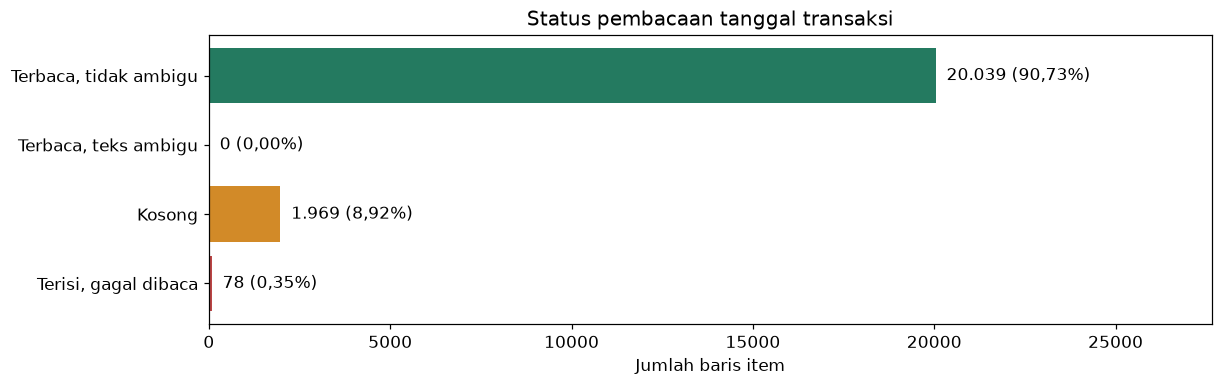

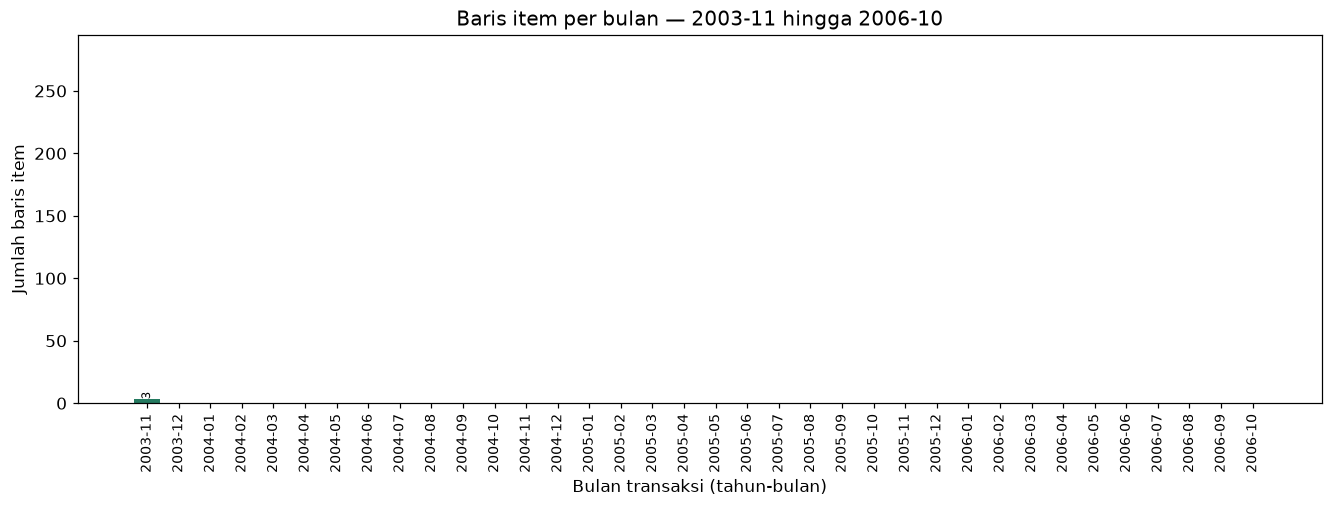

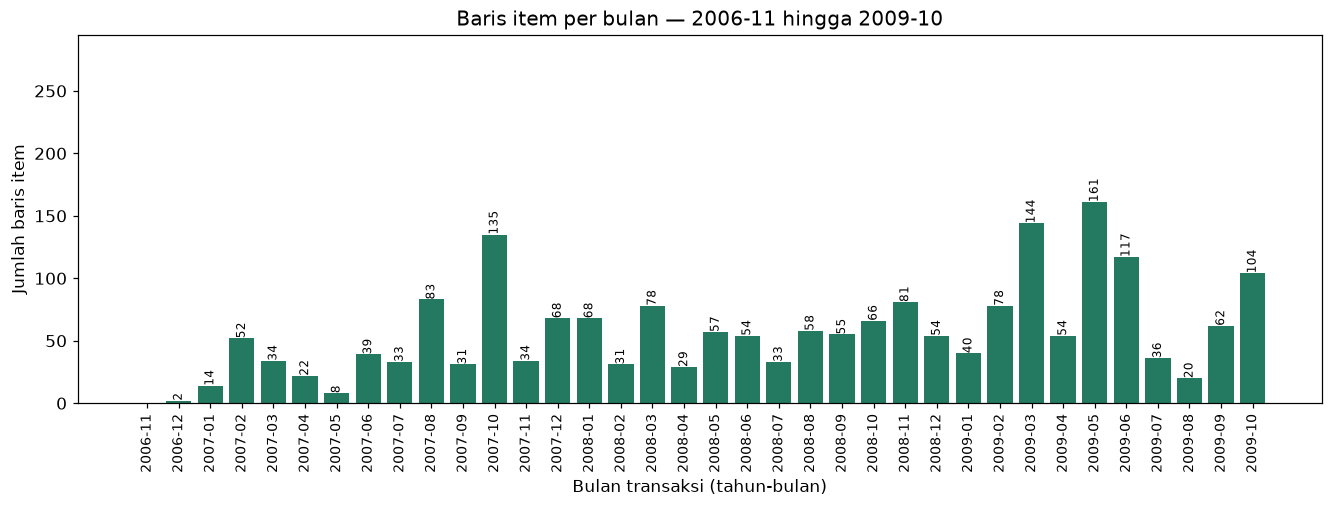

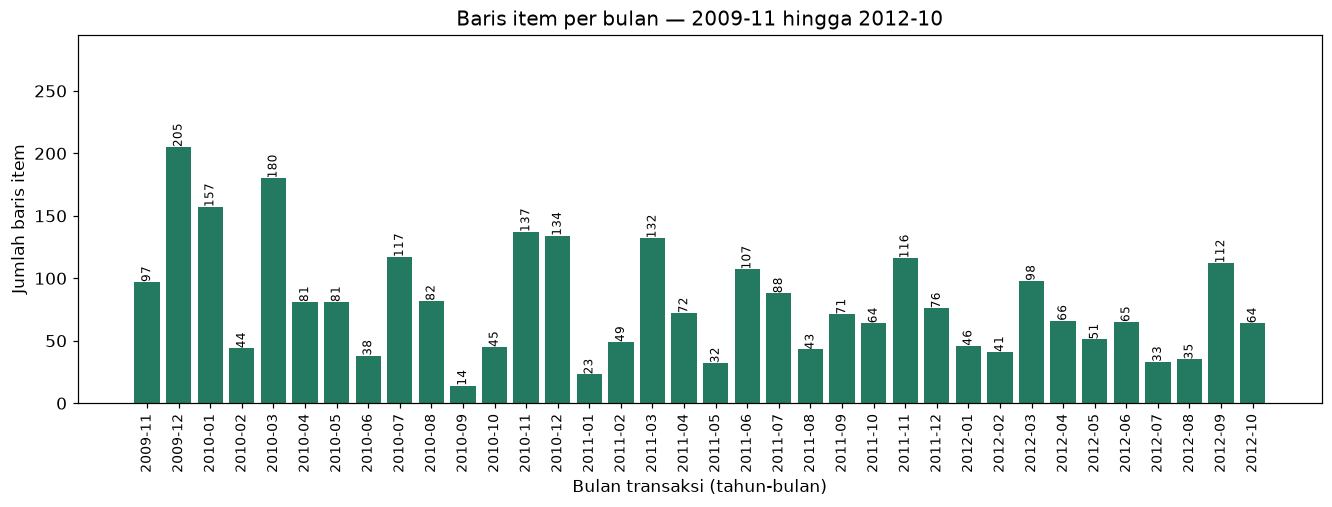

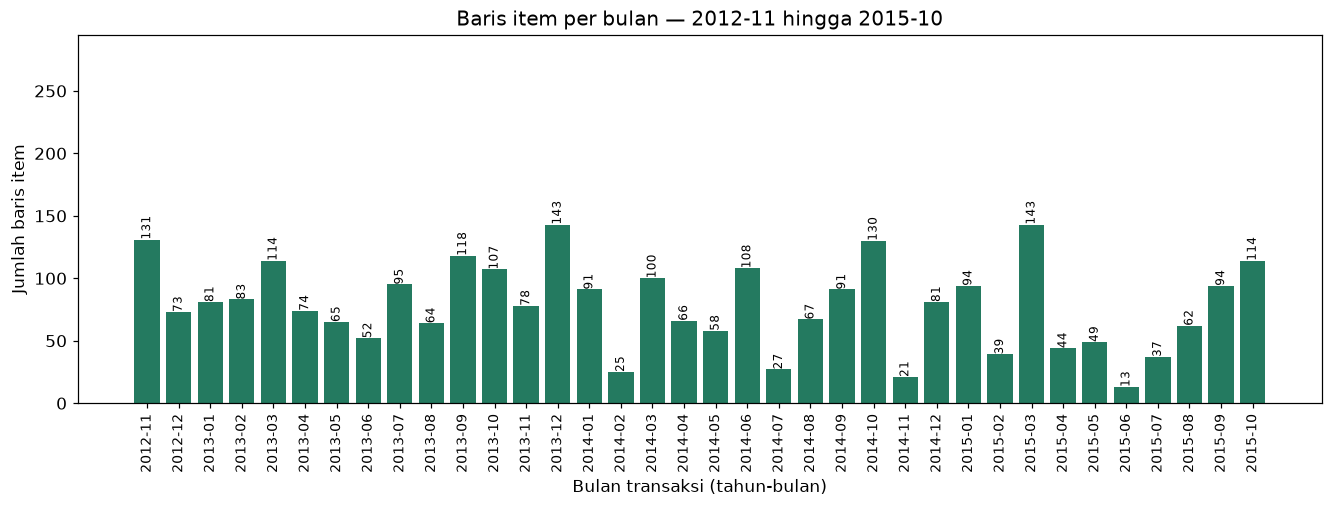

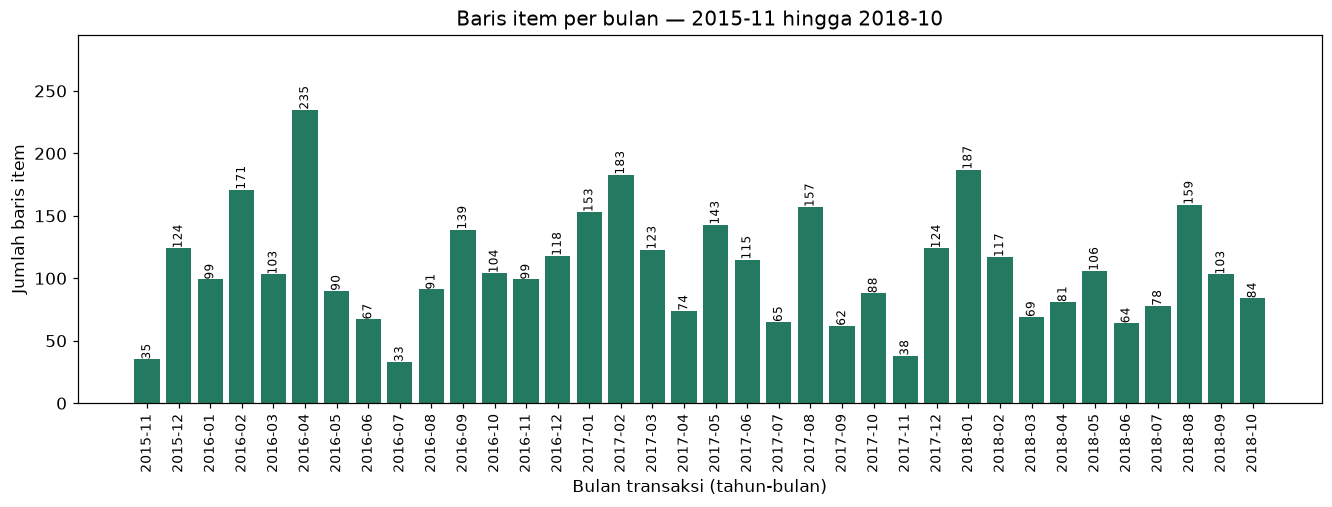

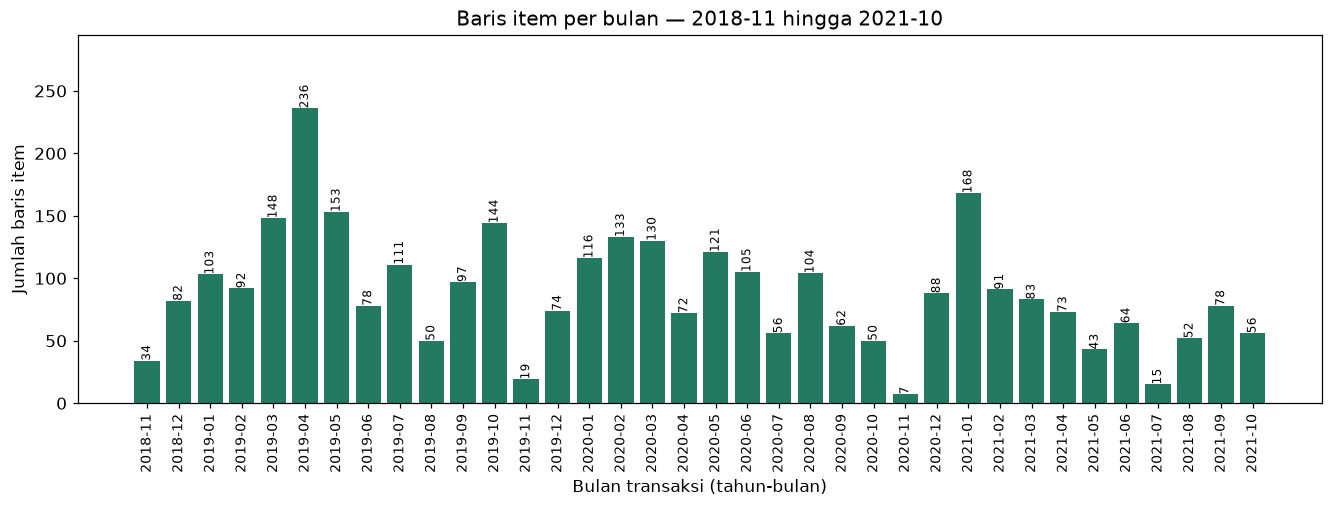

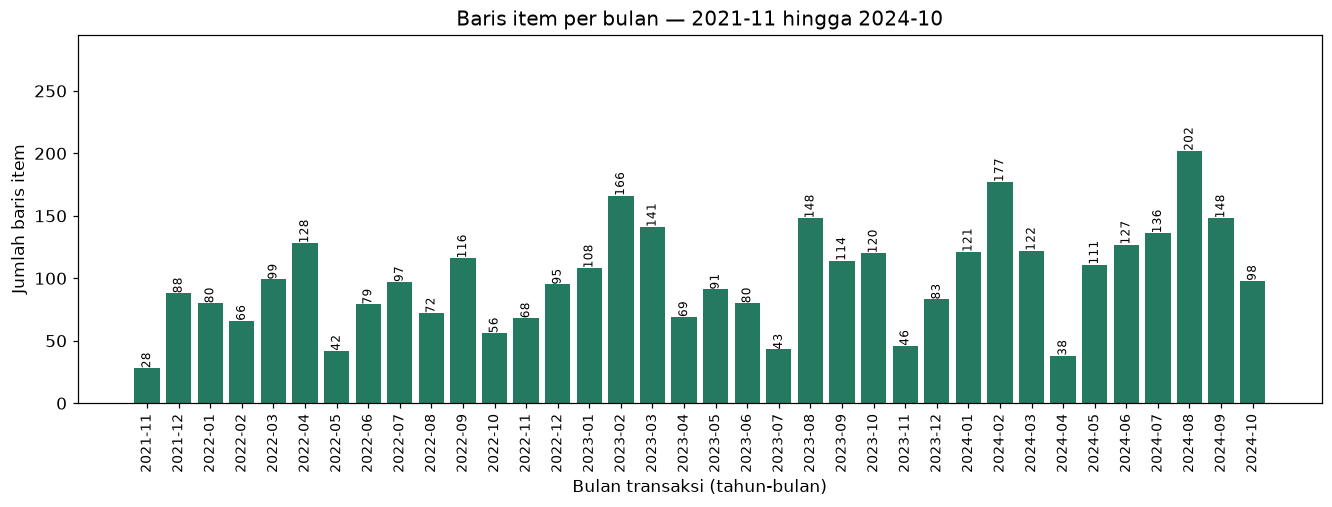

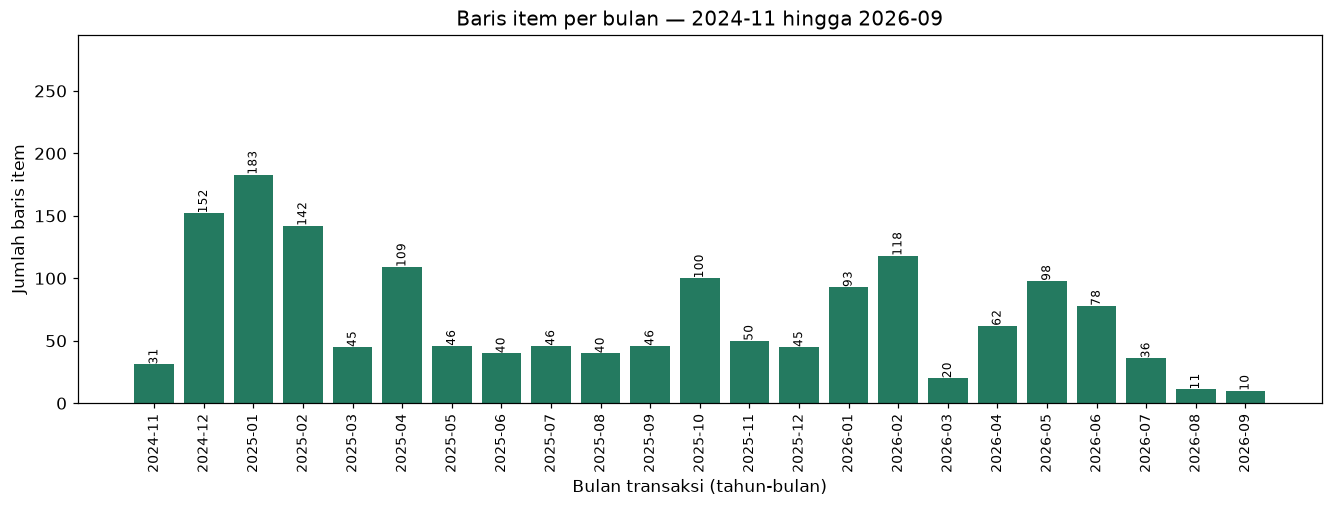

In [7]:
date_status=pd.Series({'Terbaca, tidak ambigu': int((d['_tanggal'].notna() & ~d['_ambigu']).sum()),
                      'Terbaca, teks ambigu': int((d['_tanggal'].notna() & d['_ambigu']).sum()),
                      'Kosong': int(date_blank.sum()), 'Terisi, gagal dibaca': int(date_failed.sum())})
bars(date_status,'Status pembacaan tanggal transaksi', 'Jumlah baris item', N, [GOOD, EMPTY, EMPTY, CONFLICT])
monthly=d.loc[d['_tanggal'].notna(), '_tanggal'].dt.to_period('M').value_counts().sort_index()
monthly=monthly.reindex(pd.period_range(monthly.index.min(),monthly.index.max(),freq='M'),fill_value=0)
# Panels of 36 consecutive months keep labels readable, including zero months.
for start in range(0,len(monthly),36):
    panel=monthly.iloc[start:start+36]
    fig,ax=plt.subplots(figsize=(12,4.5),layout='constrained')
    ax.bar(range(len(panel)),panel.values,color=GOOD)
    ax.set_xticks(range(len(panel)),panel.index.astype(str),rotation=90,fontsize=9)
    ax.set(title=f'Baris item per bulan — {panel.index[0]} hingga {panel.index[-1]}',xlabel='Bulan transaksi (tahun-bulan)',ylabel='Jumlah baris item')
    for i,v in enumerate(panel):
        if v: ax.text(i,v,angka(v),ha='center',va='bottom',rotation=90,fontsize=8)
    ax.set_ylim(0,max(monthly)*1.25)  # same scale in every panel
    finish(fig)

Grafik bulanan mencakup **20.039 item** bertanggal terbaca, dari November 2003 sampai September 2026. **1.969 item (8,92%)** kosong dan **78 (0,35%)** gagal dibaca; tidak ada teks ambigu terdeteksi. Ini masih rentang data mentah, sehingga berbeda dari rentang subset lolos yang menjadi dasar Recency pada Tahap 3.

## 4. Apakah nilai transaksi sangat jauh dari mayoritas?
Subtotal ditampilkan pada tingkat baris item. Sumbu rupiah memakai **symlog**: jarak dekat nol linear (hingga ±Rp1.000), lalu logaritmik; jarak yang sama pada bagian log menunjukkan kelipatan nilai, bukan selisih rupiah yang sama. Kandidat IQR adalah nilai di bawah Q1 − 1,5 × IQR atau di atas Q3 + 1,5 × IQR; dihitung terpisah untuk setiap kolom dari nilai numerik terisi.
Histogram memperlihatkan sebaran subtotal, sedangkan boxplot memperlihatkan bagian tengah dan titik yang jauh darinya. Pada tabel, baca batas IQR bersama jumlah kandidat; persentase batang memakai seluruh baris item, dan tabel juga menyediakan pembagi nilai numerik terisi.

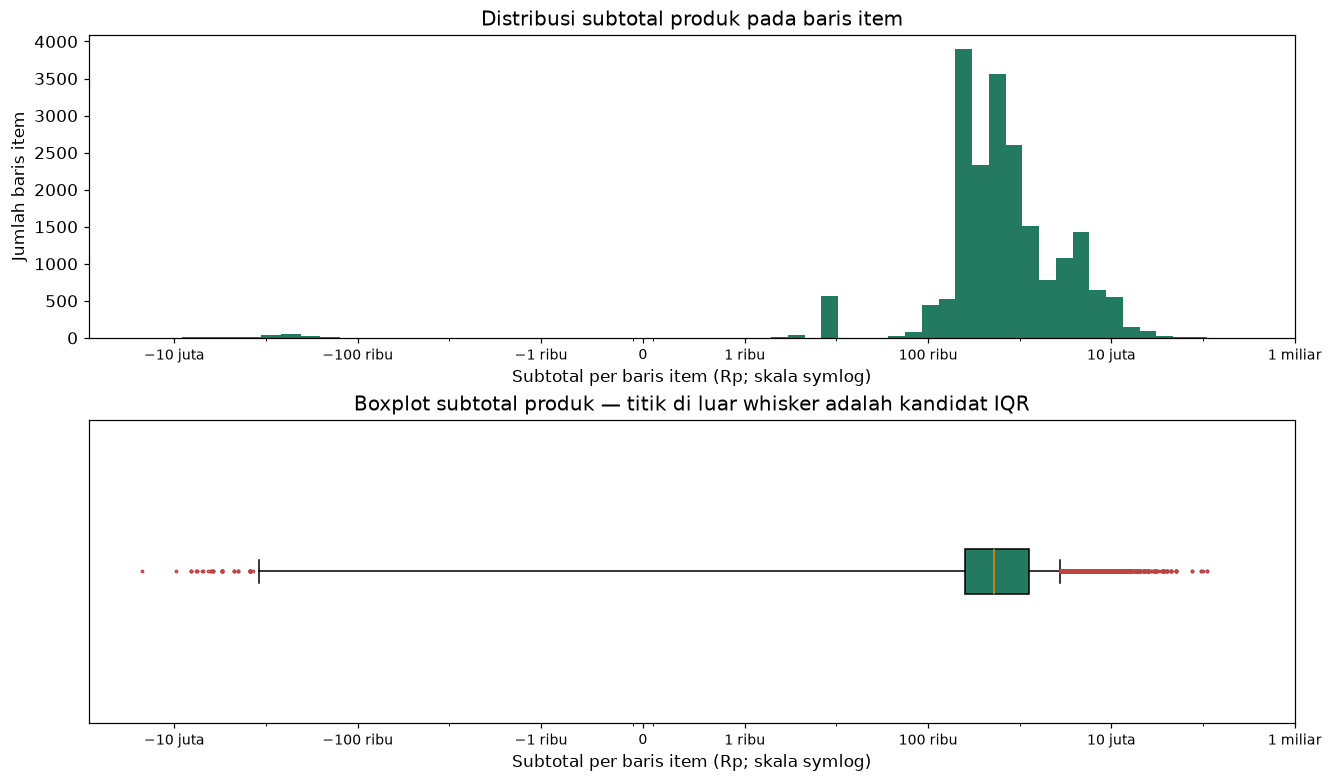

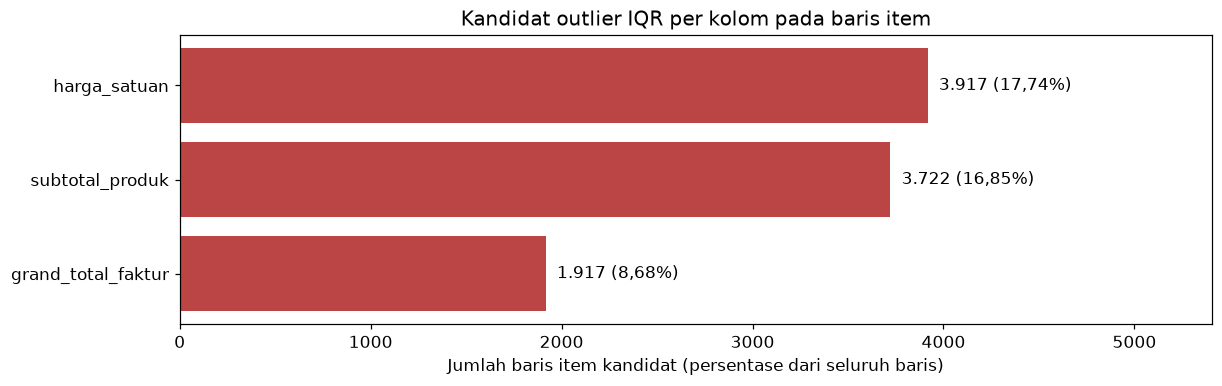

,numerik_terisi,kosong_atau_non_numerik,batas_bawah_Rp,batas_atas_Rp,kandidat_baris,persen_seluruh_baris,persen_numerik_terisi
kolom,,,,,,,
harga_satuan,21994,92,"-1.375.000,00","3.225.000,00",3917,"17,74","17,81"
subtotal_produk,21994,92,"-1.265.000,00","2.775.000,00",3722,"16,85","16,92"
grand_total_faktur,21994,92,"-9.639.750,00","22.183.850,00",1917,"8,68","8,72"


In [8]:
money_cols=['harga_satuan','subtotal_produk','grand_total_faktur']
iqr_rows=[]
for col in money_cols:
    v=pd.to_numeric(d[col],errors='coerce')
    q1,q3=v.quantile([.25,.75]); spread=q3-q1
    low,high=q1-1.5*spread,q3+1.5*spread
    candidates=v.lt(low)|v.gt(high)
    iqr_rows.append({'kolom':col,'numerik_terisi':int(v.notna().sum()),'kosong_atau_non_numerik':int(v.isna().sum()),'batas_bawah_Rp':low,'batas_atas_Rp':high,'kandidat_baris':int(candidates.sum()),'persen_seluruh_baris':100*candidates.sum()/N,'persen_numerik_terisi':100*candidates.sum()/v.notna().sum()})
iqr_table=pd.DataFrame(iqr_rows).set_index('kolom')
fig,axes=plt.subplots(2,1,figsize=(12,7),layout='constrained')
v=subtotal.dropna()
edges=np.unique(np.r_[-np.geomspace(1,max(abs(v.min()),2),35),0,np.geomspace(1,max(v.max(),2),45)])
axes[0].hist(v,bins=edges,color=GOOD)
axes[0].set(title='Distribusi subtotal produk pada baris item',ylabel='Jumlah baris item')
axes[1].boxplot(v,orientation='horizontal',patch_artist=True,boxprops={'facecolor':GOOD},flierprops={'marker':'.','markersize':3,'markeredgecolor':CONFLICT})
axes[1].set(title='Boxplot subtotal produk — titik di luar whisker adalah kandidat IQR',yticks=[])
for ax in axes:
    ax.set_xscale('symlog',linthresh=1000)
    ax.set_xticks([-1e7,-1e5,-1e3,0,1e3,1e5,1e7,1e9])
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x,pos: ('−' if x<0 else '') + (f'{abs(x)/1e9:g} miliar' if abs(x)>=1e9 else f'{abs(x)/1e6:g} juta' if abs(x)>=1e6 else f'{abs(x)/1e3:g} ribu' if abs(x)>=1e3 else '0')))
    ax.tick_params(axis='x',labelsize=9)
    ax.set_xlabel('Subtotal per baris item (Rp; skala symlog)')
finish(fig)
bars(iqr_table['kandidat_baris'].sort_values(ascending=False), 'Kandidat outlier IQR per kolom pada baris item', 'Jumlah baris item kandidat (persentase dari seluruh baris)', N, CONFLICT)
display(HTML(iqr_table.to_html(float_format=desimal_id)))

Kandidat IQR mencakup **3.917 item harga satuan (17,74%)**, **3.722 subtotal (16,85%)**, dan **1.917 grand total (8,68%)**, dengan pembagi 22.086 item. Ada **170 subtotal negatif (0,77%)**. Transaksi besar, retur, atau kesalahan pencatatan masih dugaan penyebab; semua kandidat tetap tersedia sebagai data berpenanda pada cleaning.

## 5. Apakah nama produk siap untuk menghitung keragaman produk?
Normalisasi diagnostik hanya memangkas spasi tepi, merapatkan spasi berulang, dan menyamakan huruf besar/kecil. Ini mengukur indikasi variasi penulisan, belum membuktikan bahwa produk yang berbeda adalah produk yang sama.
Grafik pertama bersatuan baris item, sedangkan grafik kedua bersatuan nama unik/kelompok nama. Angka dari kedua grafik tidak boleh dijumlahkan karena mewakili hal berbeda.

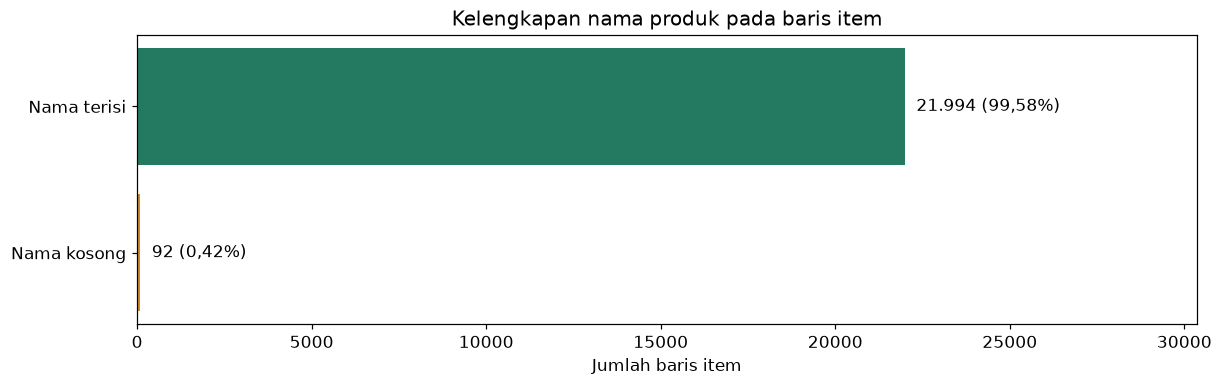

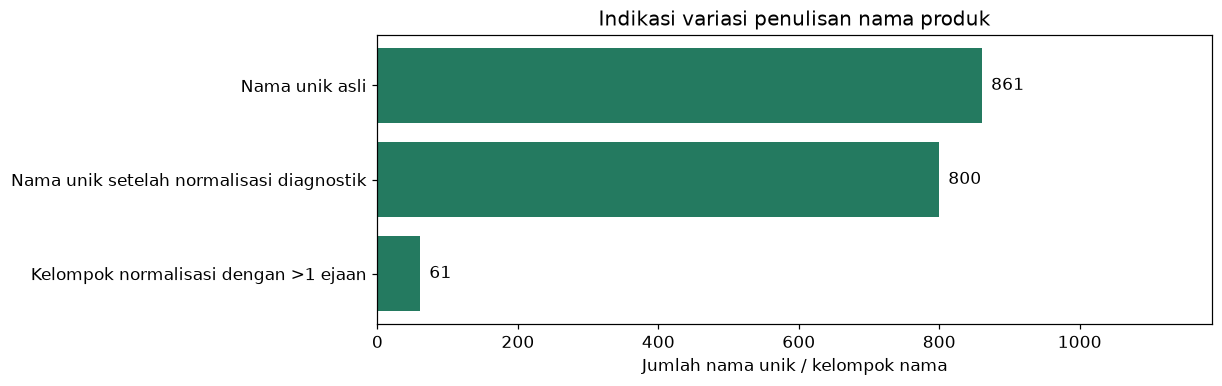

In [9]:
bars(pd.Series({'Nama terisi':int((~product_blank).sum()),'Nama kosong':int(product_blank.sum())}), 'Kelengkapan nama produk pada baris item', 'Jumlah baris item', N, [GOOD,EMPTY])
bars(pd.Series({'Nama unik asli': products.nunique(),'Nama unik setelah normalisasi diagnostik':product_norm.nunique(),'Kelompok normalisasi dengan >1 ejaan':variant_groups}), 'Indikasi variasi penulisan nama produk', 'Jumlah nama unik / kelompok nama', color=GOOD)

Nama produk kosong pada **92 item (0,42% dari 22.086 item)**. Sebanyak **861 nama unik asli** menjadi **800 nama** setelah penyeragaman sederhana, dengan **61 kelompok variasi** yang mencakup 11.438 item. Keragaman nama standar nanti hanya informasi profil karena tanpa kode produk belum tentu sama dengan jumlah produk bisnis yang berbeda.

## Tabel Audit Akhir
Rujukan angka untuk grafik dan narasi. Kasus dapat tumpang tindih sehingga jumlah antarbaris tidak boleh dijumlahkan. Satuan “baris” berarti baris item; “nomor” berarti nomor unik terisi yang belum divalidasi sebagai faktur.
Satu baris tabel adalah satu pemeriksaan. Baca `jumlah_kasus` bersama `unit`, lalu lihat dampak dan validasi yang diperlukan; persentase baris memakai seluruh item dan persentase nomor memakai kelompok nomor terisi. Pemeriksaan akhir memastikan EDA tidak mengubah data mentah, bukan menyatakan semua transaksi benar.

In [10]:
audit_rows = []
def audit(kind, count, unit, impact, action):
    audit_rows.append({'pemeriksaan': kind, 'jumlah_kasus': int(count), 'unit': unit,
                       'dampak_RFM': impact, 'validasi_Tahap_2': action})
audit('Baris identik tambahan', identical_extra, 'baris', 'Potensi penggelembungan nilai/frekuensi', 'Periksa ID item dan bukti sumber sebelum menghapus')
audit('Anggota kelompok identik', identical_members, 'baris', 'Menunjukkan cakupan duplikasi', 'Bedakan item sah dari duplikasi ekstraksi')
audit('Nomor faktur kosong', invoice_blank.sum(), 'baris', 'Frekuensi tidak dapat ditautkan', 'Telusuri nomor atau ID transaksi sumber')
audit('Nomor multibaris', rows_per_invoice.gt(1).sum(), 'nomor', 'Jumlah baris bukan Frequency', 'Validasi grain item dan aturan agregasi')
for label, row in conflict_table.iterrows():
    audit(f'Konflik {label} antar-nilai terisi', row['konflik_nilai_terisi'], 'nomor', 'Identitas/grain atau nilai RFM tidak pasti', 'Periksa ID transaksi, cabang, seri, dan dokumen sumber')
    audit(f'{label}: nomor dengan nilai kosong', row['nomor_dengan_kosong'], 'nomor', 'Atribut RFM tidak lengkap', 'Validasi sumber; jangan isi otomatis')
audit('Tanggal kosong', date_blank.sum(), 'baris', 'Recency tidak tersedia', 'Konfirmasi tanggal transaksi sumber')
audit('Tanggal gagal parsing', date_failed.sum(), 'baris', 'Recency tidak dapat dihitung', 'Periksa format/serial Excel dan lokal sumber')
audit('Tanggal ambigu', d['_ambigu'].sum(), 'baris', 'Recency mungkin bergeser', 'Konfirmasi lokal day-first dengan pemilik data')
audit('Total berulang dalam nomor', repeated_total_numbers, 'nomor', 'Monetary membesar jika total dijumlahkan', 'Rekonsiliasi total faktur dan subtotal item')
audit('Subtotal negatif', subtotal.lt(0).sum(), 'baris', 'Retur/koreksi memengaruhi Monetary', 'Periksa status retur dan pembatalan')
audit('Nama produk kosong', product_blank.sum(), 'baris', 'Interpretasi komposisi belanja terbatas', 'Telusuri kode produk sumber')
audit('Kelompok variasi nama produk', variant_groups, 'kelompok normalisasi', 'Kategori belanja dapat terpecah', 'Validasi kode produk sebelum penggabungan')
for col,row in iqr_table.iterrows():
    audit(f'Kandidat outlier IQR: {col}', row['kandidat_baris'], 'baris', 'Nilai ekstrem dapat memengaruhi Monetary', 'Periksa dokumen; kandidat dapat berupa transaksi sah')
audit('Baris dalam kelompok variasi produk', variant_rows, 'baris', 'Keragaman dapat terpecah', 'Validasi kode produk')
audit('Multibaris dengan seluruh total sama terisi', same_total_multiline, 'nomor', 'Total dapat terhitung berulang', 'Rekonsiliasi nilai faktur')
audit_table = pd.DataFrame(audit_rows)
audit_table['persen_dari_unit_acuan'] = audit_table.apply(lambda r: 100*r['jumlah_kasus']/(N if r['unit']=='baris' else NI) if r['unit'] in ['baris','nomor'] else np.nan,axis=1)
display(HTML(audit_table.to_html(index=False,float_format=desimal_id)))
key_conflicts = int(conflict_table['konflik_nilai_terisi'].sum())
if key_conflicts:
    print('no_faktur belum layak ditetapkan sebagai kunci faktur tunggal: terdapat konflik antar-nilai terisi.')
else:
    print('Belum ada konflik antar-nilai terisi yang terdeteksi, tetapi keunikan bisnis no_faktur tetap perlu dikonfirmasi.')
display(pd.DataFrame({'metrik': ['Jumlah baris mentah', 'Jumlah nomor faktur unik terisi', 'Jumlah faktur valid'],
                      'hasil': [str(len(d)), str(len(rows_per_invoice)), 'Belum ditetapkan; menunggu aturan cleaning dan validasi kunci']}))
assert df_raw.equals(raw_snapshot), 'DataFrame mentah berubah selama diagnosis.'
verification_summary = {'baris_mentah': len(d), 'nomor_unik': len(rows_per_invoice),
                        'identik_tambahan': identical_extra, 'identik_anggota': identical_members,
                        'konflik': conflict_table.to_dict('index'), 'tanggal_kosong': int(date_blank.sum()),
                        'tanggal_gagal': int(date_failed.sum()), 'tanggal_ambigu': int(d['_ambigu'].sum()),
                        'nomor_total_berulang': repeated_total_numbers, 'variasi_produk': variant_groups}
print('Data mentah tetap sama dengan sumber awal.')

pemeriksaan,jumlah_kasus,unit,dampak_RFM,validasi_Tahap_2,persen_dari_unit_acuan
Baris identik tambahan,2253,baris,Potensi penggelembungan nilai/frekuensi,Periksa ID item dan bukti sumber sebelum menghapus,"10,20"
Anggota kelompok identik,3936,baris,Menunjukkan cakupan duplikasi,Bedakan item sah dari duplikasi ekstraksi,"17,82"
Nomor faktur kosong,0,baris,Frekuensi tidak dapat ditautkan,Telusuri nomor atau ID transaksi sumber,"0,00"
Nomor multibaris,3656,nomor,Jumlah baris bukan Frequency,Validasi grain item dan aturan agregasi,"54,85"
Konflik klien antar-nilai terisi,349,nomor,Identitas/grain atau nilai RFM tidak pasti,"Periksa ID transaksi, cabang, seri, dan dokumen sumber","5,24"
klien: nomor dengan nilai kosong,0,nomor,Atribut RFM tidak lengkap,Validasi sumber; jangan isi otomatis,"0,00"
Konflik tanggal antar-nilai terisi,221,nomor,Identitas/grain atau nilai RFM tidak pasti,"Periksa ID transaksi, cabang, seri, dan dokumen sumber","3,32"
tanggal: nomor dengan nilai kosong,761,nomor,Atribut RFM tidak lengkap,Validasi sumber; jangan isi otomatis,"11,42"
Konflik grand_total antar-nilai terisi,301,nomor,Identitas/grain atau nilai RFM tidak pasti,"Periksa ID transaksi, cabang, seri, dan dokumen sumber","4,52"
grand_total: nomor dengan nilai kosong,27,nomor,Atribut RFM tidak lengkap,Validasi sumber; jangan isi otomatis,"0,41"


no_faktur belum layak ditetapkan sebagai kunci faktur tunggal: terdapat konflik antar-nilai terisi.


,metrik,hasil
0,Jumlah baris mentah,22086
1,Jumlah nomor faktur unik terisi,6665
2,Jumlah faktur valid,Belum ditetapkan; menunggu aturan cleaning dan...


Data mentah tetap sama dengan sumber awal.


Tabel ini menjadi rujukan angka grafik dan alasan pemeriksaan Tahap 2. Konflik dan kekosongan bisa mengenai kelompok yang sama sehingga total semua baris audit bukan jumlah kasus unik. Pemeriksaan berhasil memastikan EDA hanya menambah diagnosis pada salinan, tanpa mengubah sumber.

## Temuan Utama dan Keputusan Sebelum Cleaning
Ringkasan ini memilih temuan yang paling memengaruhi identitas faktur, tanggal terakhir, nilai belanja, dan keragaman produk. Satu baris memuat bukti, risiko, dan tindakan; pemeriksaan setelah tabel mencocokkan angka grafik dengan audit sebelum cleaning dimulai.

In [11]:
findings = [
('Nomor faktur belum tervalidasi', f"{angka(NI)} nomor unik; {angka(rows_per_invoice.gt(1).sum())} multibaris ({pct(rows_per_invoice.gt(1).sum(),NI)})", 'Frequency keliru jika menghitung baris atau nomor yang bertabrakan', 'Validasi ID internal, cabang, seri, klien dan tanggal sebelum menetapkan jumlah faktur'),
('Grand total berulang', f"{angka(repeated_total_numbers)} dari {angka(NI)} nomor ({pct(repeated_total_numbers,NI)})", 'Monetary membesar jika total dijumlahkan pada setiap item', 'Rekonsiliasi subtotal item dengan satu nilai faktur yang tervalidasi'),
('Tanggal perlu konfirmasi', f"Kosong {angka(date_blank.sum())} ({pct(date_blank.sum())}); gagal {angka(date_failed.sum())} ({pct(date_failed.sum())}); ambigu {angka(d['_ambigu'].sum())} ({pct(d['_ambigu'].sum())}), dari {angka(N)} baris", 'Recency dan sebaran waktu dapat berubah', 'Telusuri sumber dan konfirmasi format tanggal'),
('Kandidat nilai ekstrem', '; '.join(f"{col}: {angka(row.kandidat_baris)} ({pct(row.kandidat_baris)})" for col,row in iqr_table.iterrows())+f' dari {angka(N)} baris', 'Nilai ekstrem memengaruhi Monetary; IQR dapat mencakup transaksi sah', 'Periksa harga, diskon, retur dan dokumen; jangan hapus otomatis'),
('Keragaman produk belum final', f"{angka(product_blank.sum())} nama kosong ({pct(product_blank.sum())} dari {angka(N)} baris); {angka(variant_groups)} kelompok variasi", 'Produk yang sama bisa terhitung berbeda', 'Validasi katalog/kode produk sebelum menyatukan nama')]
display(HTML(pd.DataFrame(findings,columns=['temuan','bukti_angka','risiko','tindakan_validasi']).to_html(index=False)))
# Cross-check graphic inputs and narrative metrics against the final audit.
lookup=audit_table.set_index('pemeriksaan')['jumlah_kasus']
assert missing_counts.equals(d[REQUIRED].apply(lambda s: blank(s).sum()).sort_values(ascending=False))
assert patterns.sum()==N and date_status.sum()==N
assert row_distribution['jumlah_nomor'].sum()==NI
assert sum(row_distribution.index*row_distribution['jumlah_nomor'])==N-invoice_blank.sum()
assert monthly.sum()==d['_tanggal'].notna().sum()
assert lookup['Tanggal kosong']==date_status['Kosong']
assert lookup['Total berulang dalam nomor']==repeat_series.iloc[0]
assert lookup['Nama produk kosong']==product_blank.sum()
for col,row in iqr_table.iterrows(): assert lookup[f'Kandidat outlier IQR: {col}']==row.kandidat_baris
for label,row in conflict_table.iterrows(): assert lookup[f'Konflik {label} antar-nilai terisi']==row.konflik_nilai_terisi
assert df_raw.equals(raw_snapshot)
print('LULUS: angka grafik/narasi sesuai audit; data mentah tetap utuh.')

temuan,bukti_angka,risiko,tindakan_validasi
Nomor faktur belum tervalidasi,"6.665 nomor unik; 3.656 multibaris (54,85%)",Frequency keliru jika menghitung baris atau nomor yang bertabrakan,"Validasi ID internal, cabang, seri, klien dan tanggal sebelum menetapkan jumlah faktur"
Grand total berulang,"3.618 dari 6.665 nomor (54,28%)",Monetary membesar jika total dijumlahkan pada setiap item,Rekonsiliasi subtotal item dengan satu nilai faktur yang tervalidasi
Tanggal perlu konfirmasi,"Kosong 1.969 (8,92%); gagal 78 (0,35%); ambigu 0 (0,00%), dari 22.086 baris",Recency dan sebaran waktu dapat berubah,Telusuri sumber dan konfirmasi format tanggal
Kandidat nilai ekstrem,"harga_satuan: 3.917 (17,74%); subtotal_produk: 3.722 (16,85%); grand_total_faktur: 1.917 (8,68%) dari 22.086 baris",Nilai ekstrem memengaruhi Monetary; IQR dapat mencakup transaksi sah,"Periksa harga, diskon, retur dan dokumen; jangan hapus otomatis"
Keragaman produk belum final,"92 nama kosong (0,42% dari 22.086 baris); 61 kelompok variasi",Produk yang sama bisa terhitung berbeda,Validasi katalog/kode produk sebelum menyatukan nama


LULUS: angka grafik/narasi sesuai audit; data mentah tetap utuh.


Prioritas cleaning adalah menjaga tautan item ke kelompok yang konsisten, memastikan tanggal terbaca, dan menghindari penghitungan grand total berulang. Pemeriksaan silang berhasil mencocokkan grafik dengan audit. Item identik, negatif, dan kandidat IQR tetap dibawa dengan penanda, bukan dihapus massal.

# Tahap 2 — Cleaning dan Rekonstruksi Faktur
Tahap ini mempertahankan Tahap 1 dan membaca ulang workbook. **Lolos berarti lolos pemeriksaan konsistensi internal workbook, bukan faktur atau identitas pelanggan yang telah disahkan oleh pemilik data.** Tidak ada kunci komposit ditetapkan sebagai kunci final, tidak ada baris dihapus, sedangkan RFM eksploratif baru dibentuk pada Tahap 3.

## 2.1 Bukti identitas dan kandidat kunci
Nomor faktur asli dipakai sebagai kelompok kandidat pemeriksaan, tanpa memangkas atau menyatukan nomor. Kandidat `(nomor, nama klien)` dan `(nomor, nama klien, tanggal)` hanya dievaluasi untuk melihat pemecahan kelompok; pemecahan tidak menyelesaikan konflik atau membuktikan identitas faktur. Nama klien yang sama belum membuktikan pelanggan yang sama; telepon/contact person bukan ID stabil.

Tabel kolom memperlihatkan bukti identitas yang benar-benar tersedia; satu baris tabel kandidat membandingkan satu cara pengelompokan. Sel ini juga menyimpan nilai asli dan nomor baris Excel di `item_audit`, lalu membuat kolom `_std` untuk pembacaan yang seragam tanpa menimpa sumber.

In [12]:
import hashlib
source_hash_t2 = hashlib.sha256(SOURCE.read_bytes()).hexdigest()
with pd.ExcelFile(SOURCE, engine='openpyxl') as wb_t2:
    raw_t2 = pd.read_excel(wb_t2, sheet_name=SHEET)
assert raw_t2.equals(df_raw), 'Workbook berbeda dari input Tahap 1; periksa sebelum melanjutkan.'
item_audit = raw_t2.copy(deep=True)
item_audit['source_sheet'] = SHEET
item_audit['source_excel_row'] = np.arange(2, len(raw_t2)+2)
item_audit['source_workbook_sha256'] = source_hash_t2
schema_t2 = pd.DataFrame({'kolom_tersedia': raw_t2.columns, 'tipe': raw_t2.dtypes.astype(str).values})
display(schema_t2)
identity_availability = pd.DataFrame([
    ['ID faktur internal', 'Tidak tersedia'], ['ID pelanggan', 'Tidak tersedia'],
    ['Cabang/perusahaan', 'Tidak tersedia'], ['Seri faktur terpisah', 'Tidak tersedia'],
    ['Nomor faktur', 'Tersedia; konflik ditemukan pada Tahap 1'],
    ['Nama klien', 'Tersedia; atribut nama, bukan ID pelanggan'],
    ['Pajak, ongkir, biaya lain, status retur, ID item', 'Tidak tersedia sebagai kolom terpisah']
],columns=['bukti','ketersediaan'])
display(identity_availability)
# Conservative standardization: originals remain unchanged.
def std_text(s):
    return s.astype('string').mask(blank(s)).str.strip().str.replace(r'\s+', ' ', regex=True).str.casefold()
for col in ['nama_klien','nama_produk','contact_person','no_telepon']:
    item_audit[col+'_std'] = std_text(raw_t2[col])
parsed_t2 = raw_t2['tanggal'].map(parse_diagnostic)
item_audit['tanggal_std'] = pd.to_datetime(parsed_t2.map(lambda x: x[0]))
item_audit['tanggal_format'] = parsed_t2.map(lambda x: x[1])
item_audit['tanggal_ambigu'] = parsed_t2.map(lambda x: x[2])
item_audit['tanggal_dipulihkan'] = False
numeric_cols_t2 = ['qty','harga_satuan','diskon_pct','subtotal_produk','grand_total_faktur']
for col in numeric_cols_t2:
    # Do not guess locale separators or reinterpret date-like quantities.
    s=raw_t2[col]
    normalized=s.map(lambda x: x.strip() if isinstance(x,str) else x)
    safe=normalized.map(lambda x: not isinstance(x,(datetime,date,pd.Timestamp,bool)))
    item_audit[col+'_std']=pd.to_numeric(normalized.where(safe),errors='coerce').astype(float)
item_audit['kelompok_kandidat'] = pd.Series(pd.NA,index=item_audit.index,dtype='Int64')
filled_no=~blank(raw_t2['no_faktur'])
item_audit.loc[filled_no,'kelompok_kandidat']=raw_t2.loc[filled_no].groupby('no_faktur',sort=False).ngroup().astype('Int64')
x=item_audit.loc[filled_no]
candidate_table=pd.DataFrame([
 ['Nomor asli',x['no_faktur'].nunique(), 'Kelompok audit; belum kunci final'],
 ['Nomor + klien asli',x[['no_faktur','nama_klien']].drop_duplicates().shape[0], 'Dapat memecah konflik klien; belum bukti faktur berbeda'],
 ['Nomor + klien asli + tanggal terbaca',x[['no_faktur','nama_klien','tanggal_std']].drop_duplicates().shape[0], 'Dapat memecah konflik tanggal; NaT tetap kategori belum pasti']
],columns=['kandidat','jumlah_kelompok_teramati','keputusan'])
display(candidate_table)
client_links=x.groupby('nama_klien_std').agg(varian_nama=('nama_klien','nunique'),telepon_terisi=('no_telepon_std','nunique'))
phone_links=x.dropna(subset=['no_telepon_std']).groupby('no_telepon_std')['nama_klien_std'].nunique()
display(pd.DataFrame({'pemeriksaan_identitas_pelanggan':['Nama standar dengan >1 ejaan asli','Nama standar dengan >1 telepon terisi','Telepon standar terkait >1 nama standar'],
'jumlah_kelompok':[int(client_links.varian_nama.gt(1).sum()),int(client_links.telepon_terisi.gt(1).sum()),int(phone_links.gt(1).sum())]}))

,kolom_tersedia,tipe
0,no_faktur,object
1,tanggal,object
2,nama_klien,str
3,contact_person,object
4,no_telepon,object
5,nama_produk,str
6,qty,object
7,unit,str
8,harga_satuan,float64
9,diskon_pct,object


,bukti,ketersediaan
0,ID faktur internal,Tidak tersedia
1,ID pelanggan,Tidak tersedia
2,Cabang/perusahaan,Tidak tersedia
3,Seri faktur terpisah,Tidak tersedia
4,Nomor faktur,Tersedia; konflik ditemukan pada Tahap 1
5,Nama klien,"Tersedia; atribut nama, bukan ID pelanggan"
6,"Pajak, ongkir, biaya lain, status retur, ID item",Tidak tersedia sebagai kolom terpisah


,kandidat,jumlah_kelompok_teramati,keputusan
0,Nomor asli,6665,Kelompok audit; belum kunci final
1,Nomor + klien asli,7129,Dapat memecah konflik klien; belum bukti faktu...
2,Nomor + klien asli + tanggal terbaca,7217,Dapat memecah konflik tanggal; NaT tetap kateg...


,pemeriksaan_identitas_pelanggan,jumlah_kelompok
0,Nama standar dengan >1 ejaan asli,110
1,Nama standar dengan >1 telepon terisi,294
2,Telepon standar terkait >1 nama standar,201


Workbook tidak menyediakan ID faktur internal, ID pelanggan, cabang/perusahaan, atau seri terpisah. Nomor asli menghasilkan **6.665 kelompok**; penambahan klien menghasilkan **7.129**, lalu klien dan tanggal **7.217**. Perubahan ini menunjukkan pilihan kunci mengubah hasil, bukan bukti kunci komposit sudah benar. `item_audit` mempertahankan nilai asli dan kolom `_std`; tanggal yang dipulihkan dari item lain tetap **0**.

## 2.2 Alasan pemeriksaan dan aturan kelulusan
**Menahan seluruh kelompok kandidat:** nomor kosong, konflik klien/tanggal/grand total terisi pada nilai asli, tabrakan setelah pemangkasan nomor, tanggal kosong/gagal/ambigu, klien atau produk kosong, numerik kosong/gagal/non-finite, diskon di luar 0–100, serta selisih total terhadap subtotal melebihi **Rp0,01** (ditambah epsilon komputasi Rp0,000001). Toleransi ini hanya toleransi teknis sen, bukan keputusan materialitas bisnis. Tanggal di masa depan juga ditahan relatif terhadap tanggal eksekusi di Asia/Jakarta.

**Penanda pemeriksaan yang tidak otomatis menggagalkan:** seluruh anggota baris identik, subtotal/kuantitas/harga/total negatif, kandidat IQR, serta perbedaan subtotal terhadap `qty × harga × (1 − diskon/100)`. Baris tersebut tidak dihapus; walaupun konsisten secara internal, penerimaan bisnisnya tetap perlu konfirmasi. Missing unit/kontak dan variasi nama juga dicatat. Status akhir membedakan kelompok lolos tanpa penanda, lolos dengan penanda, dan ditahan; semua tetap memiliki jejak baris sumber.

Jika satu item memiliki alasan yang menahan, seluruh kelompok ditahan agar faktur tidak terbentuk dari sebagian item saja. `flags_t2` menyimpan alasan per item dan `rekonstruksi_kandidat` menyiapkan subtotal gabungan serta satu grand total hanya ketika konsisten. Sel ini menyiapkan status, bukan menampilkan tabel hasil.

In [13]:
flags_t2={}
blocking_t2=set()
def flag_t2(reason, mask, blocks=False):
    flags_t2[reason]=pd.Series(mask,index=item_audit.index).fillna(False).astype(bool)
    if blocks: blocking_t2.add(reason)
flag_t2('nomor_faktur_kosong',~filled_no,True)
for label,col in [('klien','nama_klien'),('tanggal','tanggal_std'),('grand_total','grand_total_faktur')]:
    values=item_audit[col].mask(blank(raw_t2['tanggal' if label=='tanggal' else col]))
    counts=values.loc[filled_no].groupby(raw_t2.loc[filled_no,'no_faktur']).nunique()
    bad=counts[counts.gt(1)].index
    flag_t2('konflik_'+label+'_antar_nilai_terisi',raw_t2['no_faktur'].isin(bad),True)
trim_no=raw_t2['no_faktur'].astype('string').str.strip().mask(~filled_no)
trim_counts=pd.DataFrame({'trim':trim_no,'asli':raw_t2['no_faktur']}).dropna(subset=['trim']).groupby('trim')['asli'].nunique()
flag_t2('tabrakan_nomor_setelah_trim',trim_no.isin(trim_counts[trim_counts.gt(1)].index),True)
flag_t2('tanggal_kosong',blank(raw_t2['tanggal']),True)
flag_t2('tanggal_gagal_baca',~blank(raw_t2['tanggal']) & item_audit['tanggal_std'].isna(),True)
flag_t2('tanggal_teks_ambigu',item_audit['tanggal_ambigu'],True)
asof_t2=pd.Timestamp.now(tz='Asia/Jakarta').tz_localize(None).normalize()
flag_t2('tanggal_di_masa_depan',item_audit['tanggal_std'].gt(asof_t2),True)
for col in ['nama_klien','nama_produk']:
    flag_t2(col+'_kosong',blank(raw_t2[col]),True)
for col in numeric_cols_t2:
    flag_t2(col+'_kosong',blank(raw_t2[col]),True)
    flag_t2(col+'_gagal_atau_nonfinite',~blank(raw_t2[col]) & ~np.isfinite(item_audit[col+'_std']),True)
flag_t2('diskon_di_luar_0_100',item_audit['diskon_pct_std'].lt(0)|item_audit['diskon_pct_std'].gt(100),True)
flag_t2('anggota_baris_identik',raw_t2.duplicated(keep=False))
for col in ['qty','harga_satuan','subtotal_produk','grand_total_faktur']:
    flag_t2(col+'_negatif',item_audit[col+'_std'].lt(0))
for col in money_cols:
    v=item_audit[col+'_std']; q1,q3=v[np.isfinite(v)].quantile([.25,.75]); spread=q3-q1
    flag_t2('kandidat_IQR_'+col,v.lt(q1-1.5*spread)|v.gt(q3+1.5*spread))
for col in ['unit','contact_person','no_telepon']:
    flag_t2(col+'_kosong',blank(raw_t2[col]))
item_audit['subtotal_formula_diagnostik']=item_audit['qty_std']*item_audit['harga_satuan_std']*(1-item_audit['diskon_pct_std']/100)
item_audit['selisih_subtotal_formula']=item_audit['subtotal_produk_std']-item_audit['subtotal_formula_diagnostik']
TOL_RP_T2=0.01
EPS_T2=0.000001
flag_t2('subtotal_berbeda_formula_diskon',item_audit['selisih_subtotal_formula'].abs().gt(TOL_RP_T2+EPS_T2))
for col in ['nama_klien','nama_produk']:
    std=item_audit[col+'_std']
    vc=item_audit.groupby(col+'_std')[col].nunique()
    flag_t2('variasi_penulisan_'+col,std.isin(vc[vc.gt(1)].index))
# Build reconstruction diagnostics without selecting a total from conflicting groups.
g2=item_audit.loc[filled_no].groupby('kelompok_kandidat',sort=False)
rekonstruksi_kandidat=g2.agg(jumlah_item=('source_excel_row','size'),
    jumlah_total_unik=('grand_total_faktur_std','nunique'),
    jumlah_total_terisi=('grand_total_faktur_std','count'),
    jumlah_subtotal_terisi=('subtotal_produk_std','count'),
    subtotal_item_Rp=('subtotal_produk_std',lambda s:s.sum(min_count=1)),
    tanggal_unik=('tanggal_std','nunique'))
unique_total=g2['grand_total_faktur_std'].agg(lambda s:s.dropna().iloc[0] if s.nunique()==1 else np.nan)
rekonstruksi_kandidat['grand_total_konsisten_Rp']=unique_total.where(rekonstruksi_kandidat['jumlah_total_terisi'].eq(rekonstruksi_kandidat['jumlah_item']))
# A numeric-consistent total is still withheld when the original values conflict.
raw_conflict_groups=set(item_audit.loc[flags_t2['konflik_grand_total_antar_nilai_terisi'],'kelompok_kandidat'].dropna())
rekonstruksi_kandidat.loc[rekonstruksi_kandidat.index.isin(raw_conflict_groups),'grand_total_konsisten_Rp']=np.nan
rekonstruksi_kandidat['selisih_total_Rp']=rekonstruksi_kandidat['grand_total_konsisten_Rp']-rekonstruksi_kandidat['subtotal_item_Rp']
complete_sub=rekonstruksi_kandidat['jumlah_subtotal_terisi'].eq(rekonstruksi_kandidat['jumlah_item'])
rekonstruksi_kandidat['dapat_direkonsiliasi']=complete_sub & rekonstruksi_kandidat['grand_total_konsisten_Rp'].notna()
rekonstruksi_kandidat['sesuai_total']=rekonstruksi_kandidat['dapat_direkonsiliasi'] & rekonstruksi_kandidat['selisih_total_Rp'].abs().le(TOL_RP_T2+EPS_T2)
flag_t2('selisih_grand_total_dan_subtotal',item_audit['kelompok_kandidat'].isin(rekonstruksi_kandidat.index[rekonstruksi_kandidat['dapat_direkonsiliasi'] & ~rekonstruksi_kandidat['sesuai_total']]),True)
flag_t2('total_tidak_dapat_direkonsiliasi',item_audit['kelompok_kandidat'].isin(rekonstruksi_kandidat.index[~rekonstruksi_kandidat['dapat_direkonsiliasi']]),True)
flag_matrix_t2=pd.DataFrame(flags_t2)
local_block=flag_matrix_t2[sorted(blocking_t2)].any(axis=1)
blocked_groups=set(item_audit.loc[local_block,'kelompok_kandidat'].dropna())
item_audit['ditahan']=local_block|item_audit['kelompok_kandidat'].isin(blocked_groups)
item_audit['alasan_langsung']=flag_matrix_t2.apply(lambda r:tuple(r.index[r]),axis=1)
group_reasons=item_audit.loc[filled_no].groupby('kelompok_kandidat')['alasan_langsung'].agg(lambda seq:tuple(sorted({a for reasons in seq for a in reasons})))
item_audit['alasan_kelompok']=item_audit['kelompok_kandidat'].map(group_reasons)
item_audit['alasan_kelompok']=item_audit.apply(lambda r:r['alasan_langsung'] if pd.isna(r['kelompok_kandidat']) else r['alasan_kelompok'],axis=1)
has_note=item_audit['alasan_kelompok'].map(bool)
item_audit['status_akhir']=np.select([item_audit['ditahan'],has_note],['ditahan_untuk_tinjau','lolos_internal_dengan_penanda'],default='lolos_internal_tanpa_penanda')

`status_akhir` tersedia untuk setiap item: lolos tanpa penanda, lolos dengan penanda, atau ditahan. Sel ini belum menampilkan tabel, tetapi flag dan `rekonstruksi_kandidat` sudah siap memisahkan hasil. Grand total yang berbeda antarbaris tidak dipilih salah satunya; kelompok tersebut tetap ditahan untuk penelusuran.

## Tabel hasil cleaning dan rekonsiliasi
Tabel-tabel berikut memiliki satuan berbeda:

| Tabel | Satu baris mewakili | Informasi penting |
|---|---|---|
| `item_audit` | Satu baris sumber, termasuk yang ditahan | Nilai asli/standar, referensi Excel, alasan, status |
| `item_lolos` | Satu item dalam kelompok lolos internal | Nilai standar dan penanda yang tetap disimpan |
| `faktur_lolos` | Satu kelompok nomor lolos internal | Jumlah item, tanggal, satu grand total, subtotal gabungan, selisih |
| `kasus_tinjau` | Satu pasangan baris sumber–alasan | Alasan langsung/terkait kelompok dan status akhir |

Ringkasan ukuran tabel tidak menampilkan identitas. Tabel rekonsiliasi membagi seluruh kelompok menjadi sesuai toleransi, selisih, atau belum dapat dibandingkan. Grand total yang konsisten dipakai **sekali per kelompok**, lalu dibandingkan dengan jumlah subtotal item; total pada setiap item tidak dijumlahkan lagi.

In [14]:
item_lolos=item_audit.loc[~item_audit['ditahan']].copy()
lolos_groups=item_lolos['kelompok_kandidat'].dropna().unique()
faktur_lolos=rekonstruksi_kandidat.loc[rekonstruksi_kandidat.index.isin(lolos_groups)].copy()
passed_g=item_lolos.groupby('kelompok_kandidat',sort=False)
faktur_lolos['no_faktur_asli']=passed_g['no_faktur'].first()
faktur_lolos['nama_klien_std']=passed_g['nama_klien_std'].first()
faktur_lolos['tanggal_std']=passed_g['tanggal_std'].first()
faktur_lolos['source_excel_rows']=passed_g['source_excel_row'].agg(tuple)
faktur_lolos['alasan_pemeriksaan']=group_reasons.reindex(faktur_lolos.index)
faktur_lolos['status_akhir']=passed_g['status_akhir'].first()
faktur_lolos['batas_validasi']='Konsistensi internal workbook; identitas bisnis belum dikonfirmasi'
review_records=[]
for idx,row in item_audit.iterrows():
    reasons=set(row['alasan_langsung'])
    inherited={r for r in row['alasan_kelompok'] if r in blocking_t2}
    for reason in sorted(reasons|inherited):
        review_records.append({'source_excel_row':row['source_excel_row'], 'kelompok_kandidat':row['kelompok_kandidat'],
            'alasan':reason,'sifat':'menahan_kelompok' if reason in blocking_t2 else 'penanda_tidak_otomatis_menahan',
            'asal':'langsung' if reason in reasons else 'terkait_kelompok_yang_ditahan', 'status_akhir':row['status_akhir']})
kasus_tinjau=pd.DataFrame(review_records,columns=['source_excel_row','kelompok_kandidat','alasan','sifat','asal','status_akhir'])
hasil_tabel_t2=pd.DataFrame([
    ['item_audit',len(item_audit),'baris sumber dengan status akhir'],
    ['item_lolos',len(item_lolos),'baris item lolos internal'],
    ['faktur_lolos',len(faktur_lolos),'kelompok nomor lolos internal'],
    ['kasus_tinjau',len(kasus_tinjau),'catatan baris sumber–alasan']
],columns=['tabel','jumlah_baris_tabel','satuan'])
display(hasil_tabel_t2)
recon_status=pd.Series(np.select([~rekonstruksi_kandidat['dapat_direkonsiliasi'],rekonstruksi_kandidat['sesuai_total']],
    ['Belum dapat dibandingkan','Sesuai dalam toleransi'],default='Selisih di luar toleransi'),index=rekonstruksi_kandidat.index)
recon_summary=recon_status.value_counts().rename_axis('status_rekonsiliasi').to_frame('kelompok_kandidat')
recon_summary['persen_nomor_terisi']=100*recon_summary['kelompok_kandidat']/len(rekonstruksi_kandidat)
display(recon_summary.round(2))
comparable=rekonstruksi_kandidat.loc[rekonstruksi_kandidat['dapat_direkonsiliasi']]
rekonsiliasi_ringkas_t2=pd.DataFrame({'metrik':['Jumlah kelompok lolos internal','Grand total kelompok lolos, sekali per kelompok (Rp)','Subtotal item pada kelompok lolos (Rp)','Selisih bertanda kelompok lolos (Rp)','Jumlah absolut selisih kelompok lolos (Rp)','Jumlah absolut selisih semua kelompok yang dapat dibandingkan (Rp)'],
    'nilai':[len(faktur_lolos),faktur_lolos['grand_total_konsisten_Rp'].sum(),faktur_lolos['subtotal_item_Rp'].sum(),faktur_lolos['selisih_total_Rp'].sum(),faktur_lolos['selisih_total_Rp'].abs().sum(),comparable['selisih_total_Rp'].abs().sum()]}).round(2)
display(HTML(rekonsiliasi_ringkas_t2.to_html(index=False,float_format=desimal_id)))

,tabel,jumlah_baris_tabel,satuan
0,item_audit,22086,baris sumber dengan status akhir
1,item_lolos,6083,baris item lolos internal
2,faktur_lolos,2874,kelompok nomor lolos internal
3,kasus_tinjau,64871,catatan baris sumber–alasan


,kelompok_kandidat,persen_nomor_terisi
status_rekonsiliasi,,
Sesuai dalam toleransi,3214,48.22
Selisih di luar toleransi,3124,46.87
Belum dapat dibandingkan,327,4.91


metrik,nilai
Jumlah kelompok lolos internal,"2.874,00"
"Grand total kelompok lolos, sekali per kelompok (Rp)","8.225.196.662,39"
Subtotal item pada kelompok lolos (Rp),"8.225.196.662,39"
Selisih bertanda kelompok lolos (Rp),"0,00"
Jumlah absolut selisih kelompok lolos (Rp),"0,00"
Jumlah absolut selisih semua kelompok yang dapat dibandingkan (Rp),"9.071.612.420,30"


Hasilnya **22.086 baris di `item_audit`**, **6.083 item di `item_lolos`**, dan **2.874 kelompok di `faktur_lolos`**. `kasus_tinjau` memuat **64.871 catatan baris sumber–alasan**, bukan item atau faktur sebanyak itu: satu baris Excel dapat tercatat untuk beberapa alasan, termasuk penanda pada item lolos.

Dari 6.665 kelompok, **3.214 sesuai toleransi nominal**, **3.124 memiliki selisih**, dan **327 belum bisa dibandingkan**. Sesuai nominal belum tentu lolos aturan lain, sehingga tabel akhir hanya memuat 2.874 kelompok. Grand total dan subtotal item pada subset lolos sama-sama **Rp8.225.196.662,39**, selisih **Rp0,00**; ini rekonsiliasi internal, bukan total penjualan tervalidasi.

## Contoh Kasus Nyata dari Data Zahir
Ketiga pola berikut berasal dari workbook yang diperiksa. Nomor faktur, nama klien, dan nomor telepon asli tidak ditampilkan. A, B, dan C hanya label untuk membedakan cara pemeriksaannya.

**Kasus A — Dua item dengan total cocok.** Dua baris memiliki nomor faktur, klien, dan tanggal yang sama. Subtotal itemnya Rp1.600.000 dan Rp600.000. Kedua baris mencatat grand total Rp2.200.000. Jumlah subtotal Rp2.200.000 cocok dengan satu grand total yang konsisten, sehingga kelompok lolos internal dan **Rp2.200.000 dihitung sekali**, bukan dua kali.

**Kasus B — Grand total konsisten, tetapi selisih Rp500 dari subtotal.** Tiga baris memiliki nomor, klien, dan tanggal yang sama. Subtotal Rp297.500, Rp425.000, dan Rp425.000 berjumlah Rp1.147.500. Grand total pada ketiganya sama, yaitu Rp1.147.000. Selisih bertanda −Rp500 dan selisih absolut Rp500 membuat kelompok **ditahan pada batas awal Rp0,01**. Selisih nominal merupakan satu-satunya alasan penahanan. Pada simulasi Tahap 2B dengan batas Rp1.000 kelompok ini lolos, tetapi status pada aturan awal tidak berubah. Data memperlihatkan selisih Rp500; pembulatan, pajak, atau koreksi masih perlu bukti tambahan sebelum disebut penyebabnya.

**Kasus C — Nomor sama, tetapi klien dan grand total berbeda.** Dua baris memiliki nomor faktur dan tanggal yang sama, tetapi kliennya berbeda. Grand total yang tercatat adalah Rp2.500.000 dan Rp4.000.000. Kelompok ditahan karena **konflik klien dan grand total antarbaris**. Workbook belum cukup untuk memastikan apakah ini satu faktur atau dua transaksi terpisah; notebook tidak memilih salah satu total atau memecahnya menjadi dua faktur tanpa bukti.

Pada B, notebook membandingkan **satu grand total konsisten dengan jumlah subtotal item**. Pada C, masalahnya sudah muncul ketika membandingkan **grand total antarbaris**; menaikkan toleransi selisih subtotal tidak menyelesaikan konflik tersebut. Sel berikut mencari ketiga pola dalam data dan memeriksa statusnya tanpa membuka identitas asli.

In [15]:
case_ids_t2={}
for candidate,part in item_audit.dropna(subset=['kelompok_kandidat']).groupby('kelompok_kandidat',sort=False):
    subtotals=sorted(part['subtotal_produk_std'].dropna().tolist())
    totals=sorted(part['grand_total_faktur_std'].dropna().unique().tolist())
    same_date=part['tanggal_std'].notna().all() and part['tanggal_std'].nunique()==1
    same_client=part['nama_klien'].nunique()==1
    label=None
    if len(part)==2 and subtotals==[600000,1600000] and totals==[2200000] and same_date and same_client:label='A'
    if len(part)==3 and subtotals==[297500,425000,425000] and totals==[1147000] and same_date and same_client:label='B'
    if len(part)==2 and totals==[2500000,4000000] and same_date and part['nama_klien'].nunique()==2:label='C'
    if label:
        assert label not in case_ids_t2, 'Ada lebih dari satu kelompok cocok; periksa pemilihan contoh.'
        case_ids_t2[label]=candidate
assert set(case_ids_t2)=={'A','B','C'}
case_rows_t2=[]
for label,candidate in sorted(case_ids_t2.items()):
    part=item_audit.loc[item_audit.kelompok_kandidat.eq(candidate)]
    reasons=set(part['alasan_kelompok'].iloc[0])&blocking_t2
    if label=='A':
        assert candidate in faktur_lolos.index
        assert faktur_lolos.loc[candidate,'grand_total_konsisten_Rp']==2200000
    elif label=='B':
        assert reasons=={'selisih_grand_total_dan_subtotal'}
        assert candidate not in faktur_lolos.index
        assert rekonstruksi_kandidat.loc[candidate,'selisih_total_Rp']==-500
    else:
        assert {'konflik_klien_antar_nilai_terisi','konflik_grand_total_antar_nilai_terisi'}<=reasons
        assert pd.isna(rekonstruksi_kandidat.loc[candidate,'grand_total_konsisten_Rp'])
    case_rows_t2.append({'kasus':label,'baris_item':len(part),'klien_asli_unik':part.nama_klien.nunique(),
        'tanggal_terbaca_unik':part.tanggal_std.nunique(),'grand_total_unik':part.grand_total_faktur_std.nunique(),
        'jumlah_subtotal_Rp':part.subtotal_produk_std.sum(),
        'selisih_absolut_Rp':abs(rekonstruksi_kandidat.loc[candidate,'selisih_total_Rp']),
        'status_dasar':'Lolos internal' if candidate in faktur_lolos.index else 'Ditahan'})
contoh_kasus_t2=pd.DataFrame(case_rows_t2)
display(HTML(contoh_kasus_t2.to_html(index=False,float_format=desimal_id,na_rep='Belum dapat dibandingkan')))
print('Kasus A, B, dan C masing-masing ditemukan satu kali; status sesuai aturan awal.')

kasus,baris_item,klien_asli_unik,tanggal_terbaca_unik,grand_total_unik,jumlah_subtotal_Rp,selisih_absolut_Rp,status_dasar
A,2,1,1,1,"2.200.000,00","0,00",Lolos internal
B,3,1,1,1,"1.147.500,00","500,00",Ditahan
C,2,2,1,2,"6.500.000,00",Belum dapat dibandingkan,Ditahan


Kasus A, B, dan C masing-masing ditemukan satu kali; status sesuai aturan awal.


Hasil pencocokan menunjukkan bahwa ketiga cerita memang ada di workbook. Pada A, nominal masuk satu kali; pada B, konsistensi total antarbaris belum cukup karena subtotal gabungannya berbeda. Pada C, selisih nominal belum dapat dibandingkan karena tidak ada satu grand total yang konsisten. “Belum dapat dibandingkan” pada C bukan nilai nol.

## 2.4 Alur status akhir dan jumlah kasus per alasan
Grafik alur memakai baris item sebagai unit pada setiap simpul, lalu memperlihatkan berapa kelompok kandidat yang terbentuk dari item lolos. Tidak ada baris dibuang; item ditahan tetap tersedia di `item_audit`. Grafik alasan menghitung baris sumber unik yang terdampak per alasan, termasuk penahanan karena baris lain dalam kelompok; alasan bisa tumpang tindih.

Diagram dimulai dalam satuan item, sedangkan angka di ujungnya bersatuan kelompok kandidat faktur. Dua satuan itu tidak dijumlahkan. Pemeriksaan akhir menelusuri semua baris dan memastikan kelompok yang ditahan tidak masuk `faktur_lolos`.

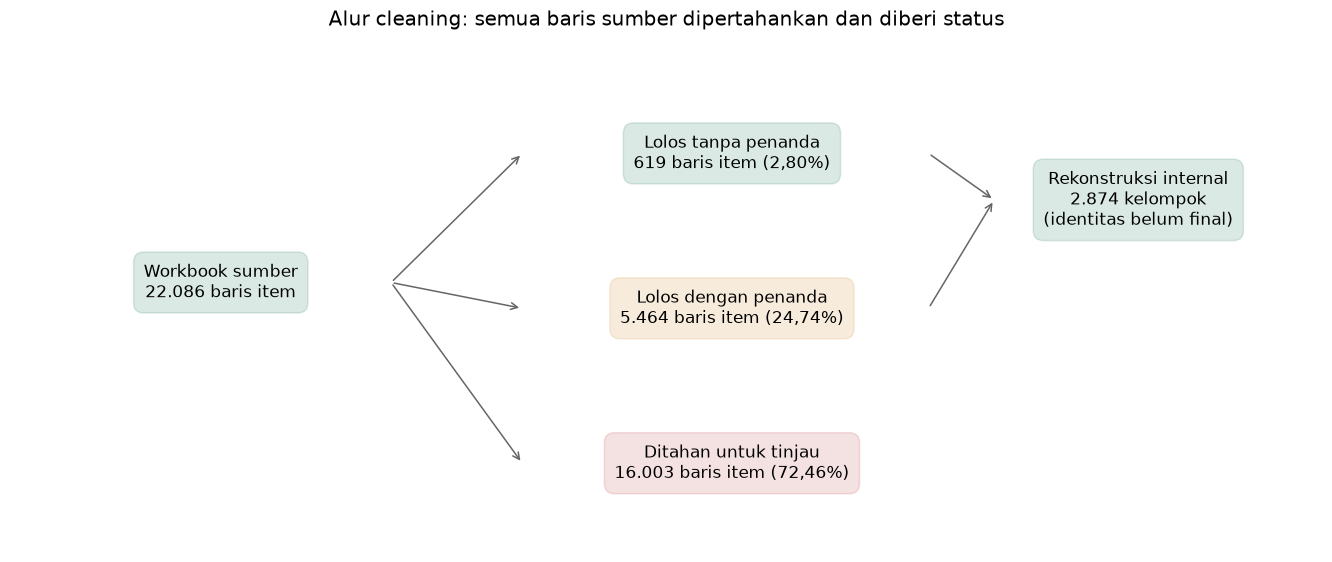

alasan,sifat,baris_sumber_unik,kelompok_nomor_terisi,persen_seluruh_item
selisih_grand_total_dan_subtotal,menahan_kelompok,12543,3124,"56,79"
variasi_penulisan_nama_produk,penanda_tidak_otomatis_menahan,11438,3398,"51,79"
no_telepon_kosong,penanda_tidak_otomatis_menahan,6806,2212,"30,82"
anggota_baris_identik,penanda_tidak_otomatis_menahan,3936,582,"17,82"
kandidat_IQR_harga_satuan,penanda_tidak_otomatis_menahan,3917,2533,"17,74"
kandidat_IQR_subtotal_produk,penanda_tidak_otomatis_menahan,3722,2618,"16,85"
variasi_penulisan_nama_klien,penanda_tidak_otomatis_menahan,2826,917,"12,80"
total_tidak_dapat_direkonsiliasi,menahan_kelompok,2821,327,"12,77"
konflik_grand_total_antar_nilai_terisi,menahan_kelompok,2730,301,"12,36"
subtotal_berbeda_formula_diskon,penanda_tidak_otomatis_menahan,2722,1623,"12,32"


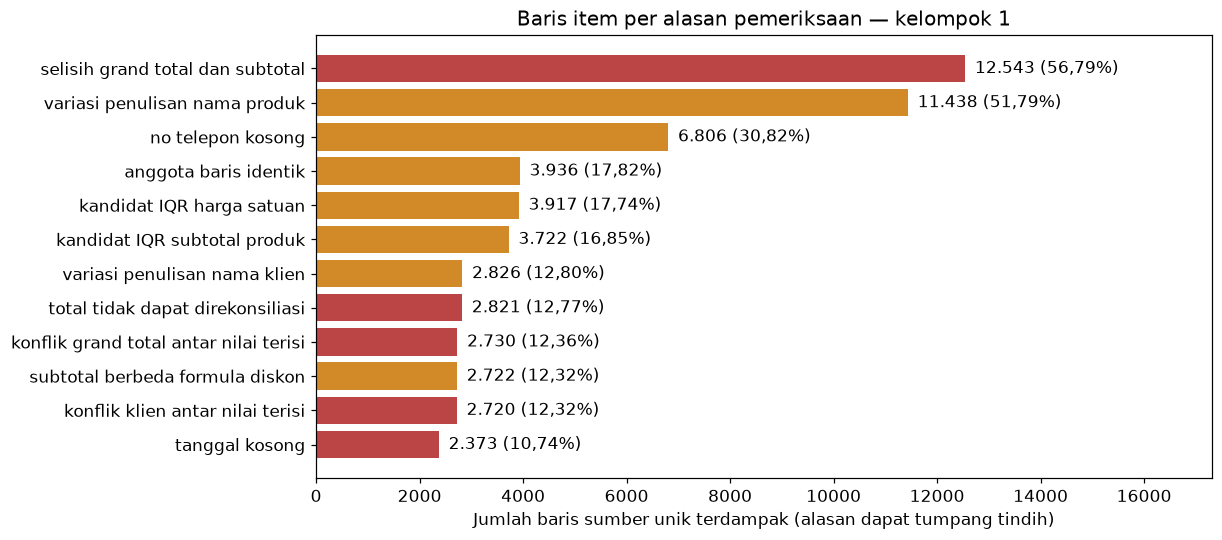

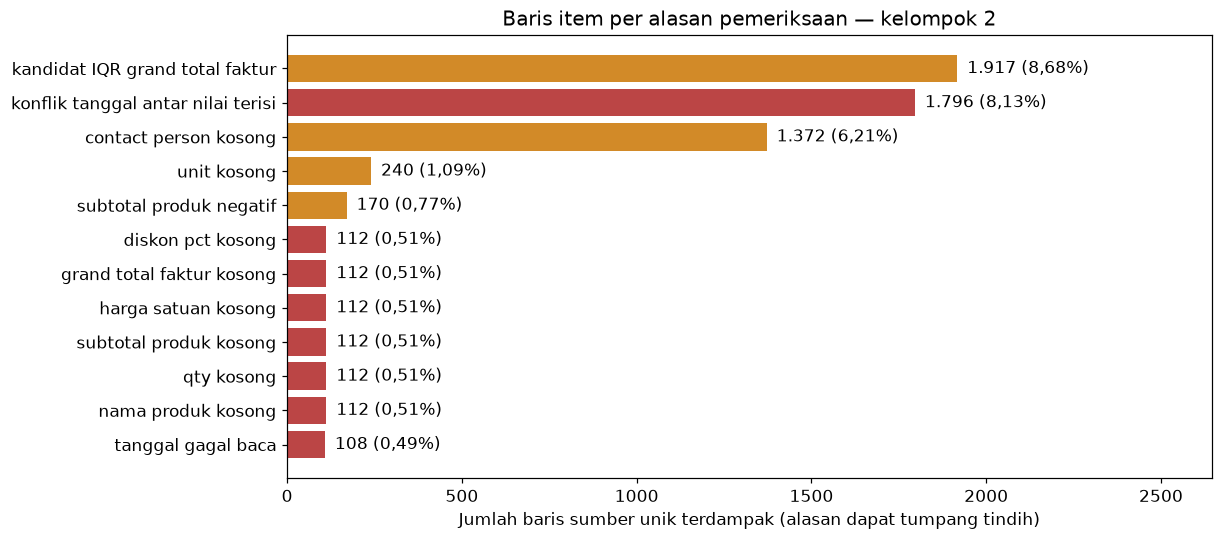

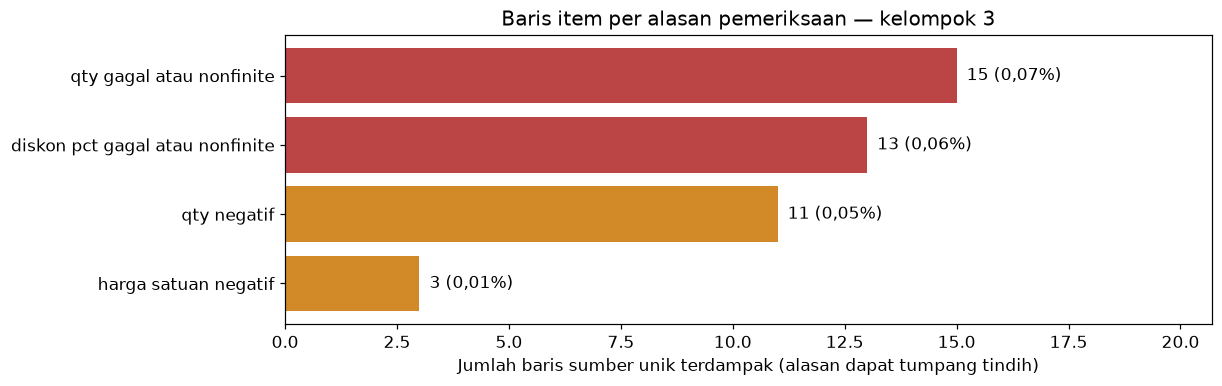

LULUS: cakupan seluruh baris, status, kelompok lolos, rekonsiliasi, IQR Tahap 1, dan integritas workbook.


In [16]:
status_counts_t2=item_audit['status_akhir'].value_counts().reindex(['lolos_internal_tanpa_penanda','lolos_internal_dengan_penanda','ditahan_untuk_tinjau'],fill_value=0)
fig,ax=plt.subplots(figsize=(12,5),layout='constrained');ax.set_xlim(0,1);ax.set_ylim(0,1);ax.axis('off')
def node_t2(x,y,text,color):
    ax.text(x,y,text,ha='center',va='center',bbox={'boxstyle':'round,pad=0.6','facecolor':color,'alpha':.16,'edgecolor':color},fontsize=11)
node_t2(.16,.52,f'Workbook sumber\n{angka(len(raw_t2))} baris item',GOOD)
node_t2(.55,.77,f'Lolos tanpa penanda\n{angka(status_counts_t2.iloc[0])} baris item ({pct(status_counts_t2.iloc[0])})',GOOD)
node_t2(.55,.47,f'Lolos dengan penanda\n{angka(status_counts_t2.iloc[1])} baris item ({pct(status_counts_t2.iloc[1])})',EMPTY)
node_t2(.55,.17,f'Ditahan untuk tinjau\n{angka(status_counts_t2.iloc[2])} baris item ({pct(status_counts_t2.iloc[2])})',CONFLICT)
node_t2(.86,.68,f'Rekonstruksi internal\n{angka(len(faktur_lolos))} kelompok\n(identitas belum final)',GOOD)
for y in [.77,.47,.17]: ax.annotate('',xy=(.39,y),xytext=(.29,.52),arrowprops={'arrowstyle':'->','color':'#666666'})
for y in [.77,.47]: ax.annotate('',xy=(.75,.68),xytext=(.70,y),arrowprops={'arrowstyle':'->','color':'#666666'})
ax.set_title('Alur cleaning: semua baris sumber dipertahankan dan diberi status')
finish(fig)
alasan_summary=kasus_tinjau.groupby(['alasan','sifat']).agg(baris_sumber_unik=('source_excel_row','nunique'),kelompok_nomor_terisi=('kelompok_kandidat','nunique')).reset_index()
alasan_summary['persen_seluruh_item']=100*alasan_summary['baris_sumber_unik']/len(raw_t2)
alasan_summary=alasan_summary.sort_values('baris_sumber_unik',ascending=False)
display(HTML(alasan_summary.to_html(index=False,float_format=desimal_id)))
for start in range(0,len(alasan_summary),12):
    panel=alasan_summary.iloc[start:start+12]
    bars(panel.assign(label=panel['alasan'].str.replace('_',' ')).set_index('label')['baris_sumber_unik'],f'Baris item per alasan pemeriksaan — kelompok {start//12+1}', 'Jumlah baris sumber unik terdampak (alasan dapat tumpang tindih)',len(raw_t2),[CONFLICT if r in blocking_t2 else EMPTY for r in panel.alasan])
# Invariants check coverage, no hidden row deletion, totals and source preservation.
assert len(item_audit)==len(raw_t2) and item_audit['source_excel_row'].is_unique
assert item_audit['status_akhir'].notna().all() and status_counts_t2.sum()==len(raw_t2)
assert len(item_lolos)+int(item_audit['ditahan'].sum())==len(raw_t2)
assert faktur_lolos.index.is_unique and len(faktur_lolos)==item_lolos['kelompok_kandidat'].nunique()
assert sum(faktur_lolos['jumlah_item'])==len(item_lolos)
assert faktur_lolos['sesuai_total'].all()
assert not set(faktur_lolos.index)&blocked_groups
assert all(len(rows)==len(set(rows)) for rows in faktur_lolos['source_excel_rows'])
assert not item_audit['tanggal_dipulihkan'].any()
assert raw_t2.equals(df_raw) and item_audit[raw_t2.columns].equals(raw_t2)
assert hashlib.sha256(SOURCE.read_bytes()).hexdigest()==source_hash_t2
assert set(item_audit.loc[item_audit['ditahan'],'source_excel_row']) <= set(kasus_tinjau['source_excel_row'])
for col in money_cols:
    assert int(flags_t2['kandidat_IQR_'+col].sum())==int(iqr_table.loc[col,'kandidat_baris'])
print('LULUS: cakupan seluruh baris, status, kelompok lolos, rekonsiliasi, IQR Tahap 1, dan integritas workbook.')

Seluruh item tetap tercakup: **619 lolos tanpa penanda**, **5.464 lolos dengan penanda**, dan **16.003 ditahan**. Tabel alasan menghitung item terdampak; kelompok dengan tanggal kosong dapat ikut menahan item lain yang tanggalnya terisi. Pemeriksaan berhasil memastikan tidak ada baris hilang atau kelompok ditahan masuk ke `faktur_lolos`, dan IQR tetap cocok dengan Tahap 1.

## Keputusan Tahap 2 dan konfirmasi yang masih diperlukan
Hasil lolos internal belum boleh dianggap sebagai identitas faktur/pelanggan final. Pemilik data perlu menyediakan ID faktur/pelanggan yang stabil atau bukti keunikan nomor lintas cabang/seri/periode, serta memvalidasi kelompok konflik. Tanggal kosong tidak diisi karena belum ada bukti identitas faktur independen.

Selisih grand total terhadap subtotal ditahan, bukan diseimbangkan dengan nilai tebakan. Minta definisi subtotal dan grand total, aturan diskon/pajak/biaya/pembulatan, kelengkapan item, serta dokumen retur atau koreksi; cek ulang item identik, negatif dan kandidat IQR. Kandidat IQR dapat mencakup transaksi sah dan tidak menjadi alasan penghapusan otomatis. Penerimaan toleransi Rp0,01 serta penanda yang tidak menahan juga perlu disepakati sebelum penggunaan bisnis.

Ketiga tabel mempertahankan penanda, sedangkan `item_audit` menyimpan setiap status akhir dan referensi sumber. Tidak ada ekspor data pelanggan, penghitungan RFM, atau pelatihan GMM pada tahap ini.

Sel berikut merangkum jumlah item per status. Persentasenya memakai semua baris sumber; kelompok lolos tetap mengikuti batas awal Rp0,01 saat dibawa ke audit sensitivitas dan RFM eksploratif.

In [17]:
hasil_akhir_t2=pd.DataFrame({'status':['Lolos tanpa penanda','Lolos dengan penanda','Ditahan'],
    'baris_item':[int(status_counts_t2.iloc[0]),int(status_counts_t2.iloc[1]),int(status_counts_t2.iloc[2])]})
hasil_akhir_t2['persen_seluruh_item']=100*hasil_akhir_t2['baris_item']/len(raw_t2)
display(hasil_akhir_t2.round(2))
assert len(kasus_tinjau)==64871
assert (len(raw_t2),len(item_lolos),int(item_audit.ditahan.sum()),len(faktur_lolos))==(22086,6083,16003,2874)

,status,baris_item,persen_seluruh_item
0,Lolos tanpa penanda,619,2.80
1,Lolos dengan penanda,5464,24.74
2,Ditahan,16003,72.46


Sebanyak **6.083 dari 22.086 item (27,54%)** membentuk **2.874 kelompok lolos internal**. Dari kelompok lolos itu, **2.297 masih memiliki penanda** yang perlu pemeriksaan bisnis. Status ini dipertahankan pada tahap selanjutnya; simulasi hanya menilai sensitivitas cakupan terhadap batas selisih.

# Tahap 2B — Audit Dampak Cleaning dan Simulasi Batas Selisih
Bagian ini mengaudit **cakupan kelompok kandidat**, bukan mengesahkan faktur atau pelanggan. Tabel dan status Tahap 2 tidak diubah; skenario toleransi hanya simulasi pada salinan. Satu kelompok kandidat adalah pengelompokan nomor faktur asli Tahap 2, belum satu faktur bisnis yang terverifikasi.

## 2B.1 Penyebab penahanan dan cakupan terdampak
Alasan penahanan bisa tumpang tindih: jumlah antaralasan tidak boleh dijumlahkan. “Baris terdampak” mencakup seluruh item dalam kelompok yang ditahan karena alasan tersebut, sedangkan “baris masalah langsung” hanya menghitung baris yang flag-nya aktif. Penanda nonpenahanan (identik, negatif, IQR, dan lainnya) tidak diubah menjadi alasan penahanan baru.

Tabel awal harus mengulang angka Tahap 2. Pada tabel alasan, kolom masalah langsung menghitung flag di item itu sendiri, sedangkan item terdampak mencakup semua item dalam kelompok terkait. Grafik kiri memakai baris item dan kanan memakai kelompok kandidat. Grafik kombinasi selanjutnya memisahkan alasan nominal saja dari nominal bersama alasan lain.

,metrik,hasil_hitung,angka_awal_verifikasi,sesuai
0,Baris sumber,22086,22086,True
1,Item lolos internal,6083,6083,True
2,Item ditahan,16003,16003,True
3,Kelompok kandidat lolos internal,2874,2874,True


,alasan,kelompok_ditahan,baris_item_terdampak,baris_masalah_langsung,baris_tanpa_kelompok_terdampak
15,selisih_grand_total_dan_subtotal,3124,12543,12543,0
21,tanggal_kosong,761,2373,1969,0
8,konflik_klien_antar_nilai_terisi,349,2720,2720,0
23,total_tidak_dapat_direkonsiliasi,327,2821,2821,0
7,konflik_grand_total_antar_nilai_terisi,301,2730,2730,0
9,konflik_tanggal_antar_nilai_terisi,221,1796,1796,0
4,grand_total_faktur_kosong,27,112,92,0
2,diskon_pct_kosong,27,112,92,0
6,harga_satuan_kosong,27,112,92,0
17,subtotal_produk_kosong,27,112,92,0


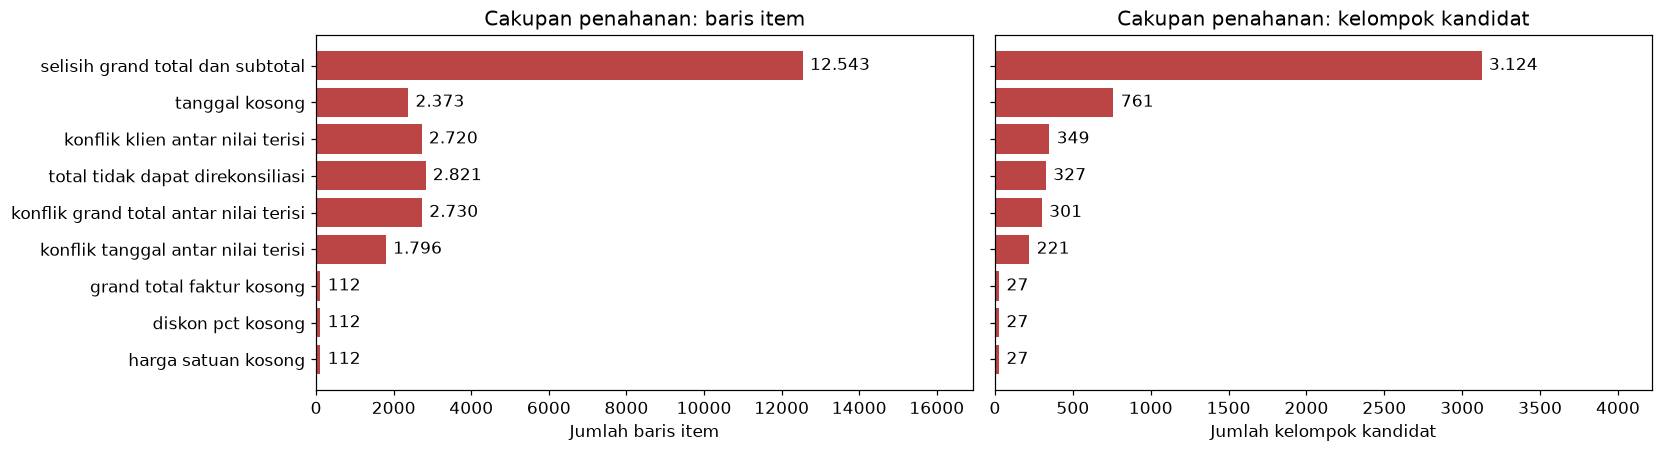

pada panel ini, selisih grand total dan subtotal berdampak pada 12.543 baris item dalam 3.124 kelompok kandidat. Cakupan antaralasan dapat tumpang tindih dan tidak membuktikan penyebab bisnisnya.

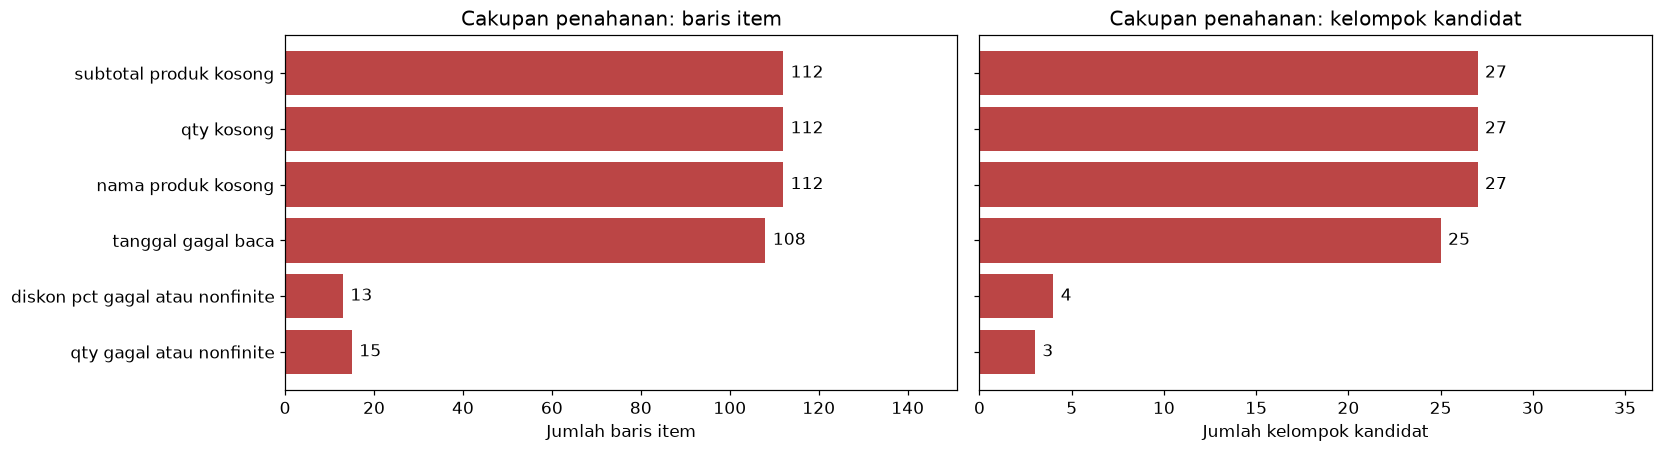

pada panel ini, subtotal produk kosong berdampak pada 112 baris item dalam 27 kelompok kandidat. Cakupan antaralasan dapat tumpang tindih dan tidak membuktikan penyebab bisnisnya.

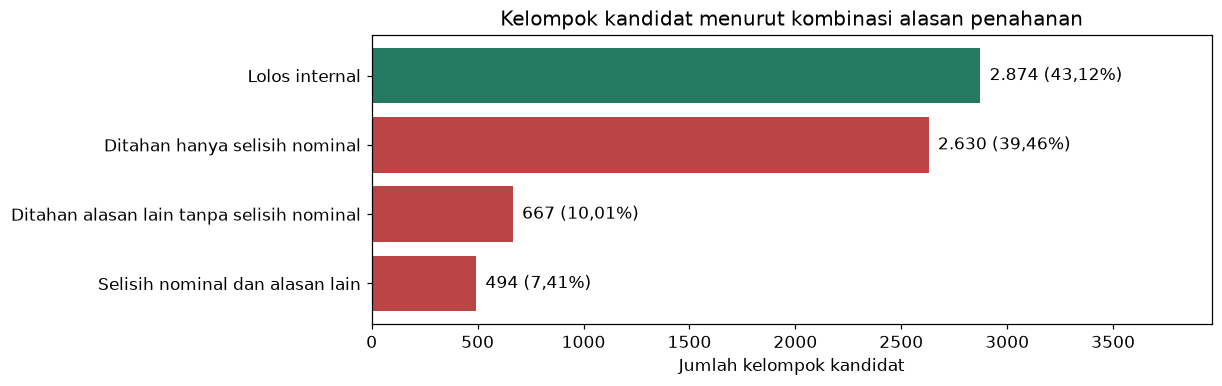

,kelompok,baris_item
kelas_penahanan,,
Ditahan alasan lain tanpa selisih nominal,667,3460
Ditahan hanya selisih nominal,2630,10503
Lolos internal,2874,6083
Selisih nominal dan alasan lain,494,2040


In [18]:
from IPython.display import HTML
# Keep full snapshots; all subsequent computations use independent copies.
snapshot_2b={name:globals()[name].copy(deep=True) for name in
             ['item_audit','item_lolos','faktur_lolos','kasus_tinjau','rekonstruksi_kandidat']}
flags_snapshot_2b=pd.DataFrame(flags_t2).copy(deep=True)
blocking_snapshot_2b=set(blocking_t2)
items_2b=item_audit.copy(deep=True)
groups_2b=rekonstruksi_kandidat.copy(deep=True)
flags_2b=flags_snapshot_2b.copy(deep=True)
N_2b=len(items_2b); G_2b=len(groups_2b)
verification_2b=pd.DataFrame({'metrik':['Baris sumber','Item lolos internal','Item ditahan','Kelompok kandidat lolos internal'],
    'hasil_hitung':[N_2b,len(item_lolos),int(items_2b['ditahan'].sum()),len(faktur_lolos)],
    'angka_awal_verifikasi':[22086,6083,16003,2874]})
verification_2b['sesuai']=verification_2b.hasil_hitung.eq(verification_2b.angka_awal_verifikasi)
display(verification_2b)
assert verification_2b['sesuai'].all(), 'Hasil Tahap 2 berubah dari angka awal; hentikan interpretasi.'
assert groups_2b.index.is_unique
valid_group_2b=items_2b['kelompok_kandidat'].notna()
no_group_2b=int((~valid_group_2b).sum())
block_group_2b=flags_2b.loc[valid_group_2b,sorted(blocking_snapshot_2b)].groupby(items_2b.loc[valid_group_2b,'kelompok_kandidat']).any().reindex(groups_2b.index,fill_value=False)
groups_2b['ditahan_dasar']=block_group_2b.any(axis=1)
assert set(groups_2b.index[~groups_2b.ditahan_dasar])==set(faktur_lolos.index)
reason_rows_2b=[]
for reason in block_group_2b:
    affected=block_group_2b[reason]
    reason_rows_2b.append({'alasan':reason,'kelompok_ditahan':int(affected.sum()),
        'baris_item_terdampak':int(groups_2b.loc[affected,'jumlah_item'].sum()),
        'baris_masalah_langsung':int(flags_2b[reason].sum()),
        'baris_tanpa_kelompok_terdampak':int((flags_2b[reason]&~valid_group_2b).sum())})
reason_audit_2b=pd.DataFrame(reason_rows_2b).sort_values('kelompok_ditahan',ascending=False)
display(reason_audit_2b)
nonzero_reasons_2b=reason_audit_2b.loc[reason_audit_2b.kelompok_ditahan.gt(0)]
for start in range(0,len(nonzero_reasons_2b),9):
    panel=nonzero_reasons_2b.iloc[start:start+9]
    fig,axes=plt.subplots(1,2,figsize=(15,max(4,len(panel)*.43)),layout='constrained')
    labels=panel.alasan.str.replace('_',' ')
    for ax,col,unit in zip(axes,['baris_item_terdampak','kelompok_ditahan'],['baris item','kelompok kandidat']):
        vals=panel[col].to_numpy(); limit=max(vals.max(),1)
        ax.barh(range(len(panel)),vals,color=CONFLICT)
        ax.set_yticks(range(len(panel)),labels if ax is axes[0] else ['']*len(panel));ax.invert_yaxis()
        ax.set_xlim(0,limit*1.35);ax.set_xlabel('Jumlah '+unit)
        ax.set_title('Cakupan penahanan: '+unit)
        for j,v in enumerate(vals):ax.text(v+limit*.015,j,angka(v),va='center')
    finish(fig)
    top=panel.iloc[0]
    note(f"pada panel ini, {top.alasan.replace('_',' ')} berdampak pada {angka(top.baris_item_terdampak)} baris item dalam {angka(top.kelompok_ditahan)} kelompok kandidat. Cakupan antaralasan dapat tumpang tindih dan tidak membuktikan penyebab bisnisnya.")
nominal_reason_2b='selisih_grand_total_dan_subtotal'
other_blocks_2b=block_group_2b.drop(columns=nominal_reason_2b).any(axis=1)
nominal_block_2b=block_group_2b[nominal_reason_2b]
groups_2b['kelas_penahanan']=np.select([
    ~groups_2b.ditahan_dasar,nominal_block_2b & ~other_blocks_2b,nominal_block_2b & other_blocks_2b],
    ['Lolos internal','Ditahan hanya selisih nominal','Selisih nominal dan alasan lain'],default='Ditahan alasan lain tanpa selisih nominal')
classes_2b=groups_2b.groupby('kelas_penahanan').agg(kelompok=('jumlah_item','size'),baris_item=('jumlah_item','sum'))
class_plot_2b=classes_2b['kelompok'].sort_values(ascending=False)
bars(class_plot_2b,'Kelompok kandidat menurut kombinasi alasan penahanan','Jumlah kelompok kandidat',G_2b,[GOOD if label=='Lolos internal' else CONFLICT for label in class_plot_2b.index])
only_nominal_2b=int((nominal_block_2b & ~other_blocks_2b).sum())
display(classes_2b)

Ada **3.791 kelompok ditahan**. Selisih nominal mengenai **3.124 kelompok atau 12.543 item**, tetapi hanya **2.630 kelompok** tertahan semata-mata karena alasan itu; **494** juga memiliki alasan lain, dan **667** ditahan tanpa selisih nominal. Kategori kombinasi ini saling lepas, berbeda dari perhitungan per alasan yang bertumpang tindih.

## 2B.2 Besar dan arah selisih nominal
Selisih bertanda = grand total konsisten − jumlah subtotal item; selisih absolut = nilai absolut selisih. Selisih relatif bertanda = selisih ÷ |grand total| × 100%, sedangkan selisih relatif absolut memakai |selisih|; grand total nol tidak mendapat rasio. Kelompok belum dapat direkonsiliasi tetap dipisahkan dan tidak diberi total tebakan.

Rentang absolut saling lepas: tepat Rp0; (Rp0, Rp0,01]; (Rp0,01, Rp1]; (Rp1, Rp100]; (Rp100, Rp1.000]; (Rp1.000, Rp100.000]; (Rp100.000, Rp1.000.000]; dan >Rp1.000.000. Batas kanan termasuk, batas kiri tidak; rentang ini deskriptif, sedangkan skenario memakai epsilon teknis Tahap 2 yang sama.

Selisih negatif berarti jumlah subtotal lebih besar daripada grand total. Statistik `50%` menunjukkan median, sehingga besarnya masalah tidak dinilai hanya dari rata-rata. Semua statistik dan grafik di sini memakai kelompok kandidat, bukan baris item.

,kategori,kelompok
0,"Dapat dibandingkan, grand total bukan nol",6155
1,"Dapat dibandingkan, grand total nol",183
2,Belum dapat direkonsiliasi / nilai tidak finite,327


,kelompok
Grand total nol dan subtotal sesuai toleransi dasar,137
Grand total nol dan subtotal di luar toleransi,46


,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
selisih_bertanda_Rp,"6.338,00","-582.451,32","8.186.703,14","-84.189.189,18","-450.000,00","0,00","0,00","130.134,00","1.375.000,00","6.985.409,08","400.000.000,00"
selisih_absolut_Rp,"6.338,00","1.431.305,21","8.081.612,06","0,00","0,00","0,00","1.000.000,00","3.500.000,00","7.500.000,00","17.480.819,20","400.000.000,00"
relatif_bertanda_persen,"6.155,00","-11,44","61,50","-1.000,00","-20,00","0,00","0,00","9,09","21,01","99,52","3.509,09"
relatif_absolut_persen,"6.155,00","21,92","58,59","0,00","0,00","0,02","33,33","83,49","100,00","114,23","3.509,09"


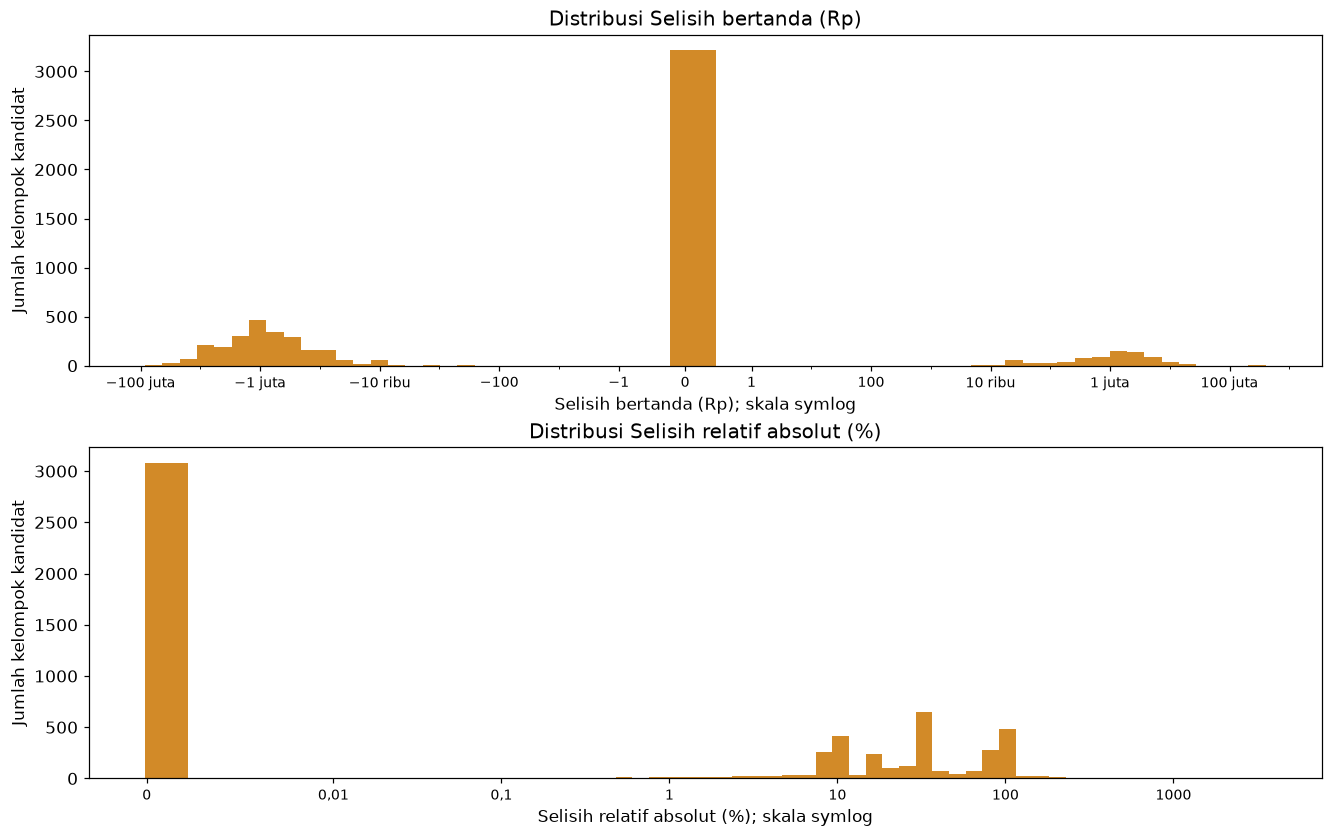

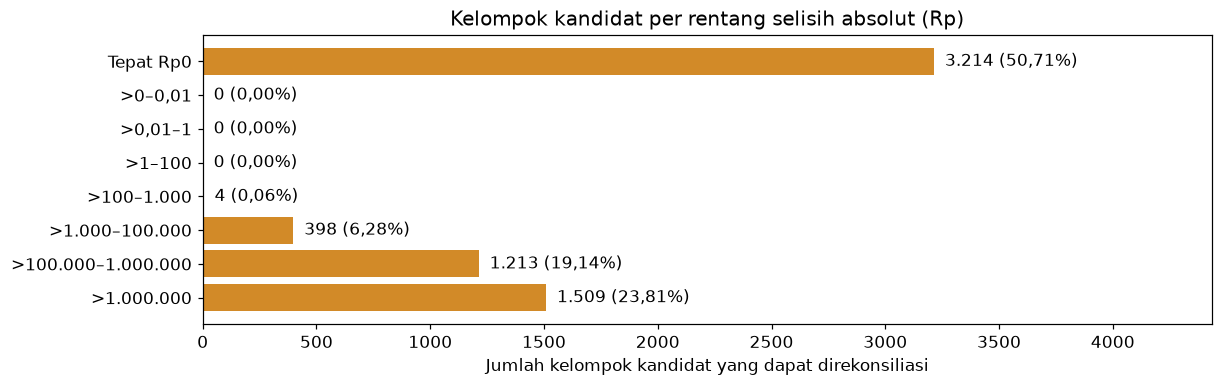

In [19]:
finite_recon_2b=np.isfinite(groups_2b['grand_total_konsisten_Rp']) & np.isfinite(groups_2b['subtotal_item_Rp']) & np.isfinite(groups_2b['selisih_total_Rp'])
comparable_2b=groups_2b['dapat_direkonsiliasi'] & finite_recon_2b
gaps_2b=groups_2b.loc[comparable_2b].copy()
gaps_2b['selisih_bertanda_Rp']=gaps_2b['grand_total_konsisten_Rp']-gaps_2b['subtotal_item_Rp']
gaps_2b['selisih_absolut_Rp']=gaps_2b['selisih_bertanda_Rp'].abs()
nonzero_total_2b=gaps_2b['grand_total_konsisten_Rp'].ne(0)
gaps_2b['relatif_bertanda_persen']=gaps_2b['selisih_bertanda_Rp'].div(gaps_2b['grand_total_konsisten_Rp'].abs().where(nonzero_total_2b)).mul(100)
gaps_2b['relatif_absolut_persen']=gaps_2b['relatif_bertanda_persen'].abs()
recon_coverage_2b=pd.DataFrame({'kategori':['Dapat dibandingkan, grand total bukan nol','Dapat dibandingkan, grand total nol','Belum dapat direkonsiliasi / nilai tidak finite'],
    'kelompok':[int(nonzero_total_2b.sum()),int((~nonzero_total_2b).sum()),int((~comparable_2b).sum())]})
display(recon_coverage_2b)
zero_total_audit_2b=pd.Series({'Grand total nol dan subtotal sesuai toleransi dasar':int((~nonzero_total_2b & gaps_2b.selisih_absolut_Rp.le(TOL_RP_T2+EPS_T2)).sum()),
 'Grand total nol dan subtotal di luar toleransi':int((~nonzero_total_2b & gaps_2b.selisih_absolut_Rp.gt(TOL_RP_T2+EPS_T2)).sum())},name='kelompok')
display(zero_total_audit_2b.to_frame())
summary_gaps_2b=gaps_2b[['selisih_bertanda_Rp','selisih_absolut_Rp','relatif_bertanda_persen','relatif_absolut_persen']].describe(percentiles=[.25,.5,.75,.9,.95,.99]).T
# Aggregate-only formatting avoids scientific notation in the audience table.
def show_decimal_2b(table):
    display(HTML(table.to_html(float_format=lambda v:f'{v:,.2f}'.replace(',','_').replace('.',',').replace('_','.'))))
show_decimal_2b(summary_gaps_2b)
fig,axes=plt.subplots(2,1,figsize=(12,7.5),layout='constrained')
for ax,col,unit,threshold in [(axes[0],'selisih_bertanda_Rp','Selisih bertanda (Rp)',1),(axes[1],'relatif_absolut_persen','Selisih relatif absolut (%)',.01)]:
    v=gaps_2b[col].dropna(); transformed=np.arcsinh(v/threshold)
    if len(v):
        edge_t=np.linspace(transformed.min()-.01,transformed.max()+.01,60)
        ax.hist(v,bins=np.sinh(edge_t)*threshold,color=EMPTY)
    ax.set_xscale('symlog',linthresh=threshold)
    ax.set(title='Distribusi '+unit,xlabel=unit+'; skala symlog',ylabel='Jumlah kelompok kandidat')
    if col=='selisih_bertanda_Rp':
        ax.set_xticks([-1e8,-1e6,-1e4,-100,-1,0,1,100,1e4,1e6,1e8])
        ax.xaxis.set_major_formatter(FuncFormatter(lambda x,pos:('−' if x<0 else '')+(f'{abs(x)/1e6:g} juta' if abs(x)>=1e6 else f'{abs(x)/1e3:g} ribu' if abs(x)>=1e3 else f'{abs(x):g}')))
    else:
        ax.set_xticks([0,.01,.1,1,10,100,1000])
        ax.xaxis.set_major_formatter(FuncFormatter(lambda x,pos:f'{x:g}'.replace('.',',')))
    ax.tick_params(axis='x',labelsize=9)
finish(fig)
abs_bins_2b=[-np.inf,0,.01,1,100,1000,100000,1000000,np.inf]
abs_labels_2b=['Tepat Rp0','>0–0,01','>0,01–1','>1–100','>100–1.000','>1.000–100.000','>100.000–1.000.000','>1.000.000']
gaps_2b['rentang_selisih_Rp']=pd.cut(gaps_2b.selisih_absolut_Rp,bins=abs_bins_2b,labels=abs_labels_2b,right=True)
range_gaps_2b=gaps_2b['rentang_selisih_Rp'].value_counts(sort=False)
bars(range_gaps_2b,'Kelompok kandidat per rentang selisih absolut (Rp)','Jumlah kelompok kandidat yang dapat direkonsiliasi',len(gaps_2b),EMPTY)
assert range_gaps_2b.sum()==comparable_2b.sum()

Perbandingan nominal tersedia untuk **6.338 kelompok**, sementara **327** belum bisa dibandingkan. Di antara yang bisa dibandingkan, **183 grand total nol** dipisahkan dari rasio: 137 sesuai batas dasar dan 46 berselisih. Arah dan besar selisih terlihat di Excel; pembulatan, pajak, ongkir, retur, atau item tidak lengkap masih perlu bukti tambahan.

## 2B.3 Profil kelompok lolos dan ditahan
Periode memakai tahun agar jumlah kasus kecil tetap mudah dibaca. Tanggal kelompok hanya ditetapkan jika seluruh baris memiliki tanggal terbaca, tepat satu nilai, tidak ambigu, dan tidak berkonflik menurut flag Tahap 2; tidak ada pengisian tanggal. Nominal memakai satu grand total yang konsisten, lengkap dan finite, meskipun kelompok ditahan karena alasan lain. Kategori “Belum dapat ditetapkan” selalu disertakan. Penyebut tingkat kelulusan adalah seluruh kelompok pada kategori itu, bukan seluruh baris item.

Panel kiri menunjukkan jumlah kelompok lolos/ditahan; panel kanan tingkat kelulusan. Jumlah `n` ditampilkan agar persentase pada tahun yang hanya berisi satu atau dua kelompok tidak disamakan dengan tahun berisi ratusan kelompok. Profil ini bukan filter periode untuk RFM.

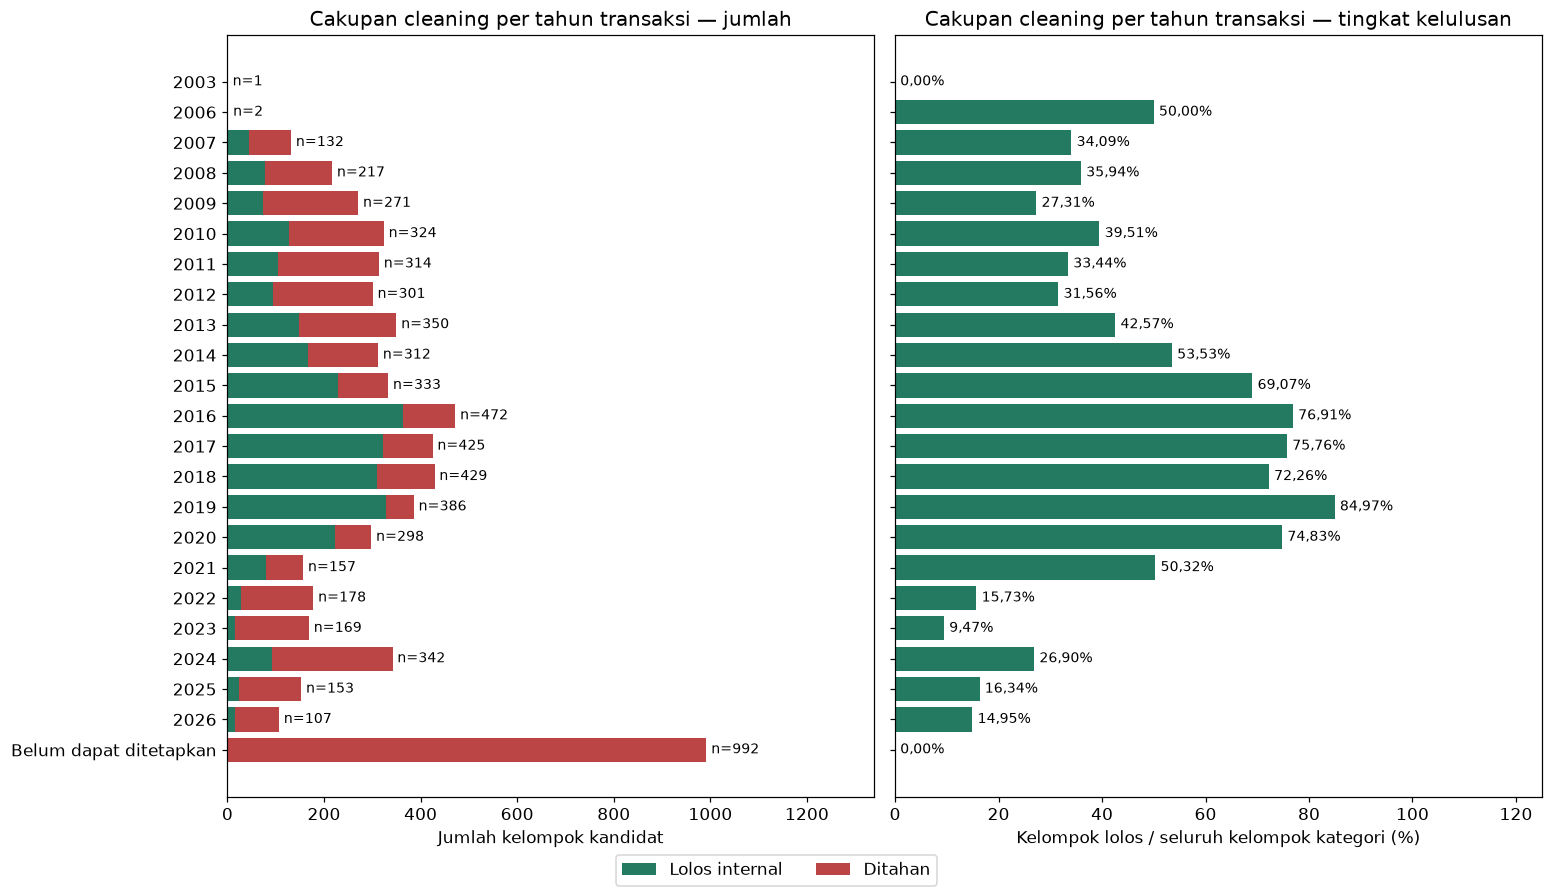

Di antara kategori berisi sedikitnya 30 kelompok, 2023 memiliki kelulusan 9,47% (16 dari 169), dibanding 2019 sebesar 84,97% (328 dari 386). Batas 30 hanya membantu membaca kategori yang cukup berisi, bukan uji statistik; kategori kecil tetap ditampilkan.

,total_kelompok,ditahan,lolos,tingkat_lolos_persen
periode,,,,
2003,1,1,0,0.00
2006,2,1,1,50.00
2007,132,87,45,34.09
2008,217,139,78,35.94
2009,271,197,74,27.31
2010,324,196,128,39.51
2011,314,209,105,33.44
2012,301,206,95,31.56
2013,350,201,149,42.57


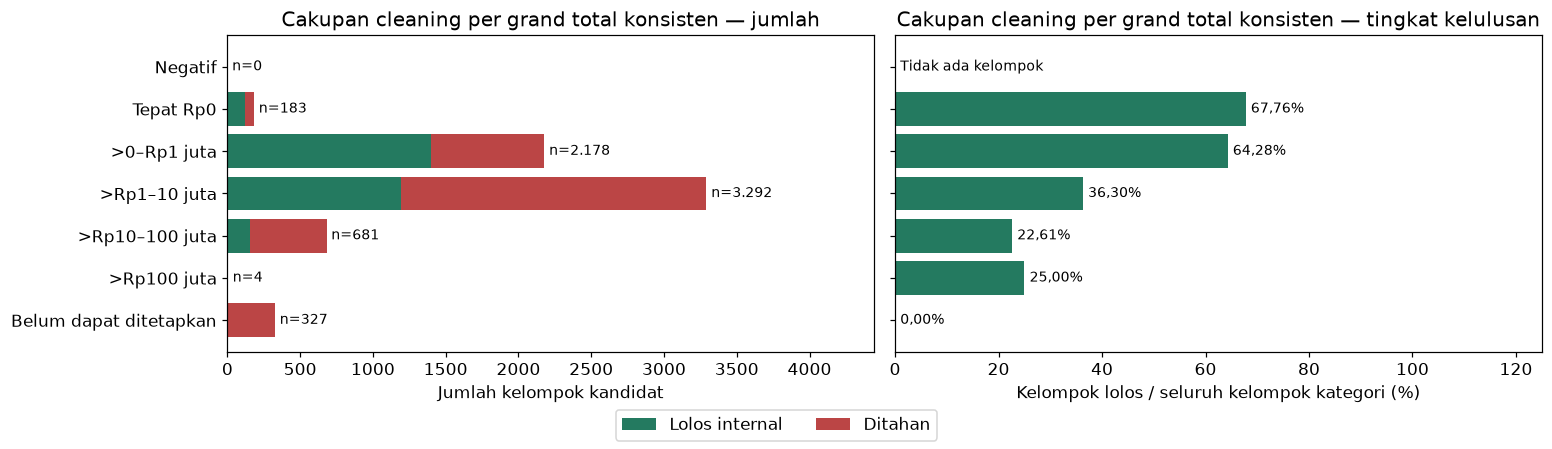

Di antara kategori berisi sedikitnya 30 kelompok, >Rp10–100 juta memiliki kelulusan 22,61% (154 dari 681), dibanding Tepat Rp0 sebesar 67,76% (124 dari 183). Batas 30 hanya membantu membaca kategori yang cukup berisi, bukan uji statistik; kategori kecil tetap ditampilkan.

,total_kelompok,ditahan,lolos,tingkat_lolos_persen
rentang_nominal,,,,
Negatif,0,0,0,NaN
Tepat Rp0,183,59,124,67.76
>0–Rp1 juta,2178,778,1400,64.28
>Rp1–10 juta,3292,2097,1195,36.30
>Rp10–100 juta,681,527,154,22.61
>Rp100 juta,4,3,1,25.00
Belum dapat ditetapkan,327,327,0,0.00


In [20]:
date_g_2b=items_2b.loc[valid_group_2b].groupby('kelompok_kandidat')
date_info_2b=date_g_2b.agg(jumlah=('source_excel_row','size'),terbaca=('tanggal_std','count'),unik=('tanggal_std','nunique'),ambigu=('tanggal_ambigu','any'),tanggal=('tanggal_std','min'))
date_ok_2b=date_info_2b.terbaca.eq(date_info_2b.jumlah)&date_info_2b.unik.eq(1)&~date_info_2b.ambigu&~block_group_2b['konflik_tanggal_antar_nilai_terisi']
groups_2b['tanggal_profil']=date_info_2b['tanggal'].where(date_ok_2b)
groups_2b['periode']=groups_2b['tanggal_profil'].dt.year.astype('Int64').astype('string').fillna('Belum dapat ditetapkan')
consistent_money_2b=groups_2b['grand_total_konsisten_Rp'].where(np.isfinite(groups_2b['grand_total_konsisten_Rp']))
money_bins_2b=[-np.inf,-np.nextafter(0,1),0,1000000,10000000,100000000,np.inf]
money_labels_2b=['Negatif','Tepat Rp0','>0–Rp1 juta','>Rp1–10 juta','>Rp10–100 juta','>Rp100 juta']
groups_2b['rentang_nominal']=pd.cut(consistent_money_2b,bins=money_bins_2b,labels=money_labels_2b).astype('string').fillna('Belum dapat ditetapkan')
def profile_2b(key,order):
    t=groups_2b.groupby(key).agg(total_kelompok=('ditahan_dasar','size'),ditahan=('ditahan_dasar','sum')).reindex(order,fill_value=0)
    t['lolos']=t.total_kelompok-t.ditahan
    t['tingkat_lolos_persen']=t.lolos.div(t.total_kelompok.where(t.total_kelompok.ne(0))).mul(100)
    return t
period_order_2b=sorted(set(groups_2b.periode)-{'Belum dapat ditetapkan'})+['Belum dapat ditetapkan']
profile_period_2b=profile_2b('periode',period_order_2b)
profile_money_2b=profile_2b('rentang_nominal',money_labels_2b+['Belum dapat ditetapkan'])
def draw_profile_2b(table,title):
    fig,axes=plt.subplots(1,2,figsize=(14,max(4,len(table)*.35)),layout='constrained',sharey=True)
    y=np.arange(len(table));limit=max(table.total_kelompok.max(),1)
    axes[0].barh(y,table.lolos,color=GOOD,label='Lolos internal')
    axes[0].barh(y,table.ditahan,left=table.lolos,color=CONFLICT,label='Ditahan')
    axes[0].set_yticks(y,table.index);axes[0].invert_yaxis();axes[0].set_xlim(0,limit*1.35)
    for j,row in enumerate(table.itertuples()):axes[0].text(row.total_kelompok+limit*.01,j,f'n={angka(row.total_kelompok)}',va='center',fontsize=9)
    axes[0].set(xlabel='Jumlah kelompok kandidat',title=title+' — jumlah')
    fig.legend(*axes[0].get_legend_handles_labels(),loc='outside lower center',ncol=2)
    axes[1].barh(y,table.tingkat_lolos_persen.fillna(0),color=GOOD);axes[1].set_xlim(0,125)
    for j,row in enumerate(table.itertuples()):
        axes[1].text((row.tingkat_lolos_persen if pd.notna(row.tingkat_lolos_persen) else 0)+1,j,pct(row.lolos,row.total_kelompok) if row.total_kelompok else 'Tidak ada kelompok',va='center',fontsize=9)
    axes[1].set(xlabel='Kelompok lolos / seluruh kelompok kategori (%)',title=title+' — tingkat kelulusan')
    finish(fig)
    known=table.drop(index='Belum dapat ditetapkan',errors='ignore')
    eligible=known.loc[known.total_kelompok.ge(30)]
    if eligible.empty:eligible=known.loc[known.total_kelompok.gt(0)]
    lowest=eligible.tingkat_lolos_persen.idxmin();highest=eligible.tingkat_lolos_persen.idxmax()
    lo=eligible.loc[lowest];hi=eligible.loc[highest]
    note(f'Di antara kategori berisi sedikitnya 30 kelompok, {lowest} memiliki kelulusan {pct(lo.lolos,lo.total_kelompok)} ({angka(lo.lolos)} dari {angka(lo.total_kelompok)}), dibanding {highest} sebesar {pct(hi.lolos,hi.total_kelompok)} ({angka(hi.lolos)} dari {angka(hi.total_kelompok)}). Batas 30 hanya membantu membaca kategori yang cukup berisi, bukan uji statistik; kategori kecil tetap ditampilkan.')
    display(table.round(2))
draw_profile_2b(profile_period_2b,'Cakupan cleaning per tahun transaksi')
draw_profile_2b(profile_money_2b,'Cakupan cleaning per grand total konsisten')
assert profile_period_2b.total_kelompok.sum()==G_2b
assert profile_money_2b.total_kelompok.sum()==G_2b

Kelulusan pada **2023 adalah 16 dari 169 kelompok (9,47%)**, dibanding **328 dari 386 pada 2019 (84,97%)**. Pada nominal **>Rp10–100 juta**, 154 dari 681 kelompok lolos (22,61%), sedangkan rentang **>Rp0–1 juta** memuat 1.400 dari 2.178 kelompok lolos (64,28%). Perbandingan ini menunjukkan ketimpangan cakupan, bukan penyebab penahanannya.

**992 kelompok** belum memiliki tanggal profil yang konsisten dan **327** belum memiliki nominal yang dapat ditetapkan. Kategori profil bukan filter RFM: seluruh subset lolos tetap dipakai, dengan risiko pergeseran gambaran transaksi terakhir, jumlah faktur, dan nilai belanja.

## 2B.4 Uji sensitivitas toleransi nominal
Rp0,01 adalah skenario dasar. Rp1, Rp100, dan Rp1.000 hanya pembanding sensitivitas, **bukan toleransi bisnis yang disetujui**. Simulasi mengganti hanya flag `selisih_grand_total_dan_subtotal`; seluruh alasan penahanan lain, termasuk kelompok belum dapat direkonsiliasi, tetap berlaku. Epsilon Rp0,000001 dari Tahap 2 dipertahankan di setiap skenario; flag diagnostik formula item dan IQR tidak dihitung ulang atau dilonggarkan.

Batang menunjukkan jumlah kelompok lolos dan tambahan terhadap dasar. Peta warna menunjukkan tambahan per tahun; tabel memakai penyebut kelompok pada tahun yang tetap. Poin persentase berarti selisih tingkat kelulusan, bukan persentase kenaikan relatif. Skenario dasar juga harus menghasilkan anggota item/kelompok yang sama dengan Tahap 2.

,toleransi_Rp,kelompok_lolos,item_lolos,cakupan_kelompok_persen,tambahan_vs_dasar,perubahan_cakupan_poin_persen
0,"0,01",2874,6083,"43,12",0,"0,00"
1,"1,00",2874,6083,"43,12",0,"0,00"
2,"100,00",2874,6083,"43,12",0,"0,00"
3,"1.000,00",2877,6089,"43,17",3,"0,05"


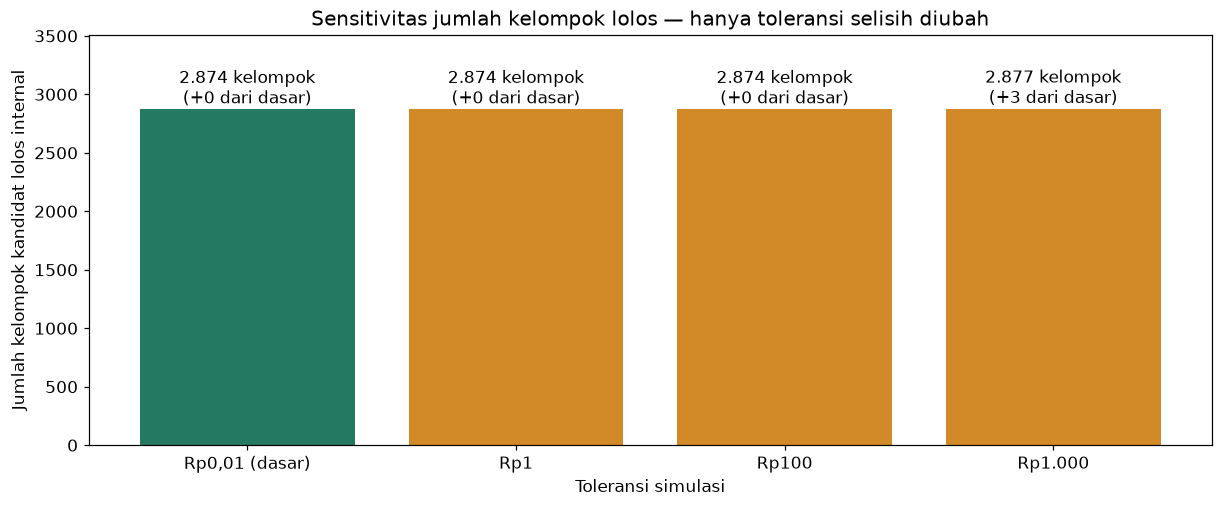

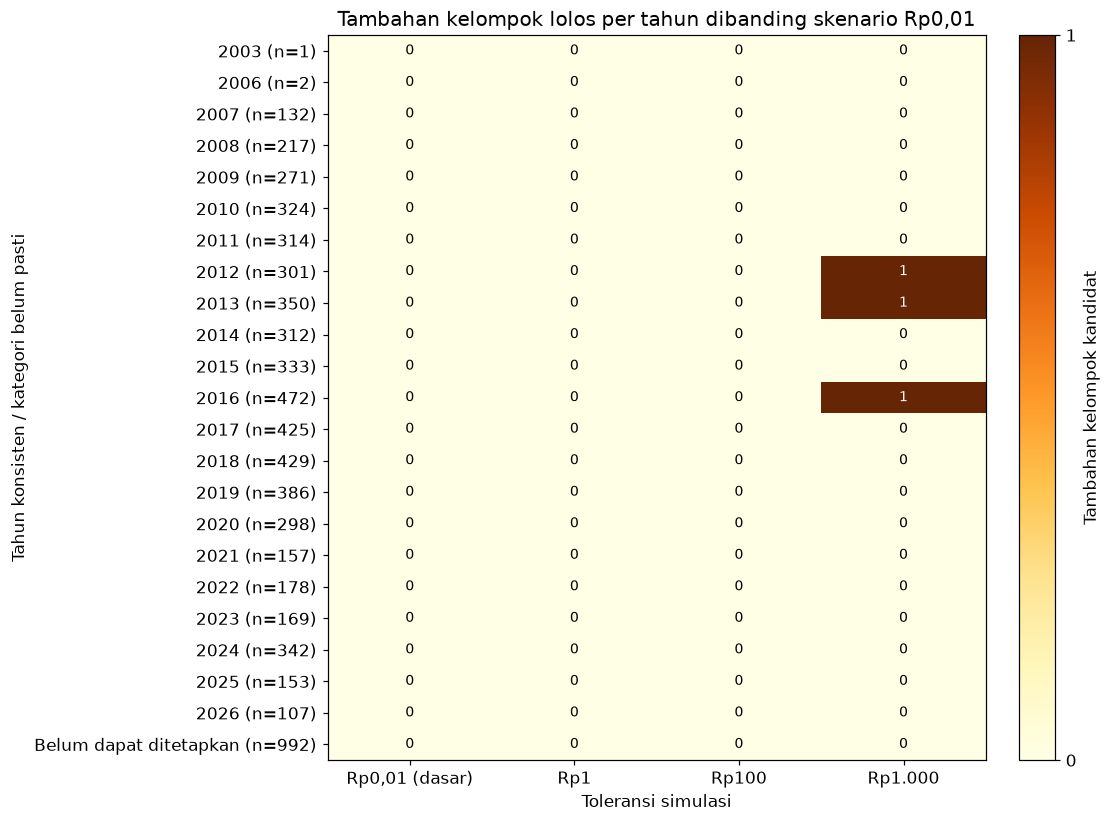

,Total kelompok,"Lolos Rp0,01",Lolos Rp1,Lolos Rp100,Lolos Rp1.000
periode,,,,,
2003,1,0,0,0,0
2006,2,1,1,1,1
2007,132,45,45,45,45
2008,217,78,78,78,78
2009,271,74,74,74,74
2010,324,128,128,128,128
2011,314,105,105,105,105
2012,301,95,95,95,96
2013,350,149,149,149,150


,Kelulusan dasar (%),"Delta pp Rp0,01",Delta pp Rp1,Delta pp Rp100,Delta pp Rp1.000
periode,,,,,
2003,"0,00","0,00","0,00","0,00","0,00"
2006,"50,00","0,00","0,00","0,00","0,00"
2007,"34,09","0,00","0,00","0,00","0,00"
2008,"35,94","0,00","0,00","0,00","0,00"
2009,"27,31","0,00","0,00","0,00","0,00"
2010,"39,51","0,00","0,00","0,00","0,00"
2011,"33,44","0,00","0,00","0,00","0,00"
2012,"31,56","0,00","0,00","0,00","0,33"
2013,"42,57","0,00","0,00","0,00","0,29"


In [21]:
simulation_groups_2b=groups_2b.copy(deep=True)
simulation_items_2b=items_2b.copy(deep=True)
scenario_pass_2b={}; scenario_rows_2b=[]; scenario_period_rows_2b=[]
for tol in [.01,1.,100.,1000.]:
    nominal_reject=simulation_groups_2b['dapat_direkonsiliasi'] & simulation_groups_2b['selisih_total_Rp'].abs().gt(tol+EPS_T2)
    passed=~(other_blocks_2b|nominal_reject)
    scenario_pass_2b[tol]=passed.copy()
    # Rows without a candidate group keep their original held status.
    item_pass=simulation_items_2b['kelompok_kandidat'].map(passed).fillna(False).astype(bool)
    scenario_rows_2b.append({'toleransi_Rp':tol,'kelompok_lolos':int(passed.sum()),'item_lolos':int(item_pass.sum()),'cakupan_kelompok_persen':100*passed.sum()/G_2b})
    for period in period_order_2b:
        mask=simulation_groups_2b.periode.eq(period)
        scenario_period_rows_2b.append({'toleransi_Rp':tol,'periode':period,'total_kelompok':int(mask.sum()),'kelompok_lolos':int((passed&mask).sum())})
sensitivity_2b=pd.DataFrame(scenario_rows_2b)
base_pass_2b=scenario_pass_2b[.01]
sensitivity_2b['tambahan_vs_dasar']=sensitivity_2b.kelompok_lolos-int(base_pass_2b.sum())
sensitivity_2b['perubahan_cakupan_poin_persen']=sensitivity_2b.cakupan_kelompok_persen-sensitivity_2b.cakupan_kelompok_persen.iloc[0]
assert base_pass_2b.equals(~groups_2b['ditahan_dasar'])
assert set(base_pass_2b.index[base_pass_2b])==set(faktur_lolos.index)
assert int(sensitivity_2b.iloc[0].item_lolos)==len(item_lolos)
assert simulation_items_2b.kelompok_kandidat.map(base_pass_2b).fillna(False).astype(bool).equals((~items_2b.ditahan).astype(bool))
for tol,passed in scenario_pass_2b.items():
    assert not (passed & other_blocks_2b).any()
    assert not (passed & ~simulation_groups_2b.dapat_direkonsiliasi).any()
    assert not (base_pass_2b & ~passed).any()
    assert not ((passed & ~base_pass_2b) & ~nominal_block_2b).any()
    assert (passed.sum()-base_pass_2b.sum())<=only_nominal_2b
show_decimal_2b(sensitivity_2b)
fig,ax=plt.subplots(figsize=(11,4.5),layout='constrained')
values=sensitivity_2b.kelompok_lolos.to_numpy(); labels=['Rp0,01 (dasar)','Rp1','Rp100','Rp1.000']
ax.bar(labels,values,color=[GOOD,EMPTY,EMPTY,EMPTY]);ax.set_ylim(0,max(values)*1.22)
for j,row in enumerate(sensitivity_2b.itertuples()): ax.text(j,row.kelompok_lolos,f'{angka(row.kelompok_lolos)} kelompok\n(+{angka(row.tambahan_vs_dasar)} dari dasar)',ha='center',va='bottom')
ax.set(title='Sensitivitas jumlah kelompok lolos — hanya toleransi selisih diubah',xlabel='Toleransi simulasi',ylabel='Jumlah kelompok kandidat lolos internal')
finish(fig)
max_added_2b=int(sensitivity_2b.iloc[-1].tambahan_vs_dasar)
sensitivity_period_2b=pd.DataFrame(scenario_period_rows_2b)
base_by_period_2b=sensitivity_period_2b.loc[sensitivity_period_2b.toleransi_Rp.eq(.01)].set_index('periode').kelompok_lolos
sensitivity_period_2b['tambahan_vs_dasar']=sensitivity_period_2b.kelompok_lolos-sensitivity_period_2b.periode.map(base_by_period_2b)
sensitivity_period_2b['cakupan_persen']=100*sensitivity_period_2b.kelompok_lolos/sensitivity_period_2b.total_kelompok.replace(0,np.nan)
sensitivity_period_2b['perubahan_poin_persen']=100*sensitivity_period_2b.tambahan_vs_dasar/sensitivity_period_2b.total_kelompok.replace(0,np.nan)
# Heatmap counts show absolute change; the table below also reports percentage points.
heat_2b=sensitivity_period_2b.pivot(index='periode',columns='toleransi_Rp',values='tambahan_vs_dasar').reindex(period_order_2b)
fig,ax=plt.subplots(figsize=(10,max(4,len(heat_2b)*.32)),layout='constrained')
im=ax.imshow(heat_2b.to_numpy(),aspect='auto',cmap='YlOrBr',vmin=0,vmax=max(1,heat_2b.to_numpy().max()))
ax.set_xticks(range(4),labels);ax.set_yticks(range(len(heat_2b)),[f'{p} (n={angka(profile_period_2b.loc[p,"total_kelompok"])})' for p in heat_2b.index])
for y in range(len(heat_2b)):
    for x in range(4):ax.text(x,y,angka(heat_2b.iloc[y,x]),ha='center',va='center',fontsize=9,color='white' if heat_2b.iloc[y,x]>max(1,heat_2b.to_numpy().max())*.6 else 'black')
ax.set(title='Tambahan kelompok lolos per tahun dibanding skenario Rp0,01',xlabel='Toleransi simulasi',ylabel='Tahun konsisten / kategori belum pasti')
colorbar_2b=fig.colorbar(im,ax=ax,label='Tambahan kelompok kandidat')
colorbar_2b.set_ticks(range(int(heat_2b.to_numpy().max())+1))
finish(fig)
added_period_2b=heat_2b[1000.]; peak_2b=added_period_2b.idxmax()
period_counts_2b=sensitivity_period_2b.pivot(index='periode',columns='toleransi_Rp',values='kelompok_lolos').reindex(period_order_2b)
period_counts_2b.columns=['Lolos Rp0,01','Lolos Rp1','Lolos Rp100','Lolos Rp1.000']
period_counts_2b.insert(0,'Total kelompok',profile_period_2b.total_kelompok)
display(HTML(period_counts_2b.to_html()))
period_change_2b=sensitivity_period_2b.pivot(index='periode',columns='toleransi_Rp',values='perubahan_poin_persen').reindex(period_order_2b)
period_change_2b.columns=['Delta pp Rp0,01','Delta pp Rp1','Delta pp Rp100','Delta pp Rp1.000']
period_change_2b.insert(0,'Kelulusan dasar (%)',profile_period_2b.tingkat_lolos_persen)
show_decimal_2b(period_change_2b)
assert sensitivity_2b['kelompok_lolos'].tolist()==[2874,2874,2874,2877]
assert all(int(sensitivity_period_2b.loc[sensitivity_period_2b.toleransi_Rp.eq(t),'kelompok_lolos'].sum())==int(p.sum()) for t,p in scenario_pass_2b.items())
assert not bool(scenario_pass_2b[.01].loc[case_ids_t2['B']])
assert bool(scenario_pass_2b[1000.].loc[case_ids_t2['B']])
assert all(not bool(mask.loc[case_ids_t2['C']]) for mask in scenario_pass_2b.values())

Jumlah lolos pada **Rp0,01, Rp1, Rp100, dan Rp1.000** berturut-turut **2.874, 2.874, 2.874, dan 2.877**. Pada batas Rp1.000 hanya tiga kelompok tambahan yang lolos, sehingga sebagian besar penahanan belum dapat ditangani dengan pelonggaran sampai angka itu. `faktur_lolos` tetap berisi **2.874 kelompok** sesuai aturan awal; konflik antarbaris tidak diloloskan oleh simulasi.

## 2B.5 Audit identitas pelanggan untuk persiapan RFM
Standardisasi nama hanya menyamakan kapital dan spasi; tidak membuktikan bahwa orang/perusahaan yang namanya sama adalah pelanggan yang sama. Telepon dapat dipakai bersama atau berubah. Audit berikut menghitung nama standar dengan beberapa ejaan asli serta telepon standar yang terkait beberapa nama standar, tanpa menampilkan nilainya dan tanpa penggabungan otomatis.

Satu batang menghitung kelompok nama atau kelompok telepon, bukan pelanggan yang sudah pasti berbeda. Kolom baris pada tabel menunjukkan berapa item tercakup dalam pola tersebut. Jumlah yang lebih kecil pada subset belum membuktikan masalah identitas selesai karena cakupannya juga lebih kecil.

,cakupan,nama_standar_terisi,nama_dengan_beberapa_ejaan,baris_dalam_variasi_nama,telepon_standar_terisi,telepon_terkait_beberapa_nama,baris_dengan_telepon_terkait_beberapa_nama
0,Seluruh sumber,2864,110,2826,2254,201,3085
1,Subset lolos internal,1456,57,657,1194,61,576


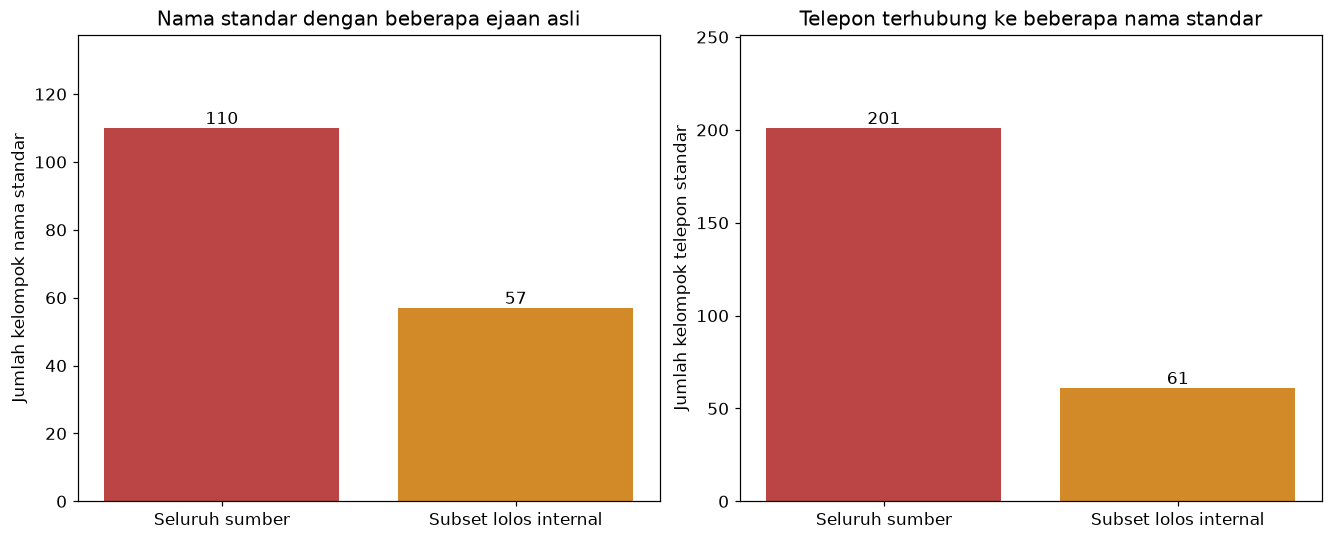

In [22]:
def identity_audit_2b(table,label):
    names=table.dropna(subset=['nama_klien_std']).groupby('nama_klien_std')['nama_klien'].nunique()
    phones=table.dropna(subset=['no_telepon_std']).groupby('no_telepon_std')['nama_klien_std'].nunique()
    varied=names[names.gt(1)].index; shared=phones[phones.gt(1)].index
    return {'cakupan':label,'nama_standar_terisi':len(names),'nama_dengan_beberapa_ejaan':len(varied),
        'baris_dalam_variasi_nama':int(table.nama_klien_std.isin(varied).sum()),
        'telepon_standar_terisi':len(phones),'telepon_terkait_beberapa_nama':len(shared),
        'baris_dengan_telepon_terkait_beberapa_nama':int(table.no_telepon_std.isin(shared).sum())}
identity_summary_2b=pd.DataFrame([identity_audit_2b(items_2b,'Seluruh sumber'),identity_audit_2b(item_lolos.copy(deep=True),'Subset lolos internal')])
# Also measure exposure of the passed subset to collisions identified in the full workbook.
name_variants_all_2b=items_2b.groupby('nama_klien_std')['nama_klien'].nunique()
shared_phone_all_2b=items_2b.dropna(subset=['no_telepon_std']).groupby('no_telepon_std')['nama_klien_std'].nunique()
passed_name_exposure_2b=int(item_lolos.nama_klien_std.isin(name_variants_all_2b[name_variants_all_2b.gt(1)].index).sum())
passed_phone_exposure_2b=int(item_lolos.no_telepon_std.isin(shared_phone_all_2b[shared_phone_all_2b.gt(1)].index).sum())
display(identity_summary_2b)
fig,axes=plt.subplots(1,2,figsize=(12,4.8),layout='constrained')
for ax,col,title,unit in [(axes[0],'nama_dengan_beberapa_ejaan','Nama standar dengan beberapa ejaan asli','kelompok nama standar'),(axes[1],'telepon_terkait_beberapa_nama','Telepon terhubung ke beberapa nama standar','kelompok telepon standar')]:
    vals=identity_summary_2b[col].to_numpy();ax.bar(identity_summary_2b.cakupan,vals,color=[CONFLICT,EMPTY]);ax.set_ylim(0,max(max(vals),1)*1.25)
    ax.set(title=title,ylabel='Jumlah '+unit)
    for j,v in enumerate(vals):ax.text(j,v,angka(v),ha='center',va='bottom')
finish(fig)
a=identity_summary_2b.iloc[0]

Seluruh sumber memuat **110 nama standar dengan beberapa ejaan asli** dan **201 telepon terkait beberapa nama standar**. Hitung ulang pada subset lolos menemukan **57 kelompok variasi nama** dan **61 kelompok telepon bersama**. Penurunan itu belum membuktikan identitas selesai: nama standar tetap label sementara yang dapat keliru menggabungkan atau memisahkan pelanggan.

## Kesiapan Menuju RFM
Subset lolos internal **dapat dipakai untuk RFM eksploratif secara bersyarat**, sebagai analisis subset kandidat dan label nama sementara, setelah batas cakupan dan penanda bisnis diakui. Hasilnya bukan segmentasi pelanggan tervalidasi dan tidak mewakili seluruh pelanggan/penjualan workbook; perubahan komposisi periode dan rentang nominal dapat menggeser Recency, Frequency, dan Monetary.

Sebelum penggunaan bisnis, konfirmasikan ID faktur dan pelanggan, keunikan nomor lintas cabang/seri/periode, format serta kelengkapan tanggal, definisi grand total/subtotal/diskon/biaya, kelengkapan item, retur, baris identik, dan toleransi nominal kepada pemilik data. Pajak/ongkir/pembulatan/retur/item hilang masih hipotesis, bukan penyebab yang dibuktikan audit ini. Skenario pembanding tidak menggantikan status Tahap 2; RFM dan GMM belum dihitung.

Satu baris ringkasan menghubungkan bukti dengan batas penggunaan data. Pemeriksaan di akhir sel membandingkan kelima tabel dan flag dengan salinan sebelum simulasi; jika berhasil, `faktur_lolos` masih mengikuti aturan awal dan dapat dibawa ke Tahap 3 tanpa memakai skenario Rp1.000.

In [23]:
held_groups_2b=int(groups_2b.ditahan_dasar.sum())
readiness_2b=pd.DataFrame([
 ['Cakupan dasar',f'{angka(base_pass_2b.sum())} dari {angka(G_2b)} kelompok ({pct(base_pass_2b.sum(),G_2b)}) lolos; {angka(held_groups_2b)} ditahan','Subset bukan representasi otomatis seluruh workbook'],
 ['Alasan nominal',f'{angka(only_nominal_2b)} kelompok ditahan hanya karena selisih nominal; {angka((nominal_block_2b&other_blocks_2b).sum())} juga memiliki alasan lain','Pelonggaran nominal tidak menyelesaikan konflik atau atribut yang hilang'],
 ['Sensitivitas Rp1.000',f'Tambahan {angka(max_added_2b)} kelompok; cakupan {pct(scenario_pass_2b[1000.].sum(),G_2b)} dibanding {pct(base_pass_2b.sum(),G_2b)} pada dasar','Toleransi bisnis tetap menunggu konfirmasi pemilik data'],
 ['Tanggal/nominal belum pasti',f'{angka(groups_2b.tanggal_profil.isna().sum())} kelompok tanpa tanggal profil; {angka(consistent_money_2b.isna().sum())} tanpa nominal konsisten','Risiko bias waktu dan besaran belanja perlu dicatat'],
 ['Identitas pelanggan',f'{angka(a.nama_dengan_beberapa_ejaan)} kelompok variasi nama; {angka(a.telepon_terkait_beberapa_nama)} telepon terkait beberapa nama','Minta ID pelanggan; jangan gabungkan otomatis']
],columns=['temuan','bukti_terhitung','implikasi_keputusan'])
display(HTML(readiness_2b.to_html(index=False)))
for name,before in snapshot_2b.items():pd.testing.assert_frame_equal(globals()[name],before)
pd.testing.assert_frame_equal(pd.DataFrame(flags_t2),flags_snapshot_2b)
assert blocking_t2==blocking_snapshot_2b
assert raw_t2.equals(df_raw) and df_raw.equals(raw_snapshot)
assert hashlib.sha256(SOURCE.read_bytes()).hexdigest()==source_hash_t2
assert int(sensitivity_2b.iloc[0].kelompok_lolos)==2874 and int(sensitivity_2b.iloc[0].item_lolos)==6083
assert int(items_2b.ditahan.sum())==16003 and len(items_2b)==22086
print('LULUS: angka dasar tereproduksi; lima tabel, seluruh flag, aturan penahanan dan workbook Tahap 2 tetap utuh. Hasil aturan awal siap dipakai pada Tahap 3 secara eksploratif.')

temuan,bukti_terhitung,implikasi_keputusan
Cakupan dasar,"2.874 dari 6.665 kelompok (43,12%) lolos; 3.791 ditahan",Subset bukan representasi otomatis seluruh workbook
Alasan nominal,2.630 kelompok ditahan hanya karena selisih nominal; 494 juga memiliki alasan lain,Pelonggaran nominal tidak menyelesaikan konflik atau atribut yang hilang
Sensitivitas Rp1.000,"Tambahan 3 kelompok; cakupan 43,17% dibanding 43,12% pada dasar",Toleransi bisnis tetap menunggu konfirmasi pemilik data
Tanggal/nominal belum pasti,992 kelompok tanpa tanggal profil; 327 tanpa nominal konsisten,Risiko bias waktu dan besaran belanja perlu dicatat
Identitas pelanggan,110 kelompok variasi nama; 201 telepon terkait beberapa nama,Minta ID pelanggan; jangan gabungkan otomatis


LULUS: angka dasar tereproduksi; lima tabel, seluruh flag, aturan penahanan dan workbook Tahap 2 tetap utuh. Hasil aturan awal siap dipakai pada Tahap 3 secara eksploratif.


Pemeriksaan terhadap tabel, flag, dan workbook berhasil: audit sensitivitas tidak mengganti hasil cleaning. Tahap 3 memakai **seluruh `faktur_lolos` dari aturan awal**, bukan skenario Rp1.000, dan seluruh tanggal tanpa filter tahun. Nama standar menjadi label kerja yang dapat direvisi bila ID pelanggan stabil tersedia.

# Tahap 3 — Pembentukan RFM Eksploratif
## Memakai seluruh subset dari aturan awal
RFM dibentuk dari **seluruh `faktur_lolos`**, termasuk kelompok berpenanda yang memang lolos aturan awal Rp0,01. Tidak ada filter tahun, bulan, nominal, atau jenis pelanggan. Sumbernya disalin agar pembentukan RFM tidak mengubah hasil cleaning.

Tabel berikut memperlihatkan banyaknya kelompok dan item yang dipakai serta tanggal terawal/terakhirnya. Tanggal acuan Recency adalah **satu hari setelah tanggal faktur terakhir**, bukan tanggal komputer saat notebook dijalankan. Tanggal dibandingkan pada tingkat hari; nilai sumber tetap disimpan.

In [24]:
faktur_rfm_t3=faktur_lolos.copy(deep=True)
item_rfm_t3=item_lolos.copy(deep=True)
assert faktur_rfm_t3.index.is_unique
assert set(faktur_rfm_t3.index)==set(faktur_lolos.index)
assert set(item_rfm_t3.kelompok_kandidat)==set(faktur_rfm_t3.index)
assert faktur_rfm_t3['nama_klien_std'].notna().all() and not bool(blank(faktur_rfm_t3['nama_klien_std']).any())
assert faktur_rfm_t3['tanggal_std'].notna().all()
faktur_rfm_t3['tanggal_hari']=faktur_rfm_t3['tanggal_std'].dt.normalize()
tanggal_awal_rfm=faktur_rfm_t3['tanggal_hari'].min()
tanggal_akhir_rfm=faktur_rfm_t3['tanggal_hari'].max()
tanggal_acuan_rfm=tanggal_akhir_rfm+pd.Timedelta(days=1)
cakupan_rfm_t3=pd.DataFrame({'keterangan':['Kelompok kandidat faktur','Baris item pendukung','Tanggal paling awal','Tanggal paling akhir','Tanggal acuan Recency','Filter periode'],
    'hasil':[angka(len(faktur_rfm_t3)),angka(len(item_rfm_t3)),tanggal_awal_rfm.strftime('%d-%m-%Y'),tanggal_akhir_rfm.strftime('%d-%m-%Y'),tanggal_acuan_rfm.strftime('%d-%m-%Y'),'Tidak ada; seluruh tanggal lolos dipakai']})
display(cakupan_rfm_t3)
assert (len(faktur_rfm_t3),len(item_rfm_t3))==(2874,6083)
assert tanggal_awal_rfm==pd.Timestamp('2006-12-08')
assert tanggal_akhir_rfm==pd.Timestamp('2026-07-08')
assert tanggal_acuan_rfm==pd.Timestamp('2026-07-09')

,keterangan,hasil
0,Kelompok kandidat faktur,2.874
1,Baris item pendukung,6.083
2,Tanggal paling awal,08-12-2006
3,Tanggal paling akhir,08-07-2026
4,Tanggal acuan Recency,09-07-2026
5,Filter periode,Tidak ada; seluruh tanggal lolos dipakai


Cakupannya **2.874 kelompok faktur dari 6.083 baris item**, dari **8 Desember 2006 sampai 8 Juli 2026**. Acuan Recency menjadi **9 Juli 2026**. Rentang hampir dua puluh tahun ini dipakai seluruhnya, sehingga hasilnya bukan ukuran aktivitas pada tahun terbaru saja. Kelompok yang tertahan tidak masuk ke riwayat RFM ini.

## Dari kelompok faktur ke label pelanggan sementara
`nama_klien_std` menjadi label kerja. Semua kelompok lolos dengan label yang sama dikumpulkan untuk menghitung:

- **Recency:** jumlah hari dari tanggal faktur terakhir label sampai tanggal acuan. Lebih kecil berarti lebih dekat ke akhir cakupan data.
- **Frequency:** jumlah kelompok faktur lolos milik label, bukan jumlah baris item.
- **Monetary:** jumlah grand total konsisten, dihitung sekali per kelompok.

Hasil disimpan pada `rfm_pelanggan` dengan satu baris per label. ID samaran P0001 dan seterusnya hanya untuk penyajian; bukan ID bisnis dan dapat berubah bila daftar label berubah. Sel ini menyiapkan tabel; contoh tanpa nama asli ditampilkan setelah validasi.

In [25]:
kelompok_label_t3=faktur_rfm_t3.groupby('nama_klien_std',sort=True)
tanggal_terakhir_label_t3=kelompok_label_t3['tanggal_hari'].max()
rfm_pelanggan=kelompok_label_t3.agg(Frequency=('grand_total_konsisten_Rp','size'),Monetary=('grand_total_konsisten_Rp','sum'))
rfm_pelanggan['Recency']=(tanggal_acuan_rfm-tanggal_terakhir_label_t3).dt.days.astype('int64')
rfm_pelanggan['Frequency']=rfm_pelanggan['Frequency'].astype('int64')
rfm_pelanggan.insert(0,'id_samaran',[f'P{i:04d}' for i in range(1,len(rfm_pelanggan)+1)])
rfm_pelanggan=rfm_pelanggan[['id_samaran','Recency','Frequency','Monetary']]
print('RFM terbentuk:',angka(len(rfm_pelanggan)),'label pelanggan sementara.')
print('Satuan: Recency = hari; Frequency = kelompok faktur; Monetary = rupiah.')

RFM terbentuk: 1.456 label pelanggan sementara.
Satuan: Recency = hari; Frequency = kelompok faktur; Monetary = rupiah.


Terbentuk **1.456 label sementara**. Frequency 1 berarti satu kelompok faktur lolos selama seluruh cakupan analisis, bukan satu item atau satu faktur pada tahun terakhir. Nama standar tetap bisa menyatukan pelanggan berbeda yang bernama sama, atau memisahkan pelanggan yang ejaannya belum cocok; jumlah label tidak boleh langsung dianggap jumlah pelanggan bisnis tervalidasi.

## Menyimpan keragaman produk dan nominal terakhir sebagai profil
Keragaman produk dihitung dari `item_lolos` sebagai banyaknya **nama produk standar berbeda** per label. Ini bukan jumlah unit terjual dan belum tentu sama dengan jumlah kode produk bisnis.

Untuk nominal faktur terakhir, notebook melihat semua kelompok pada tanggal paling akhir label. Jika nominalnya berbeda dan urutannya tidak diketahui, tidak ada satu nilai yang dipilih: nominal terakhir ditandai belum dapat ditetapkan. Nilai Recency, Frequency, dan Monetary tetap dipertahankan. `profil_pelanggan` menyimpan informasi pendamping terpisah dari tabel utama RFM.

In [26]:
keragaman_produk_t3=item_rfm_t3.groupby('nama_klien_std')['nama_produk_std'].nunique()
mask_hari_terakhir_t3=faktur_rfm_t3['tanggal_hari'].eq(faktur_rfm_t3['nama_klien_std'].map(tanggal_terakhir_label_t3))
faktur_hari_terakhir_t3=faktur_rfm_t3.loc[mask_hari_terakhir_t3].copy()
profil_terakhir_t3=faktur_hari_terakhir_t3.groupby('nama_klien_std').agg(
    kelompok_di_tanggal_terakhir=('grand_total_konsisten_Rp','size'),
    variasi_nominal_di_tanggal_terakhir=('grand_total_konsisten_Rp','nunique'),
    nominal_faktur_terakhir_Rp=('grand_total_konsisten_Rp',lambda s:s.iloc[0] if s.nunique()==1 else np.nan))
profil_pelanggan=profil_terakhir_t3.reindex(rfm_pelanggan.index).copy()
profil_pelanggan.insert(0,'id_samaran',rfm_pelanggan['id_samaran'])
profil_pelanggan['tanggal_faktur_terakhir']=tanggal_terakhir_label_t3
profil_pelanggan['keragaman_nama_produk']=keragaman_produk_t3.reindex(profil_pelanggan.index)
profil_pelanggan['status_nominal_terakhir']=np.where(profil_pelanggan['variasi_nominal_di_tanggal_terakhir'].eq(1),
    'Dapat ditetapkan','Belum dapat ditetapkan: urutan tidak diketahui')
profil_belum_pasti_t3=profil_pelanggan['variasi_nominal_di_tanggal_terakhir'].gt(1)
ringkasan_profil_t3=pd.DataFrame({'pemeriksaan':['Label memiliki informasi profil','Nominal terakhir dapat ditetapkan','Nominal terakhir belum dapat ditetapkan','Label dengan beberapa kelompok pada tanggal terakhir'],
    'jumlah_label':[len(profil_pelanggan),int((~profil_belum_pasti_t3).sum()),int(profil_belum_pasti_t3.sum()),int(profil_pelanggan.kelompok_di_tanggal_terakhir.gt(1).sum())]})
display(HTML(ringkasan_profil_t3.to_html(index=False)))
assert profil_pelanggan.index.equals(rfm_pelanggan.index)
assert profil_pelanggan.keragaman_nama_produk.notna().all()
assert profil_pelanggan.loc[profil_belum_pasti_t3,'nominal_faktur_terakhir_Rp'].isna().all()
assert profil_pelanggan.loc[~profil_belum_pasti_t3,'nominal_faktur_terakhir_Rp'].notna().all()
assert rfm_pelanggan.loc[profil_belum_pasti_t3,['Recency','Frequency','Monetary']].notna().all().all()
assert int(profil_belum_pasti_t3.sum())==19
assert int(profil_pelanggan.kelompok_di_tanggal_terakhir.gt(1).sum())==55

pemeriksaan,jumlah_label
Label memiliki informasi profil,1456
Nominal terakhir dapat ditetapkan,1437
Nominal terakhir belum dapat ditetapkan,19
Label dengan beberapa kelompok pada tanggal terakhir,55


Ada **55 label** dengan beberapa kelompok pada tanggal terakhir; **19 label** mempunyai nominal berbeda sehingga nominal terakhir belum dapat ditetapkan. Ke-19 label tetap ada pada **1.456 baris RFM** dengan nilai utama lengkap. Jumlah pada ringkasan bersatuan label, bukan item atau faktur. Beberapa faktur dengan nominal sama tetap tidak memberi tahu urutannya, tetapi cukup untuk menetapkan satu nilai nominal yang tidak bertentangan.

## Mencocokkan RFM dengan kelompok sumbernya
Jumlah Frequency harus sama dengan banyaknya kelompok yang dipakai. Total Monetary harus cocok dengan grand total `faktur_lolos`, dengan batas selisih **Rp0,01**. Tabel juga memeriksa satu baris per label dan kelengkapan RFM; angka yang dipakai dibandingkan dengan acuan pada kolom sebelahnya.

ID samaran harus unik, nilai utama harus berupa angka terbatas, dan profil yang belum pasti tidak boleh menghapus baris RFM. Tabel serta flag cleaning dibandingkan lagi dengan salinan sebelum simulasi. Pemeriksaan yang berhasil menunjukkan konsistensi hitung dengan subset sumber, bukan pengesahan identitas atau keabsahan transaksi.

In [27]:
nilai_rfm_t3=rfm_pelanggan[['Recency','Frequency','Monetary']]
total_frequency_t3=int(rfm_pelanggan['Frequency'].sum())
total_monetary_t3=float(rfm_pelanggan['Monetary'].sum())
total_grand_t3=float(faktur_lolos['grand_total_konsisten_Rp'].sum())
selisih_monetary_t3=total_monetary_t3-total_grand_t3
validasi_rfm_t3=pd.DataFrame([
 ['Baris RFM = label unik',len(rfm_pelanggan),faktur_rfm_t3.nama_klien_std.nunique(),len(rfm_pelanggan)==faktur_rfm_t3.nama_klien_std.nunique()],
 ['Jumlah Frequency = kelompok faktur',total_frequency_t3,len(faktur_lolos),total_frequency_t3==len(faktur_lolos)],
 ['Total Monetary = grand total kelompok (Rp)',total_monetary_t3,total_grand_t3,abs(selisih_monetary_t3)<=.01],
 ['Selisih Monetary absolut (Rp)',abs(selisih_monetary_t3),.01,abs(selisih_monetary_t3)<=.01],
 ['Nilai utama RFM kosong',int(nilai_rfm_t3.isna().sum().sum()),0,not nilai_rfm_t3.isna().any().any()]
],columns=['pemeriksaan','hasil_RFM','acuan','sesuai'])
display(HTML(validasi_rfm_t3.to_html(index=False,float_format=desimal_id)))
assert validasi_rfm_t3['sesuai'].all()
assert len(rfm_pelanggan)==1456
assert rfm_pelanggan.index.is_unique and rfm_pelanggan.id_samaran.is_unique
assert np.isfinite(nilai_rfm_t3.to_numpy()).all()
assert rfm_pelanggan.Recency.ge(1).all() and rfm_pelanggan.Frequency.ge(1).all()
assert total_frequency_t3==2874 and abs(selisih_monetary_t3)<=.01
assert abs(total_monetary_t3-8225196662.39)<=.01
for table_name,table_before in snapshot_2b.items():pd.testing.assert_frame_equal(globals()[table_name],table_before)
pd.testing.assert_frame_equal(pd.DataFrame(flags_t2),flags_snapshot_2b)
assert blocking_t2==blocking_snapshot_2b
assert df_raw.equals(raw_snapshot) and raw_t2.equals(df_raw)
assert hashlib.sha256(SOURCE.read_bytes()).hexdigest()==source_hash_t2
print('LULUS: RFM lengkap dan cocok dengan seluruh subset aturan awal; cleaning, flag, dan workbook tetap utuh.')

pemeriksaan,hasil_RFM,acuan,sesuai
Baris RFM = label unik,"1.456,00","1.456,00",True
Jumlah Frequency = kelompok faktur,"2.874,00","2.874,00",True
Total Monetary = grand total kelompok (Rp),"8.225.196.662,39","8.225.196.662,39",True
Selisih Monetary absolut (Rp),"0,00","0,01",True
Nilai utama RFM kosong,"0,00","0,00",True


LULUS: RFM lengkap dan cocok dengan seluruh subset aturan awal; cleaning, flag, dan workbook tetap utuh.


Jumlah Frequency tepat **2.874 kelompok** dan total Monetary **Rp8.225.196.662,39**, sama dengan grand total subset cleaning. Selisih agregasi **Rp0,00**, dalam batas Rp0,01. Seluruh nilai RFM pada **1.456 label** terisi; label yang nominal terakhirnya belum pasti tetap termasuk dalam hasil ini.

## Membaca contoh hasil tanpa identitas asli
Satu baris contoh adalah satu label sementara. Contoh dipilih dari beberapa baris awal, label dengan Frequency terbesar, dan nominal terakhir belum pasti bila ada; ini bukan daftar pelanggan yang dianggap paling penting.

Kolom RFM memakai hari, kelompok faktur, dan rupiah. Keragaman nama produk serta nominal terakhir hanya informasi pendamping. Pada statistik distribusi, `count` adalah banyak label, `50%` median, dan `95%` berarti 95% label berada pada atau di bawah nilai tersebut. Nama klien, nomor faktur, dan telepon tidak ditampilkan.

In [28]:
contoh_idx_t3=list(rfm_pelanggan.index[:5])
contoh_idx_t3 += list(rfm_pelanggan.nlargest(1,'Frequency').index)
contoh_idx_t3 += list(profil_pelanggan.index[profil_belum_pasti_t3][:2])
contoh_idx_t3=list(dict.fromkeys(contoh_idx_t3))
contoh_rfm_t3=rfm_pelanggan.join(profil_pelanggan[['keragaman_nama_produk','nominal_faktur_terakhir_Rp','status_nominal_terakhir']]).loc[contoh_idx_t3].reset_index(drop=True)
contoh_rfm_t3=contoh_rfm_t3.rename(columns={'id_samaran':'ID samaran','Recency':'Recency (hari)','Frequency':'Frequency (kelompok faktur)','Monetary':'Monetary (Rp)','keragaman_nama_produk':'Nama produk standar berbeda','nominal_faktur_terakhir_Rp':'Nominal faktur terakhir (Rp)','status_nominal_terakhir':'Status nominal terakhir'})
display(HTML(contoh_rfm_t3.to_html(index=False,float_format=desimal_id,na_rep='Belum dapat ditetapkan')))
distribusi_rfm_t3=nilai_rfm_t3.describe(percentiles=[.25,.5,.75,.9,.95,.99]).T
distribusi_rfm_t3.index=['Recency (hari)','Frequency (kelompok faktur)','Monetary (Rp)']
show_decimal_2b(distribusi_rfm_t3)
assert not set(['nama_klien_std','nama_klien','no_faktur','no_faktur_asli','no_telepon'])&set(contoh_rfm_t3.columns)

ID samaran,Recency (hari),Frequency (kelompok faktur),Monetary (Rp),Nama produk standar berbeda,Nominal faktur terakhir (Rp),Status nominal terakhir
P0001,2862,1,"3.145.000,00",4,"3.145.000,00",Dapat ditetapkan
P0002,5769,1,"4.000.000,00",1,"4.000.000,00",Dapat ditetapkan
P0003,4613,1,"200.000,00",1,"200.000,00",Dapat ditetapkan
P0004,2709,1,"0,00",1,"0,00",Dapat ditetapkan
P0005,2772,1,"4.500.000,00",2,"4.500.000,00",Dapat ditetapkan
P0273,2361,24,"70.832.500,00",25,"510.000,00",Dapat ditetapkan
P0093,1984,2,"1.900.000,00",2,Belum dapat ditetapkan,Belum dapat ditetapkan: urutan tidak diketahui
P0096,2730,2,"2.625.000,00",8,Belum dapat ditetapkan,Belum dapat ditetapkan: urutan tidak diketahui


,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
Recency (hari),"1.456,00","3.489,04","1.498,25","1,00","2.484,75","3.306,50","4.345,75","5.795,50","6.315,25","6.934,20","7.153,00"
Frequency (kelompok faktur),"1.456,00","1,97","1,98","1,00","1,00","1,00","2,00","4,00","5,00","11,00","24,00"
Monetary (Rp),"1.456,00","5.649.173,53","9.082.985,37","0,00","765.000,00","3.198.500,00","6.609.375,00","13.062.500,00","19.502.500,00","48.938.500,00","112.100.000,00"


Pada contoh **P0093**, Frequency 2 dan Monetary Rp1.900.000 tetap tersedia meskipun nominal faktur terakhir belum dapat ditetapkan. Ini membedakan total belanja selama cakupan analisis dari nilai satu faktur terakhir. ID samaran hanya menggantikan penyebutan nama. Median dan persentil pada tabel bawah membantu membaca sebaran tanpa menganggap rata-rata mewakili semua label.

## Melihat sebaran Recency, Frequency, dan Monetary
Histogram Recency membandingkan label menurut jarak hari ke acuan. Grafik Frequency mengelompokkan jumlah faktur agar kategori jarang tidak bertumpuk; persentasenya memakai **seluruh 1.456 label** sebagai pembagi.

Histogram Monetary tetap memasukkan nilai nol. Skala **symlog** linear dekat nol sampai Rp1 juta, lalu jarak sama menunjukkan kelipatan rupiah. Tidak ada pemangkasan outlier, penghapusan label, atau filter periode untuk membuat grafik ini. Pola yang terlihat adalah pola subset lolos internal, belum hasil segmentasi clustering.

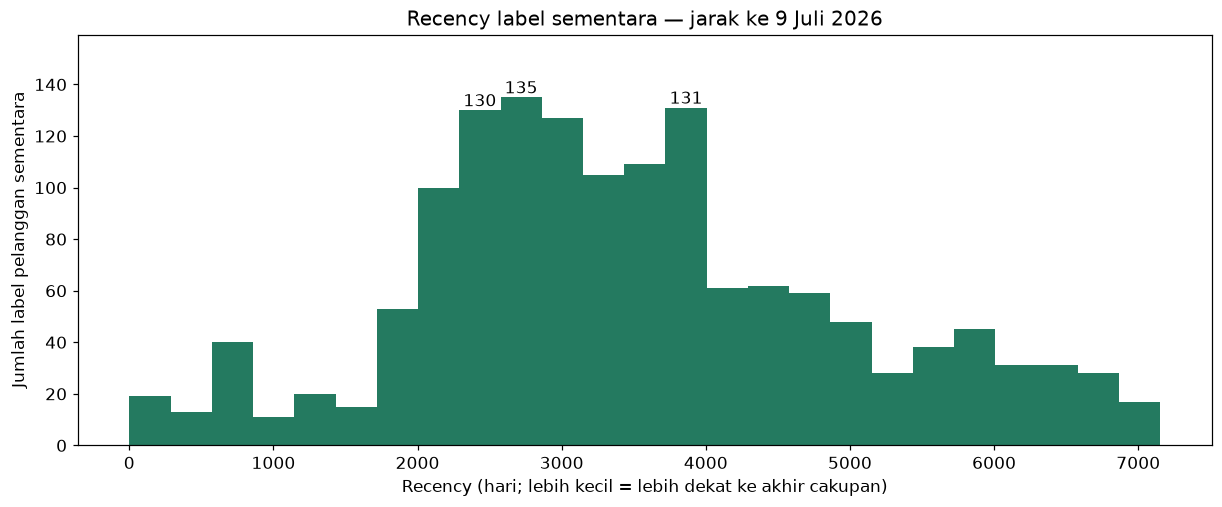

Median Recency adalah 3.306,50 hari dari tanggal acuan. Recency besar menunjukkan jarak yang lama dari transaksi terakhir yang lolos, tetapi belum membuktikan pelanggan berhenti bertransaksi karena kelompok ditahan tidak ikut dihitung.

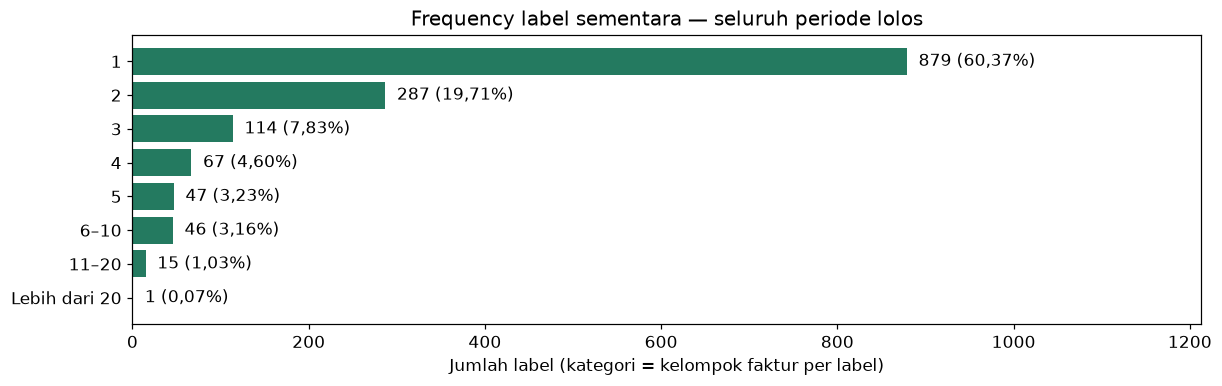

Frequency 1 ditemukan pada 879 dari 1.456 label (60,37%). Ini berarti satu kelompok faktur lolos selama seluruh cakupan analisis, bukan satu item atau satu pembelian pada tahun terbaru.

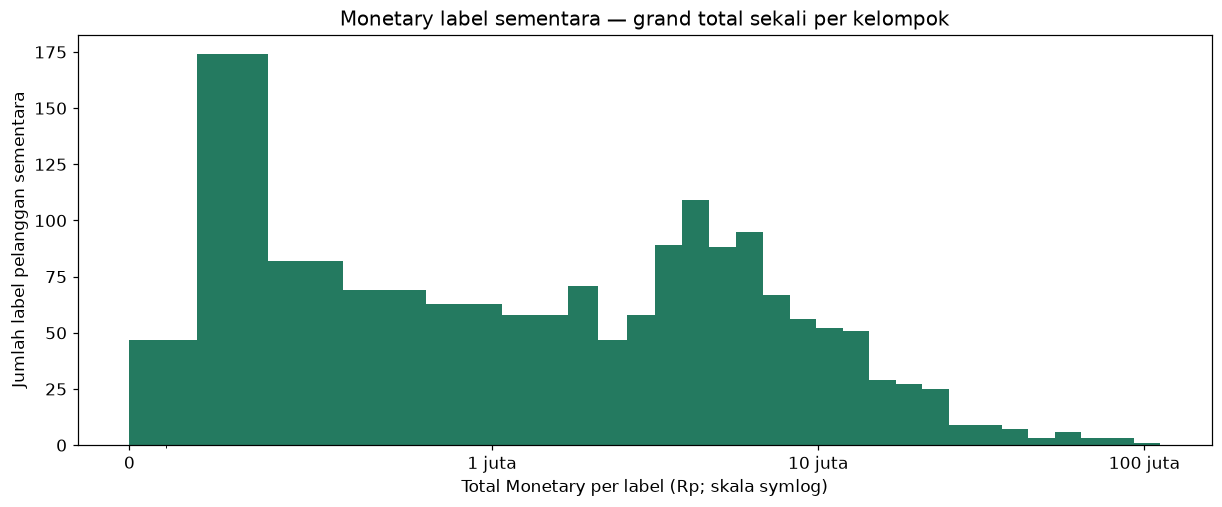

Median Monetary adalah Rp3.198.500,00; 37 label bernilai nol tetap dipertahankan. Nilai besar dapat berasal dari banyak kelompok atau kelompok bernominal besar; penanda dan bukti transaksi masih perlu diperiksa sebelum pemodelan.

In [29]:
rfm_count_t3=len(rfm_pelanggan)
fig,ax=plt.subplots(figsize=(11,4.5),layout='constrained')
counts,edges,patches=ax.hist(rfm_pelanggan.Recency,bins=25,color=GOOD)
for j in np.argsort(counts)[-3:]:
    if counts[j]:ax.text((edges[j]+edges[j+1])/2,counts[j],angka(counts[j]),ha='center',va='bottom')
ax.set_ylim(0,max(counts)*1.18)
ax.set(title='Recency label sementara — jarak ke 9 Juli 2026',xlabel='Recency (hari; lebih kecil = lebih dekat ke akhir cakupan)',ylabel='Jumlah label pelanggan sementara')
finish(fig)
note(f'Median Recency adalah {desimal_id(rfm_pelanggan.Recency.median())} hari dari tanggal acuan. Recency besar menunjukkan jarak yang lama dari transaksi terakhir yang lolos, tetapi belum membuktikan pelanggan berhenti bertransaksi karena kelompok ditahan tidak ikut dihitung.')
frequency_ranges_t3=pd.cut(rfm_pelanggan.Frequency,bins=[0,1,2,3,4,5,10,20,np.inf],labels=['1','2','3','4','5','6–10','11–20','Lebih dari 20']).value_counts(sort=False)
bars(frequency_ranges_t3,'Frequency label sementara — seluruh periode lolos','Jumlah label (kategori = kelompok faktur per label)',rfm_count_t3,GOOD)
one_frequency_t3=int(rfm_pelanggan.Frequency.eq(1).sum())
note(f'Frequency 1 ditemukan pada {angka(one_frequency_t3)} dari {angka(rfm_count_t3)} label ({pct(one_frequency_t3,rfm_count_t3)}). Ini berarti satu kelompok faktur lolos selama seluruh cakupan analisis, bukan satu item atau satu pembelian pada tahun terbaru.')
fig,ax=plt.subplots(figsize=(11,4.5),layout='constrained')
v=rfm_pelanggan.Monetary;scale=1e6
transformed=np.arcsinh(v/scale)
edge_t=np.linspace(transformed.min(),transformed.max()+1e-6,30)
ax.hist(v,bins=np.sinh(edge_t)*scale,color=GOOD)
ax.set_xscale('symlog',linthresh=scale)
ax.set_xticks([t for t in [0,1e6,1e7,1e8,1e9,1e10] if t<=max(v)*1.1])
ax.xaxis.set_major_formatter(FuncFormatter(lambda x,pos:f'{x/1e9:g} miliar' if x>=1e9 else f'{x/1e6:g} juta' if x>=1e6 else '0'))
ax.set(title='Monetary label sementara — grand total sekali per kelompok',xlabel='Total Monetary per label (Rp; skala symlog)',ylabel='Jumlah label pelanggan sementara')
finish(fig)
note(f'Median Monetary adalah Rp{desimal_id(rfm_pelanggan.Monetary.median())}; {angka(rfm_pelanggan.Monetary.eq(0).sum())} label bernilai nol tetap dipertahankan. Nilai besar dapat berasal dari banyak kelompok atau kelompok bernominal besar; penanda dan bukti transaksi masih perlu diperiksa sebelum pemodelan.')
assert int(frequency_ranges_t3.sum())==rfm_count_t3
assert one_frequency_t3==879 and int(rfm_pelanggan.Monetary.eq(0).sum())==37

Ketiga grafik memakai satuan label sementara, bukan baris Excel atau jumlah pelanggan yang sudah diverifikasi. Nilai nol atau besar tetap dipertahankan; bentuk distribusi belum menjadi alasan menghapus label. Batas cakupan cleaning dan risiko penyamaan nama tetap melekat pada hasil.

## Akhir Tahap 3
`rfm_pelanggan` berisi satu baris per label sementara dengan nilai RFM lengkap. `profil_pelanggan` menyimpan keragaman nama produk, tanggal terakhir, nominal terakhir, serta status ketidakpastiannya. RFM ini bersifat **eksploratif** karena hanya memakai kelompok lolos pemeriksaan internal dan nama standar sebagai label sementara; belum mewakili seluruh riwayat atau pelanggan tervalidasi.

Toleransi simulasi tidak mengganti sumber RFM. Pekerjaan berhenti pada pembentukan dan pemeriksaan tabel; scoring, transformasi untuk clustering, dan GMM belum dilakukan.

# Tahap 4 — Clustering, Evaluasi Model, dan Profil Segmen Pelanggan
## Menyamakan bahan yang dibandingkan
Keempat model memakai seluruh **1.456 label sementara** pada `rfm_pelanggan`, berasal dari **2.874 kelompok faktur** aturan awal Tahap 2. Seluruh rentang 2006–2026 dipertahankan; tambahan simulasi Rp1.000 tidak masuk. Keragaman produk dan nominal terakhir hanya membantu membaca profil sesudah model terbentuk, bukan sebagai fitur.

Pemeriksaan awal menghitung kosong, angka tidak terbatas, nol, negatif, rentang, dan kemiringan fitur. **Frequency dan Monetary memakai log1p** karena distribusinya berekor panjang; nilai nol tetap terbaca sebagai nol. **Recency tetap linear** karena kemiringannya relatif kecil. Memaksakan log Recency justru dapat memperbesar perbedaan beberapa hari paling dekat ke acuan. Sesudah itu, ketiganya distandardisasi agar satuan rupiah tidak mendominasi jarak. Jika ada nilai negatif, proses berhenti untuk menelusuri sumber, bukan menghapusnya.

Setiap baris gambar membandingkan satu fitur sebelum dan sesudah preprocessing. Sumbu vertikal adalah jumlah label. Sumbu kanan memakai satuan standar; untuk Frequency/Monetary itu satuan standar dari log1p, sedangkan untuk Recency dari hari. RFM asli disimpan untuk membaca profil akhir.

,kosong,non_finite,negatif,nol,minimum,median,maksimum,kemiringan_skew
Recency,0,0,0,0,"1,00","3.306,50","7.153,00","0,29"
Frequency,0,0,0,0,"1,00","1,00","24,00","4,07"
Monetary,0,0,0,37,"0,00","3.198.500,00","112.100.000,00","4,90"


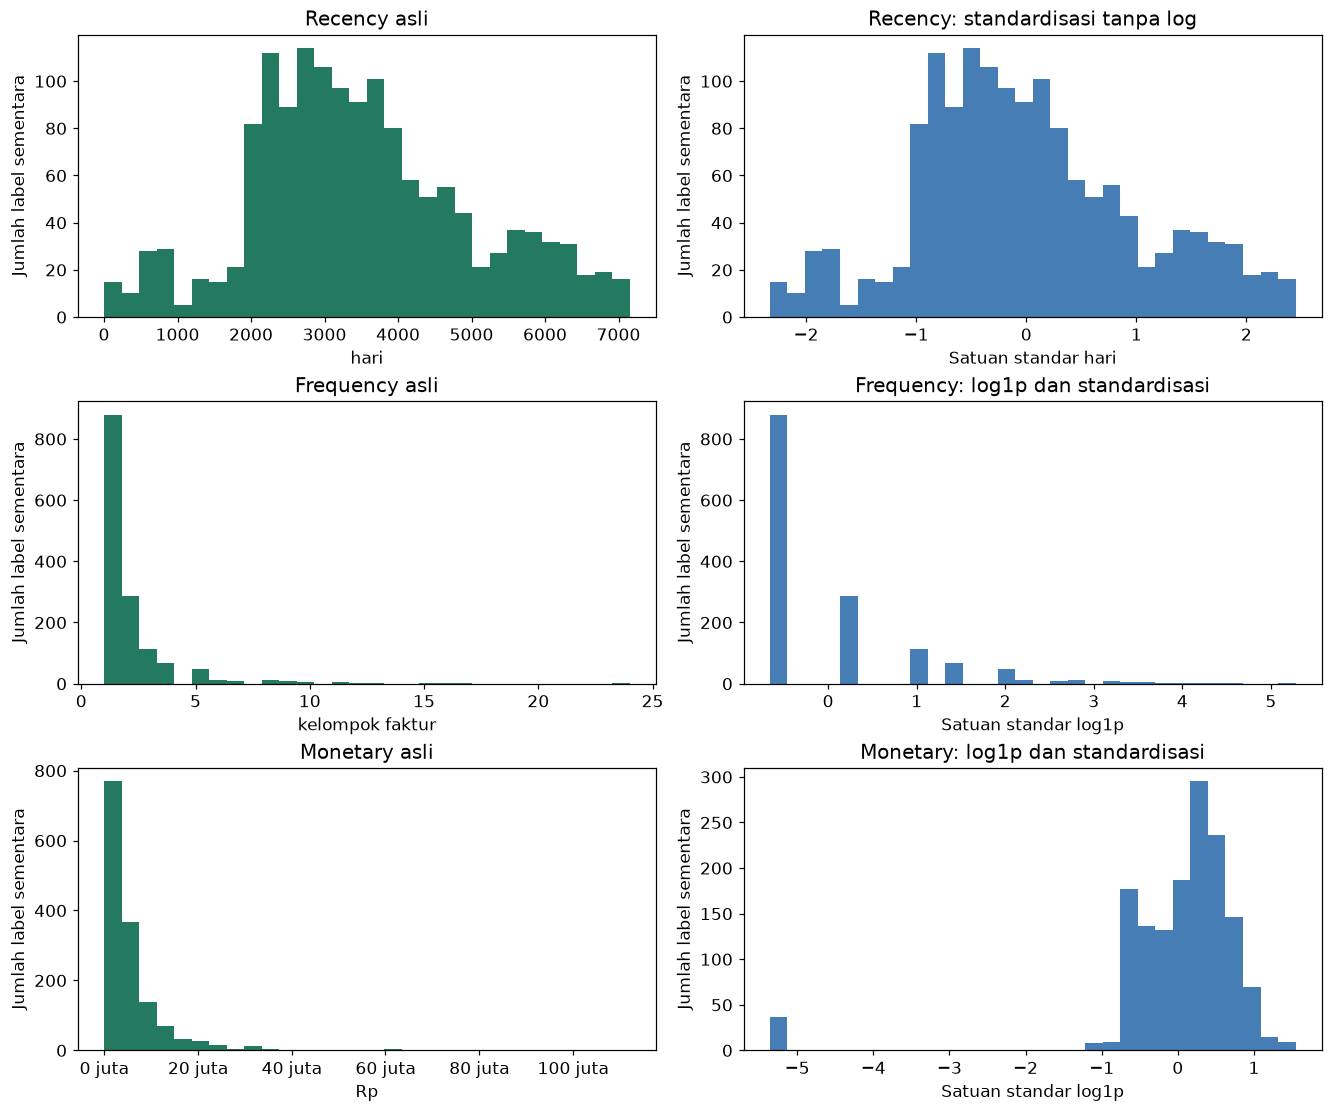

Seluruh 1.456 label ikut, termasuk 37 label dengan Monetary nol. Rentang rupiah yang semula jauh lebih besar daripada hari dan faktur sudah dipampatkan serta disamakan skalanya; tidak ada label ekstrem yang dibuang untuk memperoleh bentuk ini.

In [30]:
import importlib.util
import importlib.metadata
import warnings
import time
from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, pairwise_distances
from sklearn.decomposition import PCA
from threadpoolctl import threadpool_limits

snapshot_t4={name:globals()[name].copy(deep=True) for name in ['rfm_pelanggan','profil_pelanggan','item_audit','item_lolos','faktur_lolos','kasus_tinjau','rekonstruksi_kandidat']}
flags_before_t4=pd.DataFrame(flags_t2).copy(deep=True)
blocking_before_t4=set(blocking_t2)
rfm_asli_t4=rfm_pelanggan.copy(deep=True)
profil_asli_t4=profil_pelanggan.copy(deep=True)
fitur_t4=['Recency','Frequency','Monetary']
input_t4=rfm_asli_t4.set_index('id_samaran')[fitur_t4].copy()
assert len(input_t4)==1456 and input_t4.index.is_unique
assert rfm_asli_t4.Frequency.sum()==2874 and len(faktur_lolos)==2874
assert tanggal_awal_rfm==pd.Timestamp('2006-12-08') and tanggal_akhir_rfm==pd.Timestamp('2026-07-08')
assert np.isclose(rfm_asli_t4.Monetary.sum(),faktur_lolos.grand_total_konsisten_Rp.sum(),rtol=0,atol=.01)
cek_fitur_t4=pd.DataFrame({'kosong':input_t4.isna().sum(),'non_finite':(~np.isfinite(input_t4)).sum(),
 'negatif':input_t4.lt(0).sum(),'nol':input_t4.eq(0).sum(),'minimum':input_t4.min(),'median':input_t4.median(),
 'maksimum':input_t4.max(),'kemiringan_skew':input_t4.skew()})
show_decimal_2b(cek_fitur_t4)
assert input_t4.notna().all().all() and np.isfinite(input_t4.to_numpy()).all()
assert not input_t4.lt(0).any().any(), 'Periksa sumber nilai negatif sebelum memilih transformasi.'
fitur_log_t4=['Frequency','Monetary']
transformed_rfm_t4=input_t4.astype(float).copy()
transformed_rfm_t4[fitur_log_t4]=np.log1p(transformed_rfm_t4[fitur_log_t4])
scaler_t4=StandardScaler()
X_t4=scaler_t4.fit_transform(transformed_rfm_t4)
fitur_standar_t4=pd.DataFrame(X_t4,index=input_t4.index,columns=fitur_t4)
assert np.isfinite(X_t4).all() and X_t4.shape==(1456,3)
assert np.allclose(X_t4.mean(axis=0),0,atol=1e-12) and np.allclose(X_t4.std(axis=0),1)
fig,axes=plt.subplots(3,2,figsize=(12,10),layout='constrained')
for row,(feature,unit) in enumerate(zip(fitur_t4,['hari','kelompok faktur','Rp'])):
    axes[row,0].hist(input_t4[feature],bins=30,color=GOOD)
    axes[row,0].set(title=f'{feature} asli',xlabel=unit,ylabel='Jumlah label sementara')
    if feature=='Monetary':axes[row,0].xaxis.set_major_formatter(FuncFormatter(lambda x,pos:f'{x/1e6:g} juta'))
    axes[row,1].hist(fitur_standar_t4[feature],bins=30,color='#467db5')
    axes[row,1].set(title=f'{feature}: '+('log1p dan standardisasi' if feature in fitur_log_t4 else 'standardisasi tanpa log'),xlabel='Satuan standar '+('log1p' if feature in fitur_log_t4 else 'hari'),ylabel='Jumlah label sementara')
finish(fig)
note(f'Seluruh {angka(len(input_t4))} label ikut, termasuk {angka(input_t4.Monetary.eq(0).sum())} label dengan Monetary nol. Rentang rupiah yang semula jauh lebih besar daripada hari dan faktur sudah dipampatkan serta disamakan skalanya; tidak ada label ekstrem yang dibuang untuk memperoleh bentuk ini.')

Kemiringan Recency adalah **0,29**, dibanding Frequency **4,07** dan Monetary **4,90**. Karena itu transformasi tidak disamakan secara otomatis: log1p dipakai pada dua fitur yang lebih miring, lalu ketiganya distandardisasi. Seluruh **1.456 label**, termasuk **37 Monetary nol**, tetap ikut; histogram berubah karena skala, bukan pengurangan data.

## Memeriksa dependensi dan cara menjalankan K-Medoids
GMM, K-Means, dan Agglomerative memakai scikit-learn. Tabel dependensi memeriksa apakah paket K-Medoids terpasang dan dapat diimpor; kegagalan impor dicatat. Jika paket tidak tersedia, notebook tetap menjalankan K-Medoids dengan implementasi **alternate berbasis NumPy** di bawah ini. Hasilnya diberi nama yang menyebut algoritmanya, bukan diklaim sebagai hasil paket yang tidak dijalankan.

Medoid adalah anggota data yang dipilih sebagai pusat. Algoritma alternate bergantian menempatkan label ke medoid terdekat dan memilih anggota dengan jumlah jarak terkecil di setiap cluster. Ini berbeda dari PAM yang mencari pertukaran medoid lintas cluster; keduanya dapat berhenti pada hasil lokal. Sepuluh inisialisasi dengan seed tetap membantu membandingkan beberapa titik awal, tetapi tidak menjamin optimum global.

Contoh enam titik dipakai untuk memeriksa objective, keberadaan pusat pada data, serta penurunan total jarak. Matriks jarak Euclidean yang sama juga dipakai untuk Silhouette seluruh model, tanpa mengambil sampel label.

In [31]:
dependency_rows_t4=[]
for module in ['numpy','scipy','sklearn','sklearn_extra','kmedoids']:
    try:
        spec=importlib.util.find_spec(module)
        if spec is None:
            dependency_rows_t4.append({'modul':module,'status':'Tidak terpasang','versi':'—','catatan':'Kompatibilitas paket ini belum dapat diuji'})
        else:
            imported=__import__(module)
            dependency_rows_t4.append({'modul':module,'status':'Impor berhasil','versi':getattr(imported,'__version__','tidak dilaporkan'),'catatan':'Tersedia pada environment eksekusi'})
    except Exception as exc:
        dependency_rows_t4.append({'modul':module,'status':'Impor gagal','versi':'—','catatan':f'{type(exc).__name__}: {exc}'})
dependensi_t4=pd.DataFrame(dependency_rows_t4)
display(HTML(dependensi_t4.to_html(index=False)))

def kmedoids_alternate_t4(distance,k,seed=42,n_init=10,max_iter=300):
    distance=np.asarray(distance,dtype=float)
    n=len(distance)
    if distance.shape!=(n,n) or not np.isfinite(distance).all() or k<2 or k>=n:
        raise ValueError('Matriks jarak atau k tidak valid.')
    rng=np.random.default_rng(seed)
    best=None
    def assign(medoids):
        labels=np.argmin(distance[:,medoids],axis=1)
        # Ties between identical points must not create empty medoid clusters.
        labels[np.asarray(medoids)]=np.arange(k)
        objective=float(distance[np.arange(n),np.asarray(medoids)[labels]].sum())
        return labels,objective
    for restart in range(n_init):
        medoids=[int(rng.integers(n))]
        while len(medoids)<k:
            weights=distance[:,medoids].min(axis=1)**2
            weights[medoids]=0
            if weights.sum()>0:chosen=int(rng.choice(n,p=weights/weights.sum()))
            else:chosen=int(rng.choice(np.setdiff1d(np.arange(n),medoids)))
            medoids.append(chosen)
        medoids=np.asarray(medoids,dtype=int)
        labels,objective=assign(medoids);history=[objective];converged=False
        for iteration in range(1,max_iter+1):
            updated=medoids.copy()
            for c in range(k):
                members=np.flatnonzero(labels==c)
                costs=distance[np.ix_(members,members)].sum(axis=1)
                ties=members[np.isclose(costs,costs.min(),rtol=0,atol=1e-12)]
                updated[c]=medoids[c] if medoids[c] in ties else ties[0]
            new_labels,new_objective=assign(updated)
            assert new_objective<=objective+1e-8, 'Total jarak K-Medoids naik.'
            history.append(new_objective)
            converged=np.array_equal(updated,medoids)
            medoids,labels,objective=updated,new_labels,new_objective
            if converged:break
        result={'labels':labels.copy(),'medoids':medoids.copy(),'objective':objective,'n_iter':iteration,
                'converged':bool(converged),'history':history,'restart':restart}
        if best is None or (objective,not converged)<(best['objective'],not best['converged']):best=result
    return best

toy_t4=np.array([[0.,0.],[0.,1.],[0.,2.],[10.,0.],[10.,1.],[10.,2.]])
toy_d_t4=pairwise_distances(toy_t4)
toy_result_t4=kmedoids_alternate_t4(toy_d_t4,2,n_init=5)
assert np.isclose(toy_result_t4['objective'],4.) and len(np.unique(toy_result_t4['labels']))==2
assert np.all(np.diff(toy_result_t4['history'])<=1e-8)
assert np.isin(toy_result_t4['medoids'],np.arange(6)).all()
D_t4=pairwise_distances(X_t4,metric='euclidean');np.fill_diagonal(D_t4,0)
assert np.allclose(D_t4,D_t4.T) and np.all(D_t4>=0)
print('K-Medoids alternate NumPy: contoh enam titik lulus, objective = 4; pusat adalah anggota data.')

modul,status,versi,catatan
numpy,Impor berhasil,2.4.6,Tersedia pada environment eksekusi
scipy,Impor berhasil,1.17.1,Tersedia pada environment eksekusi
sklearn,Impor berhasil,1.9.1,Tersedia pada environment eksekusi
sklearn_extra,Tidak terpasang,—,Kompatibilitas paket ini belum dapat diuji
kmedoids,Tidak terpasang,—,Kompatibilitas paket ini belum dapat diuji


K-Medoids alternate NumPy: contoh enam titik lulus, objective = 4; pusat adalah anggota data.


`sklearn_extra` dan `kmedoids` tidak terpasang, sehingga kompatibilitas kedua paket tersebut belum dapat diuji; tidak ada hasil yang diklaim berasal dari keduanya. Implementasi **K-Medoids alternate NumPy** lulus contoh enam titik dengan objective 4 dan digunakan untuk seluruh k yang dibandingkan. Keterbatasannya adalah optimasi lokal dengan pergantian pusat di dalam cluster, berbeda dari PAM yang mencoba pertukaran lintas cluster.

## Menjalankan kandidat yang sama untuk empat model
Semua model mencoba **k = 2 sampai 8**, memakai urutan 1.456 ID dan tiga fitur hasil preprocessing yang sama. GMM memakai covariance full dan 10 inisialisasi; K-Means dan K-Medoids juga memakai 10 inisialisasi dengan seed 42. Agglomerative memakai Ward dan jarak Euclidean; model ini tidak membutuhkan seed.

Silhouette, Davies–Bouldin, dan Calinski–Harabasz dihitung untuk setiap konfigurasi yang benar-benar menghasilkan k cluster. Silhouette memakai seluruh label, tanpa sampling. Konvergensi GMM, jumlah cluster aktual, peringatan, jumlah iterasi, ukuran cluster, dan konfigurasi gagal disimpan. Nilai BIC hanya diisi untuk GMM. Pembatasan thread menjaga waktu eksekusi, bukan mengubah data yang dilatih.

In [32]:
SEED_T4=42
K_T4=list(range(2,9))
MODEL_T4=['GMM','K-Means','K-Medoids (alternate NumPy)','Agglomerative (Ward)']
parameter_model_t4=pd.DataFrame([
 ['GMM','full covariance; reg_covar=1e-6; tol=1e-3; max_iter=500; n_init=10','42'],
 ['K-Means','k-means++; algorithm=lloyd; max_iter=300; n_init=10','42'],
 ['K-Medoids (alternate NumPy)','Euclidean; D-squared initialization; max_iter=300; n_init=10; alternate','42'],
 ['Agglomerative (Ward)','linkage=ward; metric=euclidean','Tidak dipakai']
],columns=['model','parameter_tetap','random_seed'])
display(HTML(parameter_model_t4.to_html(index=False)))
model_t4={};labels_model_t4={};run_rows_t4=[]
with threadpool_limits(limits=1):
 for name in MODEL_T4:
  for k in K_T4:
   record={'model':name,'k':k,'status':'gagal','k_aktual':np.nan,'konvergen':None,'iterasi':np.nan,
           'silhouette':np.nan,'davies_bouldin':np.nan,'calinski_harabasz':np.nan,'BIC':np.nan,
           'cluster_min':np.nan,'cluster_max':np.nan,'persen_cluster_min':np.nan,'peringatan':'','error':''}
   start=time.perf_counter()
   try:
    with warnings.catch_warnings(record=True) as captured:
     warnings.simplefilter('always')
     if name=='GMM':
      fitted=GaussianMixture(n_components=k,covariance_type='full',reg_covar=1e-6,tol=1e-3,max_iter=500,n_init=10,random_state=SEED_T4).fit(X_t4)
      labels=fitted.predict(X_t4)
      record.update(konvergen=bool(fitted.converged_),iterasi=int(fitted.n_iter_),BIC=float(fitted.bic(X_t4)))
     elif name=='K-Means':
      fitted=KMeans(n_clusters=k,init='k-means++',algorithm='lloyd',max_iter=300,n_init=10,random_state=SEED_T4).fit(X_t4)
      labels=fitted.labels_.copy();record['iterasi']=int(fitted.n_iter_)
     elif name=='K-Medoids (alternate NumPy)':
      fitted=kmedoids_alternate_t4(D_t4,k,seed=SEED_T4,n_init=10,max_iter=300)
      labels=fitted['labels'].copy();record.update(konvergen=fitted['converged'],iterasi=fitted['n_iter'])
     else:
      fitted=AgglomerativeClustering(n_clusters=k,linkage='ward',metric='euclidean').fit(X_t4)
      labels=fitted.labels_.copy()
    record['peringatan']=' | '.join(sorted({f'{type(w.message).__name__}: {w.message}' for w in captured}))
    unique,counts=np.unique(labels,return_counts=True)
    record['k_aktual']=len(unique)
    if len(unique)!=k:raise ValueError(f'Jumlah cluster aktual {len(unique)} berbeda dari k={k}.')
    record.update(silhouette=float(silhouette_score(D_t4,labels,metric='precomputed')),
      davies_bouldin=float(davies_bouldin_score(X_t4,labels)),calinski_harabasz=float(calinski_harabasz_score(X_t4,labels)),
      cluster_min=int(counts.min()),cluster_max=int(counts.max()),persen_cluster_min=100*counts.min()/len(X_t4),status='berhasil')
    model_t4[(name,k)]=fitted;labels_model_t4[(name,k)]=np.asarray(labels).copy()
   except Exception as exc:
    record['error']=f'{type(exc).__name__}: {exc}'
   record['waktu_detik']=time.perf_counter()-start
   run_rows_t4.append(record)
audit_model_t4=pd.DataFrame(run_rows_t4)
hasil_model_t4=audit_model_t4.loc[audit_model_t4.status.eq('berhasil')].copy()
gagal_model_t4=audit_model_t4.loc[~audit_model_t4.status.eq('berhasil')].copy()
display(HTML(audit_model_t4[['model','k','status','k_aktual','konvergen','iterasi','peringatan','error']].to_html(index=False,na_rep='Tidak berlaku')))
print('Konfigurasi berhasil:',len(hasil_model_t4),'dari',len(audit_model_t4),'; gagal:',len(gagal_model_t4))
assert len(audit_model_t4)==28 and len(hasil_model_t4)>0
assert all(len(labels)==1456 for labels in labels_model_t4.values())

model,parameter_tetap,random_seed
GMM,full covariance; reg_covar=1e-6; tol=1e-3; max_iter=500; n_init=10,42
K-Means,k-means++; algorithm=lloyd; max_iter=300; n_init=10,42
K-Medoids (alternate NumPy),Euclidean; D-squared initialization; max_iter=300; n_init=10; alternate,42
Agglomerative (Ward),linkage=ward; metric=euclidean,Tidak dipakai


model,k,status,k_aktual,konvergen,iterasi,peringatan,error
GMM,2,berhasil,2,True,11.0,,
GMM,3,berhasil,3,True,12.0,,
GMM,4,berhasil,4,True,15.0,,
GMM,5,berhasil,5,True,19.0,,
GMM,6,berhasil,6,True,15.0,,
GMM,7,berhasil,7,True,19.0,,
GMM,8,berhasil,8,True,20.0,,
K-Means,2,berhasil,2,None,13.0,,
K-Means,3,berhasil,3,None,20.0,,
K-Means,4,berhasil,4,None,8.0,,


Konfigurasi berhasil: 28 dari 28 ; gagal: 0


Seluruh **28 konfigurasi berhasil** dan menghasilkan jumlah cluster sesuai k; tidak ada konfigurasi gagal atau peringatan yang tercatat pada eksekusi ini. Ketujuh kandidat GMM konvergen. Satu baris audit tetap mewakili model–k, bukan label, dan konvergensi hanya berarti kriteria berhenti dipenuhi, bukan jaminan optimum global atau segmen bisnis benar.

## Membaca skor tanpa menganggap satu metrik menjawab semuanya
**Silhouette** dan **Calinski–Harabasz** umumnya lebih baik jika tinggi; **Davies–Bouldin** lebih baik jika rendah. Ketiganya melihat bentuk kelompok pada ruang tiga fitur standar, bukan membuktikan bahwa kelompok itu kategori bisnis yang benar. Ukuran cluster terkecil/terbesar menunjukkan apakah skor bagus dibarengi kelompok yang sangat kecil.

**BIC hanya dibandingkan antar-GMM** yang memakai data dan preprocessing sama, dengan nilai lebih rendah sebagai petunjuk yang lebih baik. BIC bukan skor pembanding GMM terhadap K-Means atau Ward. Tabel pemenang per metrik memperlihatkan bila ukuran pemisahan dan kecocokan distribusi memberi pilihan k berbeda.

Skor ini bukan persentase akurasi: belum ada label segmen bisnis yang menjadi acuan kebenaran.


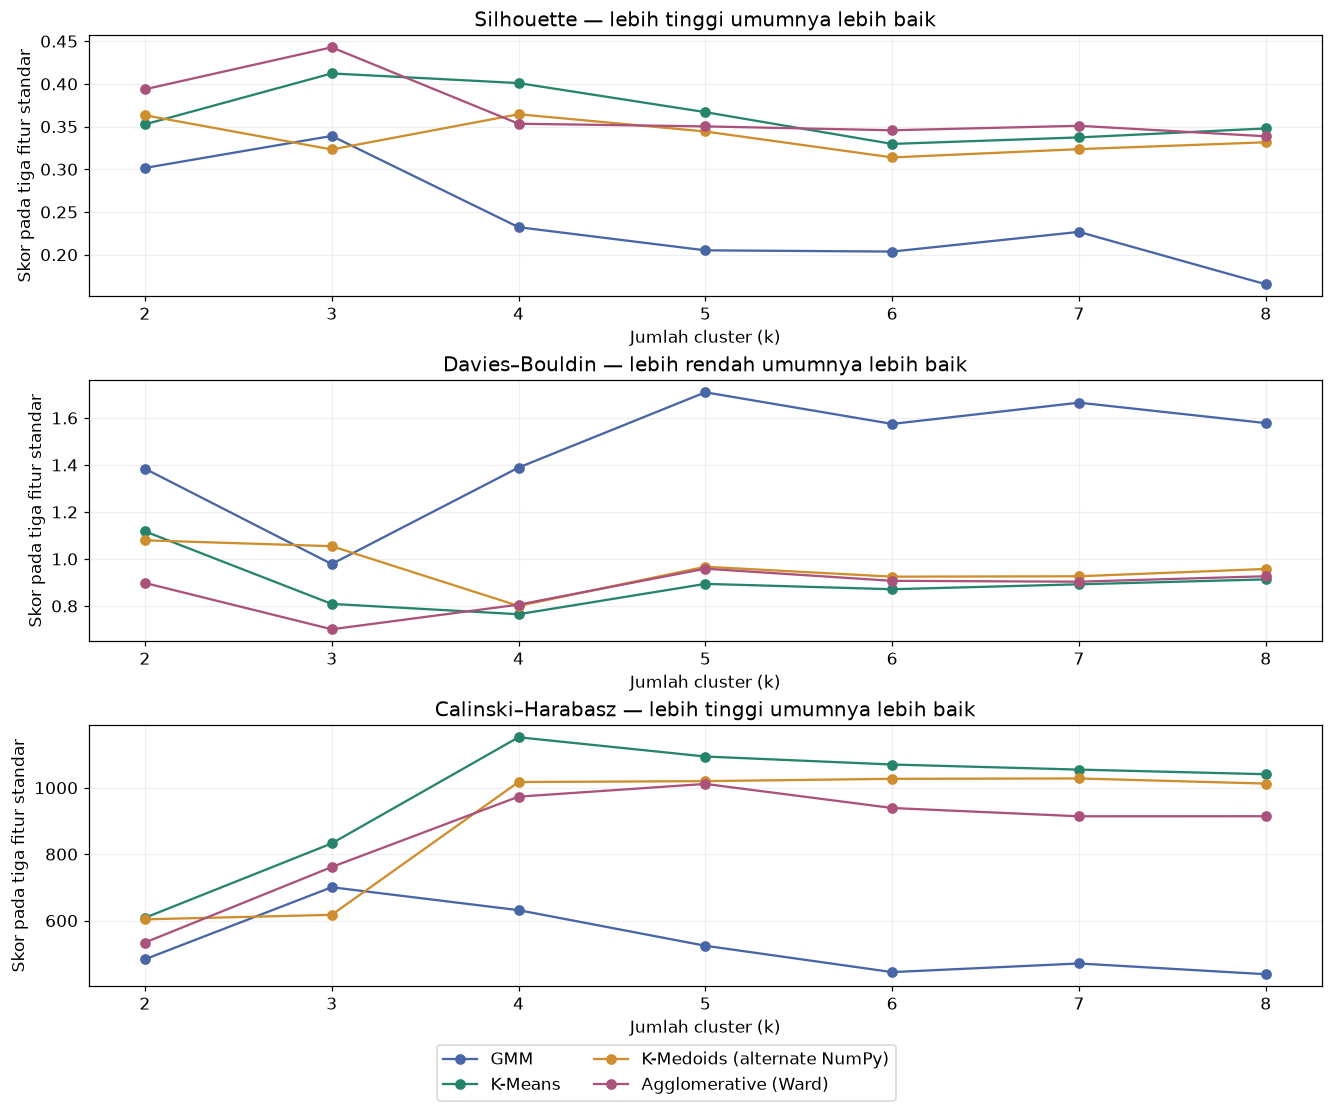

Silhouette tertinggi di antara konfigurasi berhasil adalah Agglomerative (Ward), k=3, dengan skor 0.443. Pemenang metrik lain pada tabel tidak harus sama; ukuran cluster dan profil asli masih perlu dibaca sebelum menentukan hasil akhir.

,BIC,konvergen,cluster_min,cluster_max
k,,,,
2,"982,16",True,577,879
3,"-876,88",True,37,847
4,"-4.222,31",True,37,847
5,"-5.434,52",True,37,847
6,"-5.422,33",True,20,847
7,"-5.582,28",True,37,465
8,"-5.774,15",True,37,591


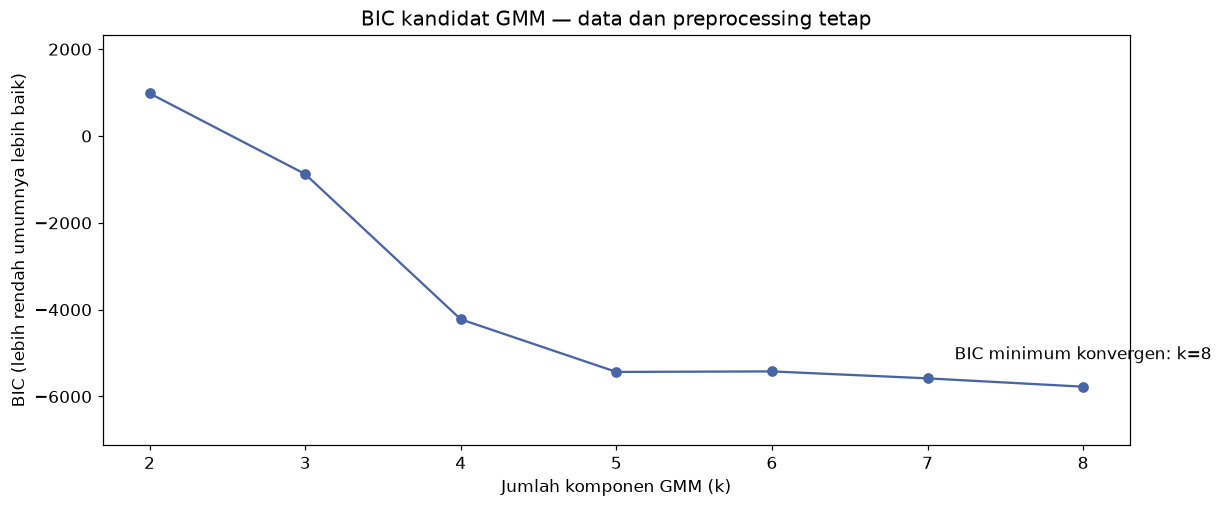

7 dari 7 kandidat GMM berhasil memenuhi kriteria konvergensi. BIC menilai kecocokan distribusi dengan penalti kompleksitas; nilai rendah belum tentu menghasilkan pemisahan jarak atau profil yang paling mudah digunakan.

In [33]:
kolom_skor_t4=['model','k','silhouette','davies_bouldin','calinski_harabasz','cluster_min','cluster_max','persen_cluster_min']
show_decimal_2b(hasil_model_t4[kolom_skor_t4].set_index(['model','k']))
warna_model_t4=dict(zip(MODEL_T4,['#4865a5','#26846d','#cf8e2d','#aa527b']))
fig,axes=plt.subplots(3,1,figsize=(12,10),layout='constrained')
for ax,col,title in zip(axes,['silhouette','davies_bouldin','calinski_harabasz'],['Silhouette — lebih tinggi umumnya lebih baik','Davies–Bouldin — lebih rendah umumnya lebih baik','Calinski–Harabasz — lebih tinggi umumnya lebih baik']):
    for name in MODEL_T4:
        t=hasil_model_t4.loc[hasil_model_t4.model.eq(name)].sort_values('k')
        if len(t):ax.plot(t.k,t[col],marker='o',label=name,color=warna_model_t4[name])
    ax.set(title=title,xlabel='Jumlah cluster (k)',ylabel='Skor pada tiga fitur standar',xticks=K_T4)
    ax.grid(alpha=.2)
fig.legend(*axes[0].get_legend_handles_labels(),loc='outside lower center',ncol=2)
finish(fig)
winner_rows_t4=[]
for name,t in hasil_model_t4.groupby('model',sort=False):
    for metric,higher in [('silhouette',True),('davies_bouldin',False),('calinski_harabasz',True)]:
        row=t.loc[t[metric].idxmax() if higher else t[metric].idxmin()]
        winner_rows_t4.append({'model':name,'metrik':metric,'k_terbaik':int(row.k),'skor':row[metric]})
pemenang_metrik_t4=pd.DataFrame(winner_rows_t4)
show_decimal_2b(pemenang_metrik_t4.set_index(['model','metrik']))
row_sil_global_t4=hasil_model_t4.loc[hasil_model_t4.silhouette.idxmax()]
note(f'Silhouette tertinggi di antara konfigurasi berhasil adalah {row_sil_global_t4.model}, k={int(row_sil_global_t4.k)}, dengan skor {row_sil_global_t4.silhouette:.3f}. Pemenang metrik lain pada tabel tidak harus sama; ukuran cluster dan profil asli masih perlu dibaca sebelum menentukan hasil akhir.')
gmm_scores_t4=hasil_model_t4.loc[hasil_model_t4.model.eq('GMM')].sort_values('k')
gmm_bic_eligible_t4=gmm_scores_t4.loc[gmm_scores_t4.konvergen.eq(True)]
if len(gmm_scores_t4):
    show_decimal_2b(gmm_scores_t4[['k','BIC','konvergen','cluster_min','cluster_max']].set_index('k'))
    fig,ax=plt.subplots(figsize=(11,4.5),layout='constrained')
    ax.plot(gmm_scores_t4.k,gmm_scores_t4.BIC,marker='o',color=warna_model_t4['GMM'])
    ax.set(title='BIC kandidat GMM — data dan preprocessing tetap',xlabel='Jumlah komponen GMM (k)',ylabel='BIC (lebih rendah umumnya lebih baik)',xticks=K_T4)
    if len(gmm_bic_eligible_t4):
        gmm_bic_best_t4=gmm_bic_eligible_t4.loc[gmm_bic_eligible_t4.BIC.idxmin()]
        ax.annotate(f'BIC minimum konvergen: k={int(gmm_bic_best_t4.k)}',xy=(gmm_bic_best_t4.k,gmm_bic_best_t4.BIC),xytext=(0,18),textcoords='offset points',ha='center')
    ax.margins(y=.2);finish(fig)
    note(f'{int(gmm_scores_t4.konvergen.eq(True).sum())} dari {len(gmm_scores_t4)} kandidat GMM berhasil memenuhi kriteria konvergensi. BIC menilai kecocokan distribusi dengan penalti kompleksitas; nilai rendah belum tentu menghasilkan pemisahan jarak atau profil yang paling mudah digunakan.')

Metrik tidak memberi satu jawaban yang sama. **Ward k=3** menghasilkan Silhouette tertinggi **0,443** dan Davies–Bouldin terendah **0,701**, sedangkan **K-Means k=4** menghasilkan Calinski–Harabasz tertinggi **1.151,82**. Grafik memperlihatkan pertukaran antara pemisahan jarak dan bentuk kelompok, bukan skor yang boleh dijumlahkan langsung.

Untuk GMM, ketujuh kandidat konvergen dan **BIC minimum ada pada k=8, yaitu −5.774,15**. Namun Silhouette kandidat itu hanya **0,165**; kecocokan campuran Gaussian yang lebih baik menurut BIC tidak otomatis berarti pemisahan cluster atau profil bisnis lebih baik. BIC tidak dipakai sebagai pembanding langsung terhadap model lain.

## Menentukan kandidat yang layak dibaca sebagai segmen
Agar keputusan tidak otomatis memenangkan GMM, tiga metrik diberi peringkat: Silhouette dan Calinski–Harabasz menurun, Davies–Bouldin menaik. Rata-rata tiga peringkat menjadi ringkasan dengan bobot sama; ini alat bantu pemilihan, bukan indeks statistik baku. Jika seri, Silhouette lebih tinggi lalu ukuran cluster terkecil lebih besar diutamakan.

Konfigurasi yang tidak konvergen tidak dipilih. Cluster berisi kurang dari **1% label, dibulatkan ke atas**, diberi penanda kecil; kandidat tanpa cluster sekecil itu diprioritaskan agar segmen tidak terutama bergantung pada sedikit label. Ambang ini pilihan eksploratif untuk pembacaan profil, bukan alasan membuang label atau aturan universal. Jika tidak ada kandidat yang memenuhi, notebook memperlihatkan keterbatasannya.

Tabel kandidat terbaik per model memuat skor dan ukuran. Profil calon tersebut dihitung kembali pada **hari, jumlah kelompok faktur, dan rupiah asli** supaya pemilihan juga bisa diperiksa dari perbedaan yang dapat dijelaskan.

In [34]:
peringkat_model_t4=hasil_model_t4.copy()
peringkat_model_t4['rank_silhouette']=peringkat_model_t4.silhouette.rank(ascending=False,method='average')
peringkat_model_t4['rank_DB']=peringkat_model_t4.davies_bouldin.rank(ascending=True,method='average')
peringkat_model_t4['rank_CH']=peringkat_model_t4.calinski_harabasz.rank(ascending=False,method='average')
peringkat_model_t4['rata_rank']=peringkat_model_t4[['rank_silhouette','rank_DB','rank_CH']].mean(axis=1)
MIN_CLUSTER_T4=int(np.ceil(.01*len(X_t4)))
peringkat_model_t4['cluster_kecil']=peringkat_model_t4.cluster_min.lt(MIN_CLUSTER_T4)
peringkat_model_t4['konvergensi_memadai']=~peringkat_model_t4.konvergen.eq(False)
valid_candidates_t4=peringkat_model_t4.loc[peringkat_model_t4.konvergensi_memadai].copy()
selection_pool_t4=valid_candidates_t4.loc[~valid_candidates_t4.cluster_kecil].copy()
if selection_pool_t4.empty:
    selection_pool_t4=valid_candidates_t4.copy()
    print('Tidak ada kandidat tanpa cluster kecil; hasil memerlukan peninjauan lebih hati-hati.')
assert len(selection_pool_t4)>0
sort_t4=['rata_rank','silhouette','cluster_min','model','k']
ascending_t4=[True,False,False,True,True]
selection_pool_t4=selection_pool_t4.sort_values(sort_t4,ascending=ascending_t4)
selected_row_t4=selection_pool_t4.iloc[0].copy()
model_terpilih_t4=str(selected_row_t4.model);k_terpilih_t4=int(selected_row_t4.k)
key_terpilih_t4=(model_terpilih_t4,k_terpilih_t4)
best_model_rows_t4=[]
for name in MODEL_T4:
    subset=valid_candidates_t4.loc[valid_candidates_t4.model.eq(name)]
    preferred=subset.loc[~subset.cluster_kecil]
    if preferred.empty:preferred=subset
    if len(preferred):best_model_rows_t4.append(preferred.sort_values(sort_t4,ascending=ascending_t4).iloc[0])
kandidat_terbaik_t4=pd.DataFrame(best_model_rows_t4)
show_decimal_2b(kandidat_terbaik_t4[['model','k','silhouette','davies_bouldin','calinski_harabasz','BIC','cluster_min','cluster_max','cluster_kecil','rata_rank']].set_index('model'))
profil_calon_rows_t4=[]
for candidate_row in best_model_rows_t4:
    candidate_key=(candidate_row.model,int(candidate_row.k))
    original=input_t4.copy();original['cluster']=labels_model_t4[candidate_key]
    t=original.groupby('cluster').agg(jumlah_label=('Recency','size'),median_Recency_hari=('Recency','median'),median_Frequency=('Frequency','median'),median_Monetary_Rp=('Monetary','median'))
    t.insert(0,'model',candidate_key[0]);t.insert(1,'k',candidate_key[1]);profil_calon_rows_t4.append(t.reset_index())
profil_calon_t4=pd.concat(profil_calon_rows_t4,ignore_index=True)
display(HTML(profil_calon_t4.to_html(index=False,float_format=desimal_id)))
note(f'Pilihan menurut aturan yang diumumkan adalah {model_terpilih_t4}, k={k_terpilih_t4}: Silhouette {selected_row_t4.silhouette:.3f}, Davies–Bouldin {selected_row_t4.davies_bouldin:.3f}, dan Calinski–Harabasz {selected_row_t4.calinski_harabasz:.1f}. Cluster terkecilnya berisi {int(selected_row_t4.cluster_min)} label; batas penanda kecil adalah {MIN_CLUSTER_T4} dari {len(X_t4)} label.')

,k,silhouette,davies_bouldin,calinski_harabasz,BIC,cluster_min,cluster_max,cluster_kecil,rata_rank
model,,,,,,,,,
GMM,3,"0,34","0,98","700,27","-876,88",37,847,False,"17,33"
K-Means,4,"0,40","0,76","1.151,82",NaN,37,752,False,"2,00"
K-Medoids (alternate NumPy),4,"0,36","0,80","1.017,04",NaN,37,591,False,"6,00"
Agglomerative (Ward),3,"0,44","0,70","761,08",NaN,37,1204,False,"6,33"


cluster,model,k,jumlah_label,median_Recency_hari,median_Frequency,median_Monetary_Rp
0,GMM,3,572,"2.911,00","3,00","4.375.000,00"
1,GMM,3,847,"3.641,00","1,00","2.500.000,00"
2,GMM,3,37,"2.534,00","1,00","0,00"
0,K-Means,4,261,"2.598,00","4,00","7.815.000,00"
1,K-Means,4,752,"2.995,00","1,00","4.050.000,00"
2,K-Means,4,406,"5.318,50","1,00","750.000,00"
3,K-Means,4,37,"2.534,00","1,00","0,00"
0,K-Medoids (alternate NumPy),4,457,"2.627,00","3,00","6.075.000,00"
1,K-Medoids (alternate NumPy),4,37,"2.534,00","1,00","0,00"
2,K-Medoids (alternate NumPy),4,371,"5.369,00","1,00","600.000,00"


Pilihan menurut aturan yang diumumkan adalah K-Means, k=4: Silhouette 0.401, Davies–Bouldin 0.765, dan Calinski–Harabasz 1151.8. Cluster terkecilnya berisi 37 label; batas penanda kecil adalah 15 dari 1456 label.

**K-Means k=4 dipilih sebagai kompromi**, dengan Silhouette **0,401**, Davies–Bouldin **0,765**, dan Calinski–Harabasz **1.151,82**. Cluster terkecil **37 label (2,54%)** berada di atas penanda 15 label; cluster terbesar berisi **752 label (51,65%)**. Ini bukan model dengan Silhouette tertinggi.

Ward k=3 memiliki skor jarak yang lebih baik, tetapi satu cluster menampung **1.204 dari 1.456 label (82,69%)**. Pada profil calon, K-Means k=4 membedakan pembelian berulang bernilai lebih tinggi, belanja nol, frekuensi rendah bernilai relatif tinggi, dan riwayat lebih lama bernilai rendah. Pemisahan yang bisa dijelaskan itu, bersama Calinski–Harabasz dan rata-rata peringkat tiga metrik, menjadi alasan pemilihan; bukan karena K-Means harus menang.

## Mengembalikan hasil ke RFM asli dan memberi nama segmen
Nomor cluster dari algoritma tidak memiliki urutan bisnis. Untuk memudahkan pembacaan, cluster akhir diurutkan berdasarkan median Recency dari kecil ke besar dan diberi kode C1, C2, dan seterusnya. Nama segmen baru ditentukan sesudah median aslinya terlihat, relatif terhadap median seluruh subset.

Satu baris profil berikut adalah satu cluster. Persentase label dibagi seluruh **1.456 label**; total Monetary adalah nilai kelompok faktur lolos yang terhimpun pada anggota segmen. Median nominal terakhir hanya memakai label yang nilainya dapat ditetapkan, dan jumlah yang belum pasti tetap dilaporkan. Informasi profil pendamping tidak ikut melatih model.

Usulan tindakan adalah contoh pengujian bisnis berdasarkan pola historis, bukan kesimpulan bahwa label tertentu sudah berhenti belanja. Riwayat panjang dan faktur yang tertahan tetap membatasi interpretasi.

In [35]:
labels_akhir_native_t4=labels_model_t4[key_terpilih_t4].copy()
native_profile_t4=input_t4.assign(cluster_native=labels_akhir_native_t4).groupby('cluster_native')[fitur_t4].median()
ordered_native_t4=native_profile_t4.sort_values(['Recency','Monetary'],ascending=[True,False]).index.tolist()
map_cluster_t4={int(native):f'C{j+1}' for j,native in enumerate(ordered_native_t4)}
hasil_cluster_pelanggan=input_t4.copy()
hasil_cluster_pelanggan['cluster_native']=labels_akhir_native_t4
hasil_cluster_pelanggan['cluster']=pd.Series(labels_akhir_native_t4,index=input_t4.index).map(map_cluster_t4)
profile_by_id_t4=profil_asli_t4.set_index('id_samaran')
hasil_cluster_pelanggan=hasil_cluster_pelanggan.join(profile_by_id_t4[['keragaman_nama_produk','nominal_faktur_terakhir_Rp','status_nominal_terakhir']])
profil_cluster_t4=hasil_cluster_pelanggan.groupby('cluster',sort=False).agg(
    jumlah_label=('Recency','size'),median_Recency_hari=('Recency','median'),median_Frequency=('Frequency','median'),
    median_Monetary_Rp=('Monetary','median'),total_Monetary_Rp=('Monetary','sum'),
    label_Monetary_nol=('Monetary',lambda v:int(v.eq(0).sum())),
    median_keragaman_produk=('keragaman_nama_produk','median'),
    median_nominal_terakhir_Rp=('nominal_faktur_terakhir_Rp','median'),
    label_nominal_terakhir_diketahui=('nominal_faktur_terakhir_Rp','count'))
profil_cluster_t4=profil_cluster_t4.reindex([f'C{i+1}' for i in range(k_terpilih_t4)])
profil_cluster_t4.insert(1,'persen_label',100*profil_cluster_t4.jumlah_label/len(input_t4))
profil_cluster_t4['label_nominal_terakhir_belum_pasti']=profil_cluster_t4.jumlah_label-profil_cluster_t4.label_nominal_terakhir_diketahui
profil_cluster_t4['persen_Monetary']=100*profil_cluster_t4.total_Monetary_Rp/input_t4.Monetary.sum()
median_global_t4=input_t4.median()
nama_rows_t4=[]
for cluster,row in profil_cluster_t4.iterrows():
    recent=row.median_Recency_hari<=median_global_t4.Recency
    high=row.median_Monetary_Rp>=median_global_t4.Monetary
    frequent=row.median_Frequency>median_global_t4.Frequency
    if row.label_Monetary_nol==row.jumlah_label:
        name='Nominal belanja tercatat nol'
        action='Telusuri arti grand total nol dan dokumen sumber sebelum menetapkan tindakan komersial; jangan menganggap label ini tanpa nilai bisnis.'
    elif frequent and high:
        name='Pembelian berulang, belanja lebih tinggi'
        action='Setelah memastikan identitas dan kebutuhan terkini, uji rekomendasi atau bundling produk pelengkap pada label dengan pembelian berulang.'
    elif not recent and not high:
        name='Riwayat lebih lama, belanja relatif rendah'
        action='Periksa riwayat terbaru dan kesesuaian label terlebih dahulu; bila masih relevan, uji komunikasi berbiaya rendah, bukan menyimpulkan sudah berhenti belanja.'
    elif not frequent and high:
        name='Frekuensi rendah, belanja di atas median'
        action='Validasi kebutuhan terkini lalu uji penawaran pembelian ulang atau produk pelengkap; Frequency rendah hanya menggambarkan kelompok yang lolos.'
    else:
        name=('Transaksi relatif baru' if recent else 'Transaksi relatif lama')+(', belanja lebih tinggi' if high else ', belanja lebih rendah')
        action='Konfirmasikan identitas dan riwayat terbaru, lalu uji penawaran yang sesuai kebutuhan sebelum memperluas tindakan.'
    evidence=f'{angka(row.jumlah_label)} label ({pct(row.jumlah_label,len(input_t4))}); median R {desimal_id(row.median_Recency_hari)} hari, F {desimal_id(row.median_Frequency)} kelompok, M Rp{desimal_id(row.median_Monetary_Rp)}; median {desimal_id(row.median_keragaman_produk)} nama produk standar'
    nama_rows_t4.append({'cluster':cluster,'nama_segmen':name,'bukti_RFM':evidence,'contoh_tindakan':action})
tindakan_segmen_t4=pd.DataFrame(nama_rows_t4).set_index('cluster')
profil_cluster_t4.insert(0,'nama_segmen',tindakan_segmen_t4.nama_segmen)
hasil_cluster_pelanggan['nama_segmen']=hasil_cluster_pelanggan.cluster.map(tindakan_segmen_t4.nama_segmen)
show_decimal_2b(profil_cluster_t4[['jumlah_label','persen_label','median_Recency_hari','median_Frequency','median_Monetary_Rp','total_Monetary_Rp']])
show_decimal_2b(profil_cluster_t4[['median_keragaman_produk','median_nominal_terakhir_Rp','label_nominal_terakhir_diketahui','label_nominal_terakhir_belum_pasti','label_Monetary_nol','persen_Monetary']])
display(HTML(tindakan_segmen_t4.to_html()))
contoh_cluster_t4=hasil_cluster_pelanggan.reset_index().iloc[:5][['id_samaran','cluster','nama_segmen','Recency','Frequency','Monetary']]
display(HTML(contoh_cluster_t4.to_html(index=False,float_format=desimal_id)))
note(f'Jumlah anggota seluruh segmen adalah {angka(profil_cluster_t4.jumlah_label.sum())} label dan total Monetary Rp{desimal_id(profil_cluster_t4.total_Monetary_Rp.sum())}. Pembanding nama segmen adalah median subset: Recency {desimal_id(median_global_t4.Recency)} hari, Frequency {desimal_id(median_global_t4.Frequency)} kelompok, dan Monetary Rp{desimal_id(median_global_t4.Monetary)}; kata baru atau tinggi bersifat relatif terhadap cakupan ini.')

,jumlah_label,persen_label,median_Recency_hari,median_Frequency,median_Monetary_Rp,total_Monetary_Rp
cluster,,,,,,
C1,37,"2,54","2.534,00","1,00","0,00","0,00"
C2,261,"17,93","2.598,00","4,00","7.815.000,00","3.355.853.050,00"
C3,752,"51,65","2.995,00","1,00","4.050.000,00","4.182.808.512,39"
C4,406,"27,88","5.318,50","1,00","750.000,00","686.535.100,00"


,median_keragaman_produk,median_nominal_terakhir_Rp,label_nominal_terakhir_diketahui,label_nominal_terakhir_belum_pasti,label_Monetary_nol,persen_Monetary
cluster,,,,,,
C1,"1,00","0,00",37,0,37,"0,00"
C2,"6,00","600.000,00",253,8,0,"40,80"
C3,"2,00","3.650.000,00",744,8,0,"50,85"
C4,"1,00","350.000,00",403,3,0,"8,35"


,nama_segmen,bukti_RFM,contoh_tindakan
cluster,,,
C1,Nominal belanja tercatat nol,"37 label (2,54%); median R 2.534,00 hari, F 1,00 kelompok, M Rp0,00; median 1,00 nama produk standar",Telusuri arti grand total nol dan dokumen sumber sebelum menetapkan tindakan komersial; jangan menganggap label ini tanpa nilai bisnis.
C2,"Pembelian berulang, belanja lebih tinggi","261 label (17,93%); median R 2.598,00 hari, F 4,00 kelompok, M Rp7.815.000,00; median 6,00 nama produk standar","Setelah memastikan identitas dan kebutuhan terkini, uji rekomendasi atau bundling produk pelengkap pada label dengan pembelian berulang."
C3,"Frekuensi rendah, belanja di atas median","752 label (51,65%); median R 2.995,00 hari, F 1,00 kelompok, M Rp4.050.000,00; median 2,00 nama produk standar",Validasi kebutuhan terkini lalu uji penawaran pembelian ulang atau produk pelengkap; Frequency rendah hanya menggambarkan kelompok yang lolos.
C4,"Riwayat lebih lama, belanja relatif rendah","406 label (27,88%); median R 5.318,50 hari, F 1,00 kelompok, M Rp750.000,00; median 1,00 nama produk standar","Periksa riwayat terbaru dan kesesuaian label terlebih dahulu; bila masih relevan, uji komunikasi berbiaya rendah, bukan menyimpulkan sudah berhenti belanja."


id_samaran,cluster,nama_segmen,Recency,Frequency,Monetary
P0001,C3,"Frekuensi rendah, belanja di atas median",2862,1,"3.145.000,00"
P0002,C4,"Riwayat lebih lama, belanja relatif rendah",5769,1,"4.000.000,00"
P0003,C4,"Riwayat lebih lama, belanja relatif rendah",4613,1,"200.000,00"
P0004,C1,Nominal belanja tercatat nol,2709,1,"0,00"
P0005,C3,"Frekuensi rendah, belanja di atas median",2772,1,"4.500.000,00"


Jumlah anggota seluruh segmen adalah 1.456 label dan total Monetary Rp8.225.196.662,39. Pembanding nama segmen adalah median subset: Recency 3.306,50 hari, Frequency 1,00 kelompok, dan Monetary Rp3.198.500,00; kata baru atau tinggi bersifat relatif terhadap cakupan ini.

C1 menampung seluruh **37 label dengan Monetary nol (2,54%)** dan perlu penelusuran arti nominal di sumber, bukan penghapusan. C2 memuat **261 label (17,93%)**, dengan median Frequency **4**, Monetary **Rp7.815.000**, dan **6 nama produk standar**; pola ini mendukung uji produk pelengkap setelah kebutuhan terkini dikonfirmasi.

C3 berisi **752 label (51,65%)**, dengan median Frequency **1** dan Monetary **Rp4.050.000**, sedangkan C4 berisi **406 (27,88%)** dengan median Recency **5.318,50 hari** dan Monetary **Rp750.000**. Kedua kelompok berbeda pada nilai belanja dan jarak riwayat, bukan bukti bahwa label di C4 sudah berhenti belanja. Median nominal terakhir pada tabel pendamping hanya merangkum nilai yang diketahui; nilai yang belum pasti tidak diisi.

## Membandingkan profil dan melihat proyeksi dua dimensi
Tiga panel pertama memakai median RFM **dalam satuan asli**. Batang berwarna sama merujuk segmen yang sama, tetapi tinggi batang antar-panel tidak dibandingkan langsung karena satuannya berbeda: hari, kelompok faktur, dan rupiah.

PCA hanya memproyeksikan tiga fitur standar ke dua sumbu untuk membantu melihat pola. Model tetap dilatih dengan **ketiga fitur RFM**, bukan dua komponen PCA. Persentase pada sumbu PCA adalah bagian variasi fitur standar yang ditampilkan, bukan persentase pelanggan atau skor akurasi cluster.

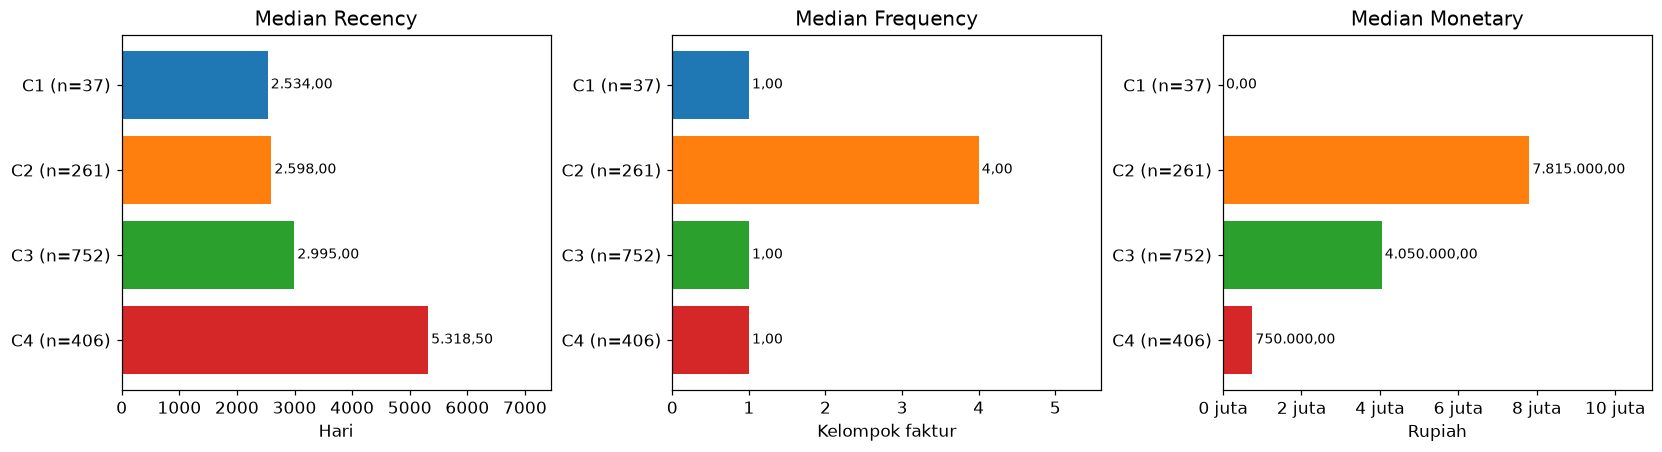

C1 memuat 37 dari 1.456 label (2,54%), dengan median Recency 2.534,00 hari, Frequency 1,00 kelompok, dan Monetary Rp0,00. Pola ini adalah dasar nama segmen pada tabel, bukan bukti keadaan pelanggan saat ini.

C2 memuat 261 dari 1.456 label (17,93%), dengan median Recency 2.598,00 hari, Frequency 4,00 kelompok, dan Monetary Rp7.815.000,00. Pola ini adalah dasar nama segmen pada tabel, bukan bukti keadaan pelanggan saat ini.

C3 memuat 752 dari 1.456 label (51,65%), dengan median Recency 2.995,00 hari, Frequency 1,00 kelompok, dan Monetary Rp4.050.000,00. Pola ini adalah dasar nama segmen pada tabel, bukan bukti keadaan pelanggan saat ini.

C4 memuat 406 dari 1.456 label (27,88%), dengan median Recency 5.318,50 hari, Frequency 1,00 kelompok, dan Monetary Rp750.000,00. Pola ini adalah dasar nama segmen pada tabel, bukan bukti keadaan pelanggan saat ini.

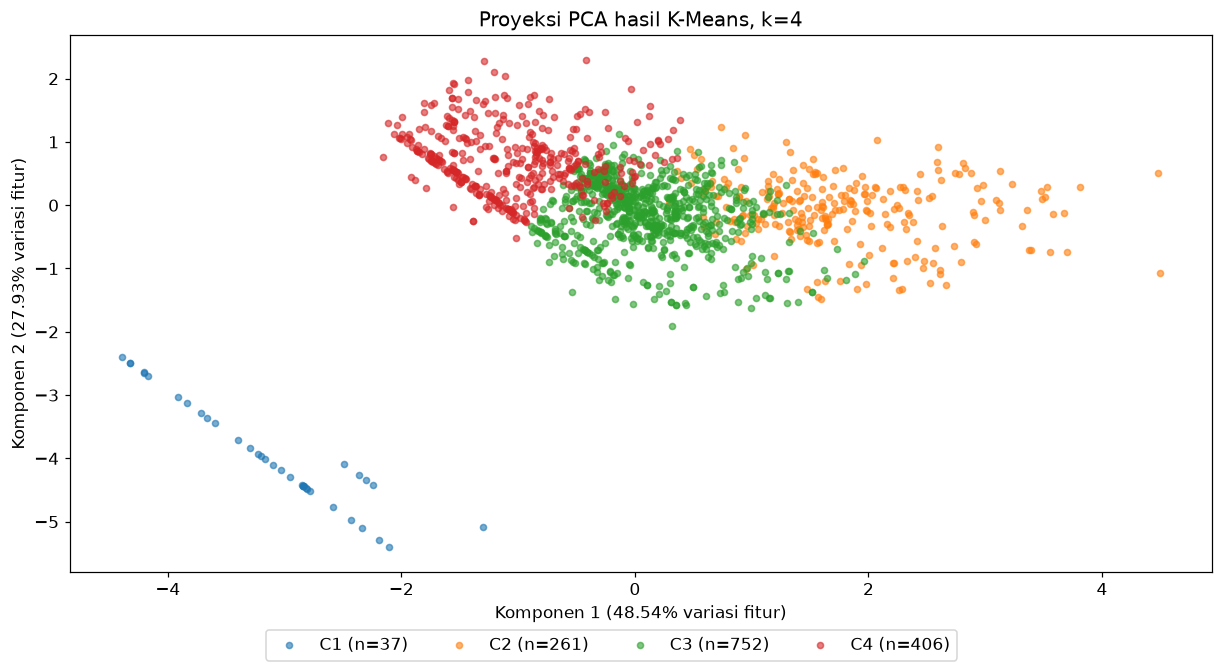

Dua komponen menampilkan 76.47% variasi tiga fitur standar. Titik yang tampak bertumpuk atau terpisah pada gambar dapat berubah ketika informasi komponen ketiga tidak ditampilkan; evaluasi model sebelumnya tetap memakai ketiga fitur.

In [36]:
palette_cluster_t4={cluster:plt.get_cmap('tab10')(i) for i,cluster in enumerate(profil_cluster_t4.index)}
fig,axes=plt.subplots(1,3,figsize=(15,max(4,k_terpilih_t4*.5)),layout='constrained')
for ax,column,title,unit in zip(axes,['median_Recency_hari','median_Frequency','median_Monetary_Rp'],['Median Recency','Median Frequency','Median Monetary'],['Hari','Kelompok faktur','Rupiah']):
    vals=profil_cluster_t4[column];limit=max(vals.max(),1)
    ax.barh(np.arange(len(vals)),vals,color=[palette_cluster_t4[c] for c in vals.index])
    ax.set_yticks(np.arange(len(vals)),[f'{c} (n={angka(profil_cluster_t4.loc[c,"jumlah_label"])})' for c in vals.index]);ax.invert_yaxis()
    ax.set_xlim(0,limit*1.4);ax.set(title=title,xlabel=unit)
    for i,v in enumerate(vals):ax.text(v+limit*.01,i,desimal_id(v),va='center',fontsize=9)
    if column=='median_Monetary_Rp':ax.xaxis.set_major_formatter(FuncFormatter(lambda x,pos:f'{x/1e6:g} juta'))
finish(fig)
for cluster,row in profil_cluster_t4.iterrows():
    note(f'{cluster} memuat {angka(row.jumlah_label)} dari {angka(len(input_t4))} label ({pct(row.jumlah_label,len(input_t4))}), dengan median Recency {desimal_id(row.median_Recency_hari)} hari, Frequency {desimal_id(row.median_Frequency)} kelompok, dan Monetary Rp{desimal_id(row.median_Monetary_Rp)}. Pola ini adalah dasar nama segmen pada tabel, bukan bukti keadaan pelanggan saat ini.')
pca_t4=PCA(n_components=2,svd_solver='full')
projection_t4=pca_t4.fit_transform(X_t4)
fig,ax=plt.subplots(figsize=(11,6),layout='constrained')
for cluster in profil_cluster_t4.index:
    mask=hasil_cluster_pelanggan.cluster.eq(cluster).to_numpy()
    ax.scatter(projection_t4[mask,0],projection_t4[mask,1],s=16,alpha=.6,color=palette_cluster_t4[cluster],label=f'{cluster} (n={int(mask.sum())})')
ax.set(title=f'Proyeksi PCA hasil {model_terpilih_t4}, k={k_terpilih_t4}',
 xlabel=f'Komponen 1 ({100*pca_t4.explained_variance_ratio_[0]:.2f}% variasi fitur)',
 ylabel=f'Komponen 2 ({100*pca_t4.explained_variance_ratio_[1]:.2f}% variasi fitur)')
fig.legend(*ax.get_legend_handles_labels(),loc='outside lower center',ncol=min(4,k_terpilih_t4));finish(fig)
note(f'Dua komponen menampilkan {100*pca_t4.explained_variance_ratio_.sum():.2f}% variasi tiga fitur standar. Titik yang tampak bertumpuk atau terpisah pada gambar dapat berubah ketika informasi komponen ketiga tidak ditampilkan; evaluasi model sebelumnya tetap memakai ketiga fitur.')

Warna dan kode cluster menghubungkan gambar ke tabel profil. PCA menampilkan **76,47%** variasi tiga fitur standar pada eksekusi ini; sisanya tidak terlihat pada dua sumbu, sehingga tumpang tindih di gambar bukan bukti semua informasi cluster telah ditampilkan. Model dan metrik tetap menggunakan tiga fitur, sementara nama serta tindakan segmen dibaca dari RFM asli.

## Memeriksa keanggotaan dan menjaga jejak sumber
Setiap ID yang dilatih harus memperoleh tepat satu cluster. Jumlah anggota, total Monetary, dan nilai RFM per ID dicocokkan kembali; tabel serta flag Tahap 1–3 harus tetap utuh. Label dengan nominal terakhir belum pasti tetap ada di hasil.

Jika hasil akhir adalah GMM, probabilitas keanggotaan tertinggi diringkas per cluster: median, persentil 10, minimum, serta jumlah dengan probabilitas di bawah 0,8. Batas 0,8 hanya penanda eksploratif. Probabilitas mencerminkan keyakinan model dalam pembagian komponen, bukan peluang segmen bisnis itu benar. Model selain GMM tidak diberi probabilitas buatan.
Angka utama pada narasi juga dicocokkan dengan hasil eksekusi workbook ini. Jika parameter atau data diubah, pemeriksaan ini membantu menandai bahwa narasi perlu ditinjau ulang.

In [37]:
if model_terpilih_t4=='GMM':
    probabilities_t4=model_t4[key_terpilih_t4].predict_proba(X_t4)
    assert np.allclose(probabilities_t4.sum(axis=1),1)
    assert np.array_equal(probabilities_t4.argmax(axis=1),labels_akhir_native_t4)
    hasil_cluster_pelanggan['probabilitas_keanggotaan_tertinggi']=probabilities_t4.max(axis=1)
    confidence_t4=hasil_cluster_pelanggan.groupby('cluster')['probabilitas_keanggotaan_tertinggi'].agg(jumlah_label='size',minimum='min',median='median',persentil_10=lambda s:s.quantile(.1),label_di_bawah_08=lambda s:int(s.lt(.8).sum()))
    confidence_t4['persen_di_bawah_08']=100*confidence_t4.label_di_bawah_08/confidence_t4.jumlah_label
    show_decimal_2b(confidence_t4)
    note('Probabilitas rendah menunjukkan anggota yang kurang tegas menurut komponen GMM ini. Angka tinggi tetap bukan verifikasi identitas pelanggan atau kebenaran segmen bisnis.')
else:
    print('Model akhir bukan GMM; probabilitas keanggotaan GMM tidak dilaporkan sebagai probabilitas model akhir.')
assert hasil_cluster_pelanggan.index.is_unique and hasil_cluster_pelanggan.index.equals(input_t4.index)
assert hasil_cluster_pelanggan.cluster.notna().all() and hasil_cluster_pelanggan.cluster.nunique()==k_terpilih_t4
assert len(hasil_cluster_pelanggan)==1456 and profil_cluster_t4.jumlah_label.sum()==1456
pd.testing.assert_frame_equal(hasil_cluster_pelanggan[fitur_t4],input_t4)
assert abs(hasil_cluster_pelanggan.Monetary.sum()-rfm_pelanggan.Monetary.sum())<=.01
assert int(hasil_cluster_pelanggan.Monetary.eq(0).sum())==int(rfm_pelanggan.Monetary.eq(0).sum())==37
assert hasil_cluster_pelanggan.nominal_faktur_terakhir_Rp.isna().sum()==19
for name,before in snapshot_t4.items():pd.testing.assert_frame_equal(globals()[name],before)
pd.testing.assert_frame_equal(pd.DataFrame(flags_t2),flags_before_t4)
assert blocking_t2==blocking_before_t4
assert raw_t2.equals(df_raw) and df_raw.equals(raw_snapshot)
assert hashlib.sha256(SOURCE.read_bytes()).hexdigest()==source_hash_t2
validasi_akhir_t4=pd.DataFrame({'pemeriksaan':['Label dilatih','Label mendapat satu cluster','Jumlah anggota semua cluster','Total Monetary (Rp)','Monetary nol tetap ada','Nominal terakhir belum pasti tetap ada','Tabel RFM/cleaning dan flag'],
 'hasil':[angka(len(input_t4)),angka(len(hasil_cluster_pelanggan)),angka(profil_cluster_t4.jumlah_label.sum()),'Rp'+desimal_id(hasil_cluster_pelanggan.Monetary.sum()),'37 label','19 label','Tidak berubah']})
display(validasi_akhir_t4)
print('LULUS: seluruh label memiliki cluster; RFM asli, profil, cleaning, dan workbook tetap dapat ditelusuri.')
# Verify the numerical claims used in the saved explanations.
assert (model_terpilih_t4,k_terpilih_t4)==('K-Means',4)
assert profil_cluster_t4.jumlah_label.astype(int).tolist()==[37,261,752,406]
assert int(profil_cluster_t4.label_Monetary_nol.sum())==37
assert tindakan_segmen_t4.nama_segmen.nunique()==k_terpilih_t4
assert np.isclose(selected_row_t4.silhouette,.4009058374,atol=1e-7)
assert np.isclose(selected_row_t4.davies_bouldin,.7646497643,atol=1e-7)
assert np.isclose(selected_row_t4.calinski_harabasz,1151.8220304646,atol=1e-5)
assert round(100*pca_t4.explained_variance_ratio_.sum(),2)==76.47

Model akhir bukan GMM; probabilitas keanggotaan GMM tidak dilaporkan sebagai probabilitas model akhir.


,pemeriksaan,hasil
0,Label dilatih,1.456
1,Label mendapat satu cluster,1.456
2,Jumlah anggota semua cluster,1.456
3,Total Monetary (Rp),"Rp8.225.196.662,39"
4,Monetary nol tetap ada,37 label
5,Nominal terakhir belum pasti tetap ada,19 label
6,Tabel RFM/cleaning dan flag,Tidak berubah


LULUS: seluruh label memiliki cluster; RFM asli, profil, cleaning, dan workbook tetap dapat ditelusuri.


Seluruh **1.456 ID samaran** memiliki tepat satu cluster, dan jumlah anggota serta total Monetary **Rp8.225.196.662,39** kembali cocok dengan sumber. Semua **37 Monetary nol** dan **19 nominal terakhir belum pasti** tetap ada; tabel cleaning, RFM, profil, dan flag tidak berubah. Karena model akhir K-Means, tidak ada probabilitas GMM yang disajikan seolah-olah milik model akhir. Keberhasilan pemeriksaan tidak mengesahkan identitas pelanggan atau memulihkan transaksi yang ditahan.

## Kesimpulan hasil dan batas penggunaannya
Ringkasan akhir menggabungkan model terpilih, skor, ukuran segmen, dan tindakan yang didukung profil. Seluruh analisis memakai riwayat **8 Desember 2006–8 Juli 2026**, dengan acuan Recency **9 Juli 2026**, dari kelompok yang lolos aturan awal. Kelompok tertahan dan tiga tambahan simulasi Rp1.000 tidak dimasukkan.

Nama standar tetap label sementara. Hasil menunjukkan pola pada subset historis, bukan daftar pelanggan yang dipastikan masih aktif atau sudah berhenti berbelanja. Tindakan yang disarankan perlu dimulai dari validasi identitas dan riwayat terbaru.

In [38]:
kesimpulan_t4=pd.DataFrame([
 ['Pilihan akhir',f'{model_terpilih_t4}, k={k_terpilih_t4}'],
 ['Alasan kuantitatif',f'Rata-rata peringkat tiga metrik {selected_row_t4.rata_rank:.2f}; Silhouette {selected_row_t4.silhouette:.3f}; DB {selected_row_t4.davies_bouldin:.3f}; CH {selected_row_t4.calinski_harabasz:.1f}'],
 ['Ukuran segmen',f'Terkecil {int(selected_row_t4.cluster_min)} dan terbesar {int(selected_row_t4.cluster_max)} label; semua {len(input_t4)} label tetap dipakai'],
 ['Cakupan',f'{len(input_t4)} label sementara; {len(faktur_lolos)} kelompok faktur dari {len(item_lolos)} item, 08-12-2006 sampai 08-07-2026'],
 ['Sumber RFM','Aturan awal Tahap 2; tanpa filter tahun; grand total sekali per kelompok; 37 Monetary nol dipertahankan'],
 ['Batas model','Metrik internal tidak membuktikan segmen bisnis benar; hasil tergantung log1p, standardisasi, k yang diuji, dan aturan pemilihan'],
 ['Batas identitas/cakupan','Nama standar bukan ID pelanggan; kelompok ditahan tidak masuk RFM; nominal terakhir 19 label belum pasti'],
 ['Tindak lanjut','Konfirmasi identitas, riwayat terbaru dan definisi nominal sebelum uji tindakan per segmen']
],columns=['pokok','hasil_dan_batas'])
display(HTML(kesimpulan_t4.to_html(index=False)))
ringkasan_segmen_t4=profil_cluster_t4[['nama_segmen','jumlah_label','persen_label','median_Recency_hari','median_Frequency','median_Monetary_Rp']].copy()
ringkasan_segmen_t4['tindakan_utama']=tindakan_segmen_t4['contoh_tindakan']
show_decimal_2b(ringkasan_segmen_t4)
note(f'Notebook berakhir dengan {model_terpilih_t4} dan {k_terpilih_t4} segmen eksploratif. GMM diuji sebagai model utama yang direncanakan, tetapi keputusan akhir mengikuti evaluasi serta profil yang dapat dibaca; tidak ada asumsi bahwa model yang direncanakan pasti menang.')

pokok,hasil_dan_batas
Pilihan akhir,"K-Means, k=4"
Alasan kuantitatif,Rata-rata peringkat tiga metrik 2.00; Silhouette 0.401; DB 0.765; CH 1151.8
Ukuran segmen,Terkecil 37 dan terbesar 752 label; semua 1456 label tetap dipakai
Cakupan,"1456 label sementara; 2874 kelompok faktur dari 6083 item, 08-12-2006 sampai 08-07-2026"
Sumber RFM,Aturan awal Tahap 2; tanpa filter tahun; grand total sekali per kelompok; 37 Monetary nol dipertahankan
Batas model,"Metrik internal tidak membuktikan segmen bisnis benar; hasil tergantung log1p, standardisasi, k yang diuji, dan aturan pemilihan"
Batas identitas/cakupan,Nama standar bukan ID pelanggan; kelompok ditahan tidak masuk RFM; nominal terakhir 19 label belum pasti
Tindak lanjut,"Konfirmasi identitas, riwayat terbaru dan definisi nominal sebelum uji tindakan per segmen"


,nama_segmen,jumlah_label,persen_label,median_Recency_hari,median_Frequency,median_Monetary_Rp,tindakan_utama
cluster,,,,,,,
C1,Nominal belanja tercatat nol,37,"2,54","2.534,00","1,00","0,00",Telusuri arti grand total nol dan dokumen sumber sebelum menetapkan tindakan komersial; jangan menganggap label ini tanpa nilai bisnis.
C2,"Pembelian berulang, belanja lebih tinggi",261,"17,93","2.598,00","4,00","7.815.000,00","Setelah memastikan identitas dan kebutuhan terkini, uji rekomendasi atau bundling produk pelengkap pada label dengan pembelian berulang."
C3,"Frekuensi rendah, belanja di atas median",752,"51,65","2.995,00","1,00","4.050.000,00",Validasi kebutuhan terkini lalu uji penawaran pembelian ulang atau produk pelengkap; Frequency rendah hanya menggambarkan kelompok yang lolos.
C4,"Riwayat lebih lama, belanja relatif rendah",406,"27,88","5.318,50","1,00","750.000,00","Periksa riwayat terbaru dan kesesuaian label terlebih dahulu; bila masih relevan, uji komunikasi berbiaya rendah, bukan menyimpulkan sudah berhenti belanja."


Notebook berakhir dengan K-Means dan 4 segmen eksploratif. GMM diuji sebagai model utama yang direncanakan, tetapi keputusan akhir mengikuti evaluasi serta profil yang dapat dibaca; tidak ada asumsi bahwa model yang direncanakan pasti menang.

**Hasil akhir adalah K-Means dengan 4 segmen eksploratif.** C1 diarahkan ke validasi nominal nol; C2 ke uji produk pelengkap untuk pembelian berulang; C3 ke uji pembelian ulang setelah kebutuhan terkini dipastikan; C4 ke validasi riwayat terbaru sebelum komunikasi berbiaya rendah. Usulan ini mengikuti median dan jumlah anggota pada tabel, bukan dugaan pelanggan sudah berhenti belanja.

Analisis memakai seluruh **2.874 kelompok faktur lolos dari 6.083 item**, dengan rentang **8 Desember 2006–8 Juli 2026** dan acuan Recency **9 Juli 2026**. Nama standar masih label sementara; kelompok tertahan tidak masuk RFM, dan simulasi Rp1.000 tidak mengubah cakupan. Pilihan log1p, standardisasi, jarak, kandidat k=2–8, serta aturan peringkat memengaruhi hasil; metrik internal belum menjadi validasi bisnis atau jaminan keadaan pelanggan saat ini.

**Tahap 4 adalah bagian terakhir notebook.** Hasil, parameter, tabel evaluasi, profil, dan jejak ID disimpan agar dapat ditinjau sebelum tindakan bisnis atau penggunaan lanjutan.